# Fatigue factors and sleep duration(睡眠時間と疲労要因の分析)

RQ:How does the effect of each behavioural factor (e.g., bedtime phone use, caffeine) on next-day fatigue change with sleep duration?

RQ(日本語):寝る前のスマホ利用やカフェインなどの各要素が翌日の疲労に与える影響は、睡眠時間によってどのように変わるか？

## Step 1:Data collection(データ収集)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 日本語を表示するためのフォント（macOS）
plt.rcParams["font.family"] = "Hiragino Sans"

# データの読み込み
DATA_PATH = "bedtime_screentime_sleep_debt.csv"
df = pd.read_csv(DATA_PATH)

print(f"Rows(行数):{df.shape[0]}")
print(f"Columns(列数):{df.shape[1]}")
print("Column names(列名):")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}.{col}")

Rows(行数):8500
Columns(列数):18
Column names(列名):
1.user_id
2.age
3.gender
4.occupation_type
5.chronotype
6.bedtime_phone_minutes
7.primary_bedtime_app
8.screen_brightness_pct
9.blue_light_filter_active
10.caffeine_post_5pm_mg
11.physical_activity_min
12.sleep_latency_min
13.total_sleep_hours
14.deep_sleep_pct
15.rem_sleep_pct
16.morning_alarm_snoozes
17.next_day_fatigue_score
18.sleep_debt_category


In [2]:
# 先頭5行の確認
df.head()

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


## Step 2:Data understanding(データの理解)

In [3]:
# 型、欠損値、重複
info = pd.DataFrame({
    "Data type(型)": df.dtypes.astype(str),
    "Missing(欠損数)": df.isna().sum(),
})
print("Data types and missing values(型と欠損値):")
print(info.to_string())
print(f"Total missing(欠損数の合計):{df.isna().sum().sum()}")

# 重複の確認
print(f"Duplicated user_id(user_idの重複数):{df['user_id'].duplicated().sum()}")
print(f"Duplicated rows(完全に同じ行の数):{df.duplicated().sum()}")
print(f"Duplicated rows without user_id(user_id以外が同じ行の数):{df.drop(columns='user_id').duplicated().sum()}")

Data types and missing values(型と欠損値):
                         Data type(型)  Missing(欠損数)
user_id                           str             0
age                             int64             0
gender                            str             0
occupation_type                   str             0
chronotype                        str             0
bedtime_phone_minutes           int64             0
primary_bedtime_app               str             0
screen_brightness_pct           int64             0
blue_light_filter_active        int64             0
caffeine_post_5pm_mg            int64             0
physical_activity_min           int64             0
sleep_latency_min             float64             0
total_sleep_hours             float64             0
deep_sleep_pct                float64             0
rem_sleep_pct                 float64             0
morning_alarm_snoozes           int64             0
next_day_fatigue_score        float64             0
sleep_debt_category       

Descriptive statistics(記述統計):
                           count       mean        std   min    25%    50%    75%    max
age                       8500.0  34.355647  11.584259  18.0  25.00  32.00  42.00   65.0
bedtime_phone_minutes     8500.0  59.250000  36.931991   1.0  31.00  51.00  79.00  180.0
screen_brightness_pct     8500.0  55.153882  19.850550  10.0  42.00  55.00  69.00  100.0
blue_light_filter_active  8500.0   0.467765   0.498989   0.0   0.00   0.00   1.00    1.0
caffeine_post_5pm_mg      8500.0  33.222471  51.935645   0.0   0.00   0.00  55.00  250.0
physical_activity_min     8500.0  35.701412  20.819390   0.0  21.00  35.00  50.00  112.0
sleep_latency_min         8500.0  40.671471  17.444914   6.0  28.20  37.60  49.70  123.3
total_sleep_hours         8500.0   6.266209   1.446258   3.2   5.24   6.33   7.35    9.8
deep_sleep_pct            8500.0  21.735741   3.069377   8.1  19.70  21.90  23.90   28.0
rem_sleep_pct             8500.0  19.105859   2.546459   9.6  17.40  19.10  20.8

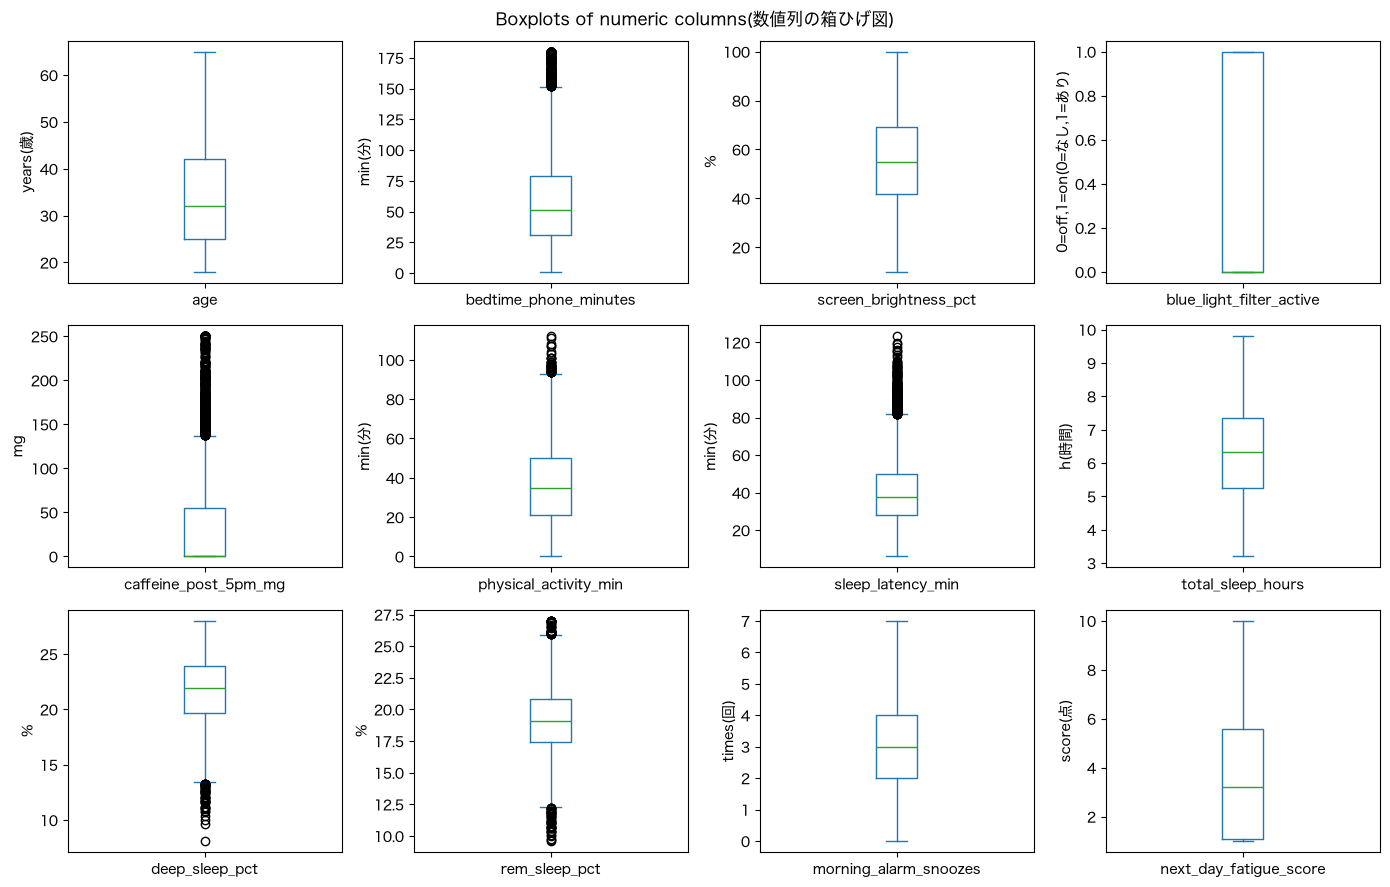

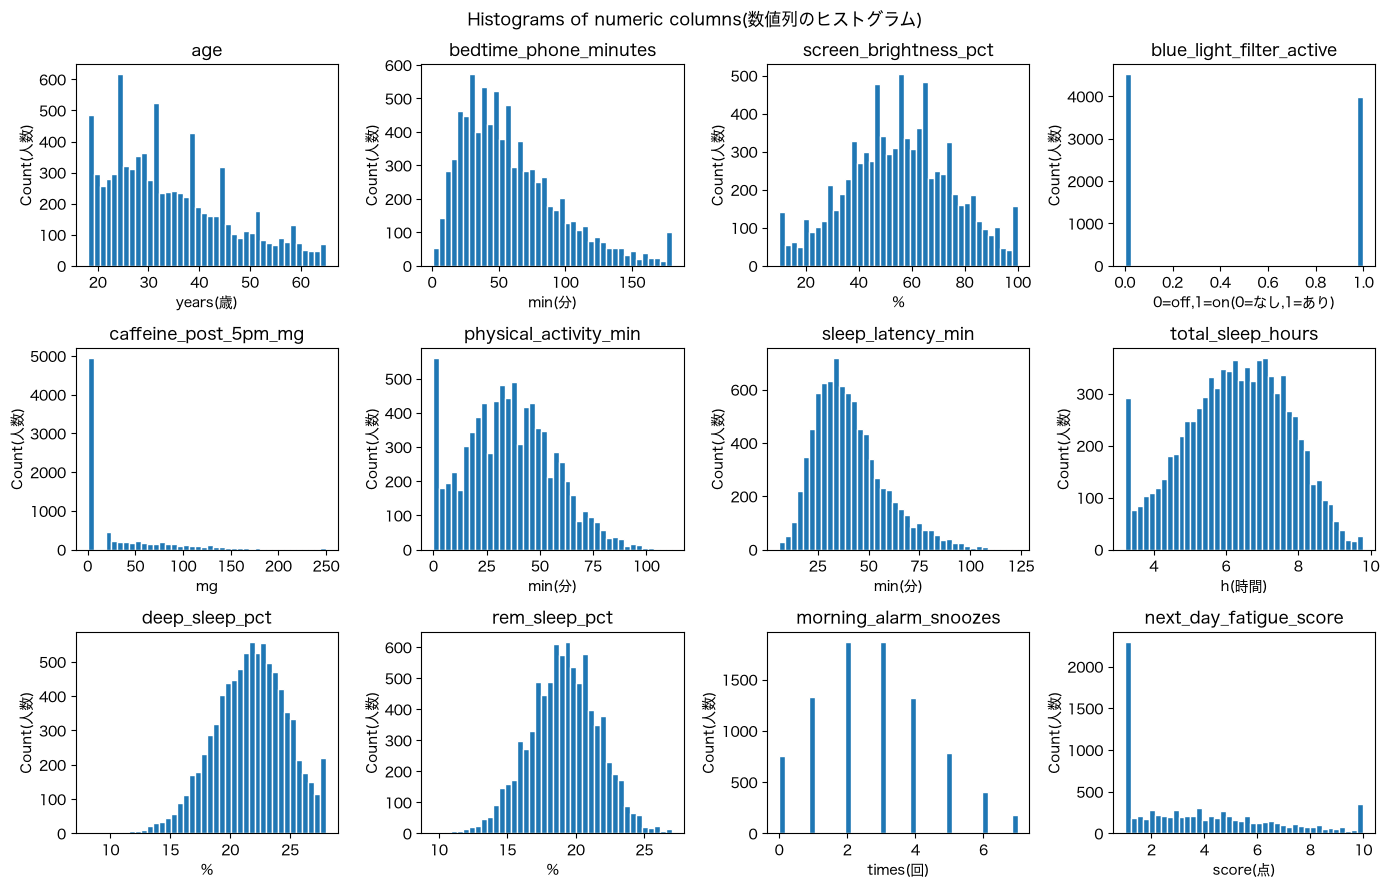

Correlation matrix(相関行列):
                            age  bedtime_phone_minutes  screen_brightness_pct  blue_light_filter_active  caffeine_post_5pm_mg  physical_activity_min  sleep_latency_min  total_sleep_hours  deep_sleep_pct  rem_sleep_pct  morning_alarm_snoozes  next_day_fatigue_score
age                       1.000                 -0.016                 -0.005                     0.004                -0.007                 -0.013             -0.055              0.016           0.011          0.070                 -0.026                  -0.028
bedtime_phone_minutes    -0.016                  1.000                  0.001                     0.001                -0.008                 -0.008              0.858             -0.554          -0.262         -0.009                  0.652                   0.711
screen_brightness_pct    -0.005                  0.001                  1.000                     0.007                 0.002                  0.001              0.093            

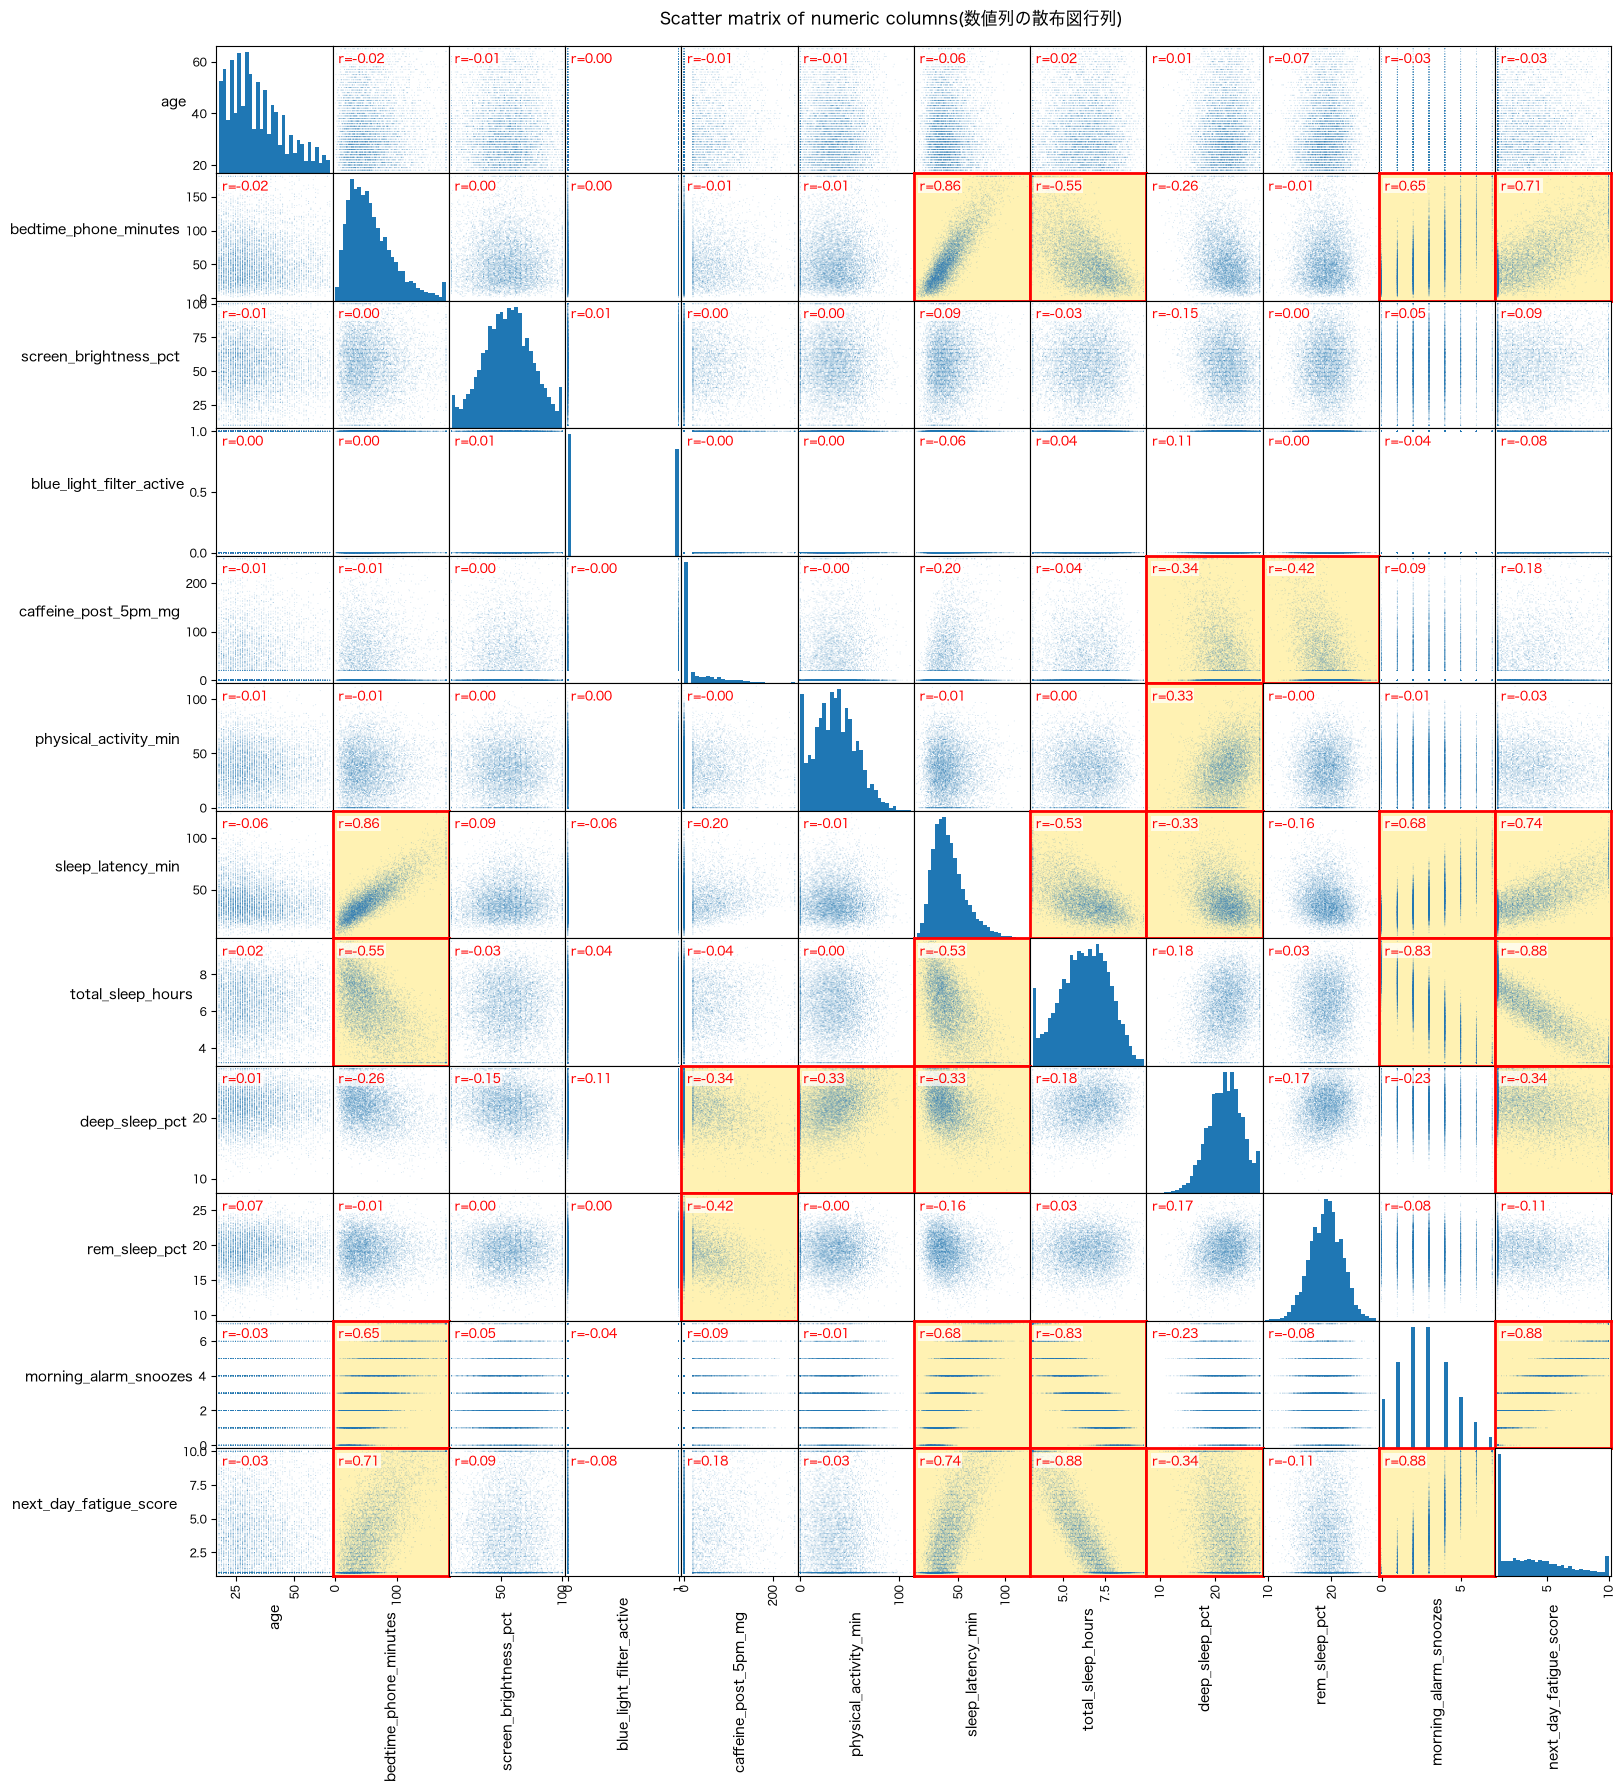

In [4]:
# 数値列の記述統計
print("Descriptive statistics(記述統計):")
print(df.describe().T.to_string())

num_cols = df.select_dtypes(include="number").columns

# 各列の単位
UNITS = {
    "age": "years(歳)",
    "bedtime_phone_minutes": "min(分)",
    "screen_brightness_pct": "%",
    "blue_light_filter_active": "0=off,1=on(0=なし,1=あり)",
    "caffeine_post_5pm_mg": "mg",
    "physical_activity_min": "min(分)",
    "sleep_latency_min": "min(分)",
    "total_sleep_hours": "h(時間)",
    "deep_sleep_pct": "%",
    "rem_sleep_pct": "%",
    "morning_alarm_snoozes": "times(回)",
    "next_day_fatigue_score": "score(点)",
}

# 数値列の箱ひげ図（単位が列ごとに違うので、列ごとに軸を分ける）
axes = df[num_cols].plot.box(subplots=True, layout=(3, 4), figsize=(14, 9), sharey=False)
for col in num_cols:
    axes[col].set_ylabel(UNITS[col])
plt.suptitle("Boxplots of numeric columns(数値列の箱ひげ図)")
plt.tight_layout()
plt.show()

# 数値列のヒストグラム
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, col in zip(axes.flatten(), num_cols):
    df[col].plot.hist(bins=40, ax=ax, edgecolor="white")
    ax.set_title(col)
    ax.set_xlabel(UNITS[col])
    ax.set_ylabel("Count(人数)")
plt.suptitle("Histograms of numeric columns(数値列のヒストグラム)")
plt.tight_layout()
plt.show()

# 数値列どうしの相関係数（ピアソン）
corr = df[num_cols].corr()
print("Correlation matrix(相関行列):")
print(corr.round(3).to_string())

# 散布図行列（総当たりの散布図。対角はヒストグラム）
axes = pd.plotting.scatter_matrix(df[num_cols], figsize=(18, 18), s=2, alpha=0.2, hist_kwds={"bins": 30})
# 対角以外の各グラフに相関係数を書き、|r|が0.3を超える枠は背景色と太枠で強調する
CORR_THRESHOLD = 0.3
for i, row_col in enumerate(num_cols):
    for j, col_col in enumerate(num_cols):
        if i != j:
            if abs(corr.loc[row_col, col_col]) > CORR_THRESHOLD:
                axes[i, j].set_facecolor("#fff2b3")
                for spine in axes[i, j].spines.values():
                    spine.set_edgecolor("red")
                    spine.set_linewidth(2)
            axes[i, j].text(0.05, 0.95, f"r={corr.loc[row_col, col_col]:.2f}", transform=axes[i, j].transAxes,
                            fontsize=9, va="top", color="red", bbox={"facecolor": "white", "alpha": 0.7, "edgecolor": "none", "pad": 1})
for ax in axes.flatten():
    ax.xaxis.label.set_rotation(90)
    ax.yaxis.label.set_rotation(0)
    ax.yaxis.label.set_horizontalalignment("right")
plt.subplots_adjust(top=0.96)
plt.suptitle("Scatter matrix of numeric columns(数値列の散布図行列)", y=0.98)
plt.show()

In [5]:
# カテゴリ列の内訳
cat_cols = df.select_dtypes(include="object").columns.drop("user_id")
for col in cat_cols:
    print(f"{col}(件数):")
    print(df[col].value_counts().to_string())
    print()

gender(件数):
gender
Female        4347
Male          3905
Non-Binary     248

occupation_type(件数):
occupation_type
Corporate 9-to-5             2838
Remote Tech                  2142
Student                      1622
Healthcare / Shift Worker     997
Freelance / Creative          901

chronotype(件数):
chronotype
Intermediate    3880
Night Owl       2455
Morning Lark    2165

primary_bedtime_app(件数):
primary_bedtime_app
TikTok / Reels              2198
YouTube                     1928
Instagram / Reddit          1630
Streaming (Netflix/Hulu)    1301
Messaging / Chat             847
News / Reading               596

sleep_debt_category(件数):
sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647



/var/folders/mm/_5w683_97v5d55mx3whv5c3c0000gn/T/ipykernel_85206/2387084741.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.drop("user_id")


Fatigue=10.0 count(疲労10.0の人数):314
Fatigue=10.0 ratio(疲労10.0の割合):0.0369
Fatigue=1.0 count(疲労1.0の人数):2110
Fatigue=1.0 ratio(疲労1.0の割合):0.2482
Sleep=3.2h count(睡眠3.2時間の人数):242
Sleep=9.8h count(睡眠9.8時間の人数):17

Fatigue at bounds by sleep group(睡眠時間グループ別の上限・下限の人数):
                       N(人数)  Fatigue=10.0(疲労10.0)  Fatigue=1.0(疲労1.0)  Ratio 10.0(10.0の割合)  Ratio 1.0(1.0の割合)
Sleep group(睡眠時間グループ)                                                                                         
-5h                     1713                   309                   0               0.1804             0.0000
5-6h                    1820                     5                   4               0.0027             0.0022
6-7h                    2097                     0                 186               0.0000             0.0887
7-8h                    1887                     0                 989               0.0000             0.5241
8h+                      983                     0                 931     

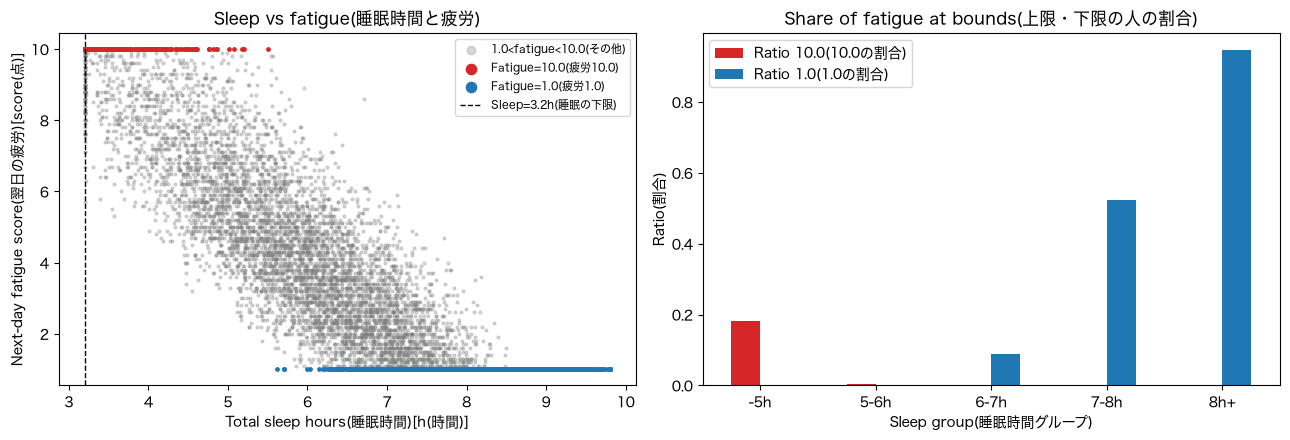

In [6]:
# 疲労スコアの上限10.0・下限1.0と、睡眠時間の上限・下限
TARGET = "next_day_fatigue_score"
SLEEP = "total_sleep_hours"
is_top = df[TARGET] == 10.0
is_bottom = df[TARGET] == 1.0
print(f"Fatigue=10.0 count(疲労10.0の人数):{is_top.sum()}")
print(f"Fatigue=10.0 ratio(疲労10.0の割合):{is_top.mean():.4f}")
print(f"Fatigue=1.0 count(疲労1.0の人数):{is_bottom.sum()}")
print(f"Fatigue=1.0 ratio(疲労1.0の割合):{is_bottom.mean():.4f}")
print(f"Sleep=3.2h count(睡眠3.2時間の人数):{(df[SLEEP] == 3.2).sum()}")
print(f"Sleep=9.8h count(睡眠9.8時間の人数):{(df[SLEEP] == 9.8).sum()}")
print()

# 睡眠時間グループごとの、上限・下限に張り付いた人数と割合
# 区切りは Step 4 の睡眠時間グループと同じ1時間刻み（左閉じ・右開き）
bins = [0, 5, 6, 7, 8, 24]
labels = ["-5h", "5-6h", "6-7h", "7-8h", "8h+"]
sleep_bin = pd.cut(df[SLEEP], bins=bins, labels=labels, right=False)
bound_table = pd.DataFrame({
    "N(人数)": is_top.groupby(sleep_bin, observed=False).size(),
    "Fatigue=10.0(疲労10.0)": is_top.groupby(sleep_bin, observed=False).sum(),
    "Fatigue=1.0(疲労1.0)": is_bottom.groupby(sleep_bin, observed=False).sum(),
    "Ratio 10.0(10.0の割合)": is_top.groupby(sleep_bin, observed=False).mean().round(4),
    "Ratio 1.0(1.0の割合)": is_bottom.groupby(sleep_bin, observed=False).mean().round(4),
})
bound_table.index.name = "Sleep group(睡眠時間グループ)"
print("Fatigue at bounds by sleep group(睡眠時間グループ別の上限・下限の人数):")
print(bound_table.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 左：睡眠時間と疲労の散布図。上限・下限に張り付いた点を色分けする
is_mid = ~(is_top | is_bottom)
axes[0].scatter(df.loc[is_mid, SLEEP], df.loc[is_mid, TARGET], s=4, alpha=0.3, color="gray", label="1.0<fatigue<10.0(その他)")
axes[0].scatter(df.loc[is_top, SLEEP], df.loc[is_top, TARGET], s=6, color="tab:red", label="Fatigue=10.0(疲労10.0)")
axes[0].scatter(df.loc[is_bottom, SLEEP], df.loc[is_bottom, TARGET], s=6, color="tab:blue", label="Fatigue=1.0(疲労1.0)")
axes[0].axvline(3.2, color="black", linestyle="--", linewidth=1, label="Sleep=3.2h(睡眠の下限)")
axes[0].set_xlabel(f"Total sleep hours(睡眠時間)[{UNITS[SLEEP]}]")
axes[0].set_ylabel(f"Next-day fatigue score(翌日の疲労)[{UNITS[TARGET]}]")
axes[0].set_title("Sleep vs fatigue(睡眠時間と疲労)")
axes[0].legend(fontsize=8, markerscale=3)

# 右：グループごとの、上限・下限に張り付いた人の割合
bound_table[["Ratio 10.0(10.0の割合)", "Ratio 1.0(1.0の割合)"]].plot.bar(ax=axes[1], color=["tab:red", "tab:blue"], rot=0)
axes[1].set_xlabel("Sleep group(睡眠時間グループ)")
axes[1].set_ylabel("Ratio(割合)")
axes[1].set_title("Share of fatigue at bounds(上限・下限の人の割合)")

plt.tight_layout()
plt.show()

gender:
            N(人数)  Fatigue mean(疲労の平均)  Fatigue std(疲労の標準偏差)  Sleep mean(睡眠時間の平均)  Sleep std(睡眠時間の標準偏差)
gender                                                                                                 
Female       4347                3.795                 2.677                6.263                 1.445
Male         3905                3.798                 2.687                6.267                 1.442
Non-Binary    248                3.743                 2.796                6.306                 1.531

occupation_type:
                           N(人数)  Fatigue mean(疲労の平均)  Fatigue std(疲労の標準偏差)  Sleep mean(睡眠時間の平均)  Sleep std(睡眠時間の標準偏差)
occupation_type                                                                                                       
Corporate 9-to-5            2838                3.573                 2.598                6.430                 1.386
Freelance / Creative         901                3.675                 2.651                6.376 

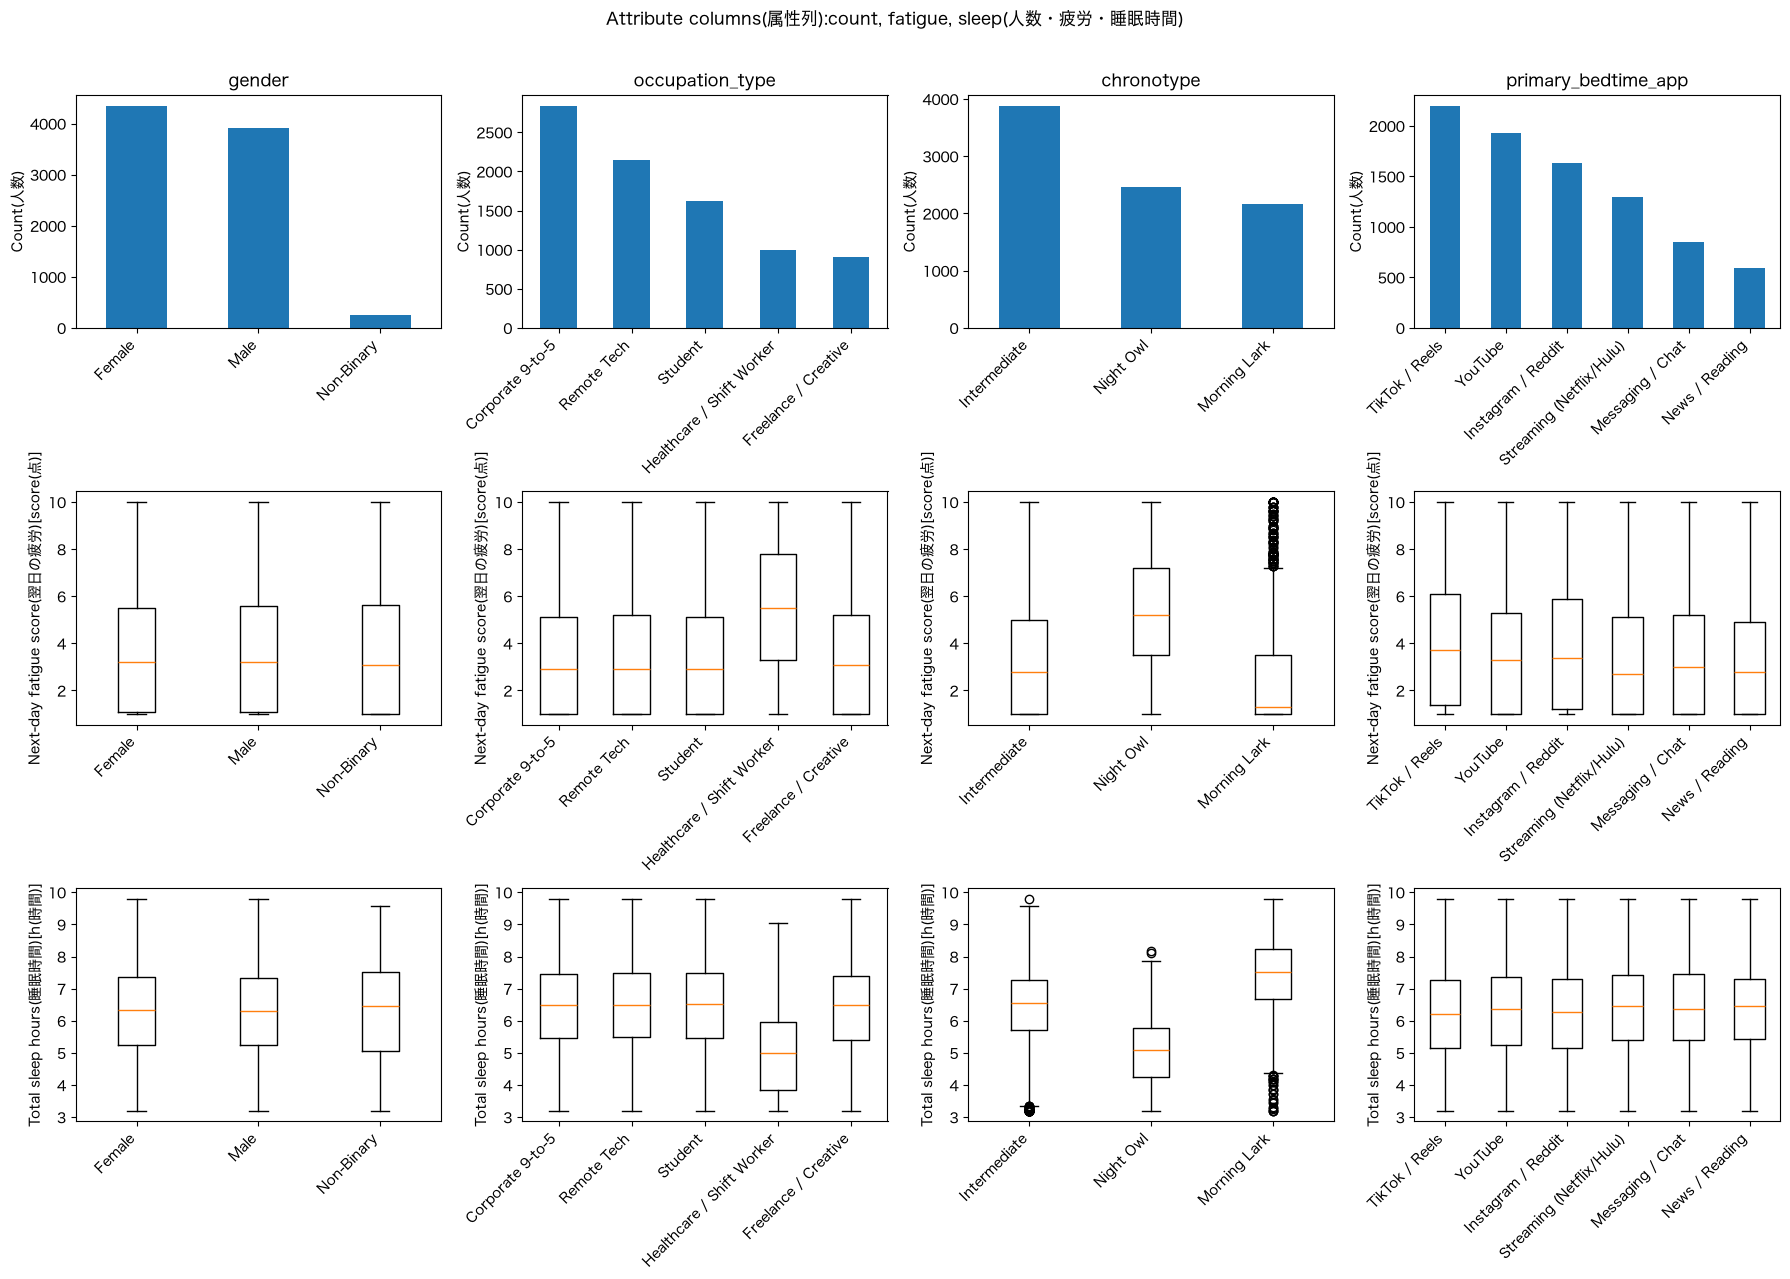

In [7]:
# 属性列（カテゴリ）ごとの人数、疲労、睡眠時間
# 年齢は数値列なので、上の箱ひげ図・ヒストグラム・散布図行列に含まれている
ATTR_COLS = ["gender", "occupation_type", "chronotype", "primary_bedtime_app"]
for col in ATTR_COLS:
    attr_table = df.groupby(col).agg(**{
        "N(人数)": (TARGET, "size"),
        "Fatigue mean(疲労の平均)": (TARGET, "mean"),
        "Fatigue std(疲労の標準偏差)": (TARGET, "std"),
        "Sleep mean(睡眠時間の平均)": (SLEEP, "mean"),
        "Sleep std(睡眠時間の標準偏差)": (SLEEP, "std"),
    }).round(3)
    print(f"{col}:")
    print(attr_table.to_string())
    print()

# 1行目：人数、2行目：疲労の箱ひげ図、3行目：睡眠時間の箱ひげ図
fig, axes = plt.subplots(3, len(ATTR_COLS), figsize=(18, 13))
for j, col in enumerate(ATTR_COLS):
    order = df[col].value_counts().index
    df[col].value_counts().plot.bar(ax=axes[0, j], rot=45)
    axes[0, j].set_title(col)
    axes[0, j].set_xlabel("")
    axes[0, j].set_ylabel("Count(人数)")
    for k, (y_col, y_label) in enumerate([(TARGET, "Next-day fatigue score(翌日の疲労)"), (SLEEP, "Total sleep hours(睡眠時間)")], start=1):
        axes[k, j].boxplot([df.loc[df[col] == v, y_col] for v in order], tick_labels=order)
        axes[k, j].tick_params(axis="x", rotation=45)
        axes[k, j].set_ylabel(f"{y_label}[{UNITS[y_col]}]")
for ax in axes.flatten():
    plt.setp(ax.get_xticklabels(), ha="right")
plt.suptitle("Attribute columns(属性列):count, fatigue, sleep(人数・疲労・睡眠時間)")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [8]:
# 属性列のカテゴリごとの平均、箱ひげ図、ヒストグラムを出す関数
def describe_by_attr(attr_col, categories=None):
    if categories is None:
        categories = df[attr_col].value_counts().index.tolist()
    colors = {c: plt.cm.tab10(i) for i, c in enumerate(categories)}
    sub = df[df[attr_col].isin(categories)]

    # カテゴリ別の平均と、カテゴリ間の幅（最大 - 最小）
    means = sub.groupby(attr_col)[num_cols].mean().T[categories]
    means["Range(幅:最大-最小)"] = means[categories].max(axis=1) - means[categories].min(axis=1)
    print(f"Mean by {attr_col}({attr_col}別の平均):")
    print(means.round(3).to_string())

    # 箱ひげ図：列ごとにカテゴリを並べる
    fig, axes = plt.subplots(3, 4, figsize=(16, 11))
    for ax, col in zip(axes.flatten(), num_cols):
        bp = ax.boxplot([sub.loc[sub[attr_col] == c, col] for c in categories], tick_labels=categories, patch_artist=True)
        for patch, c in zip(bp["boxes"], categories):
            patch.set_facecolor(colors[c])
            patch.set_alpha(0.5)
        ax.set_title(col)
        ax.set_ylabel(UNITS[col])
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    plt.suptitle(f"Boxplots by {attr_col}({attr_col}別の箱ひげ図)")
    plt.tight_layout()
    plt.show()

    # ヒストグラム：人数が違うので密度で、半透明にして重ねる
    fig, axes = plt.subplots(3, 4, figsize=(16, 10))
    for ax, col in zip(axes.flatten(), num_cols):
        for c in categories:
            sub.loc[sub[attr_col] == c, col].plot.hist(bins=40, ax=ax, density=True, alpha=0.4, color=colors[c], label=c)
        ax.set_title(col)
        ax.set_xlabel(UNITS[col])
        ax.set_ylabel("Density(密度)")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="center right")
    plt.suptitle(f"Histograms by {attr_col}({attr_col}別のヒストグラム)")
    plt.tight_layout(rect=[0, 0, 0.88, 1])
    plt.show()

Mean by gender(gender別の平均):
gender                      Male  Female  Range(幅:最大-最小)
age                       34.414  34.317           0.098
bedtime_phone_minutes     59.214  59.242           0.028
screen_brightness_pct     55.099  55.157           0.058
blue_light_filter_active   0.474   0.463           0.011
caffeine_post_5pm_mg      33.849  32.925           0.923
physical_activity_min     35.397  35.997           0.600
sleep_latency_min         40.721  40.666           0.055
total_sleep_hours          6.267   6.263           0.004
deep_sleep_pct            21.737  21.736           0.001
rem_sleep_pct             19.075  19.110           0.035
morning_alarm_snoozes      2.766   2.767           0.001
next_day_fatigue_score     3.798   3.795           0.003


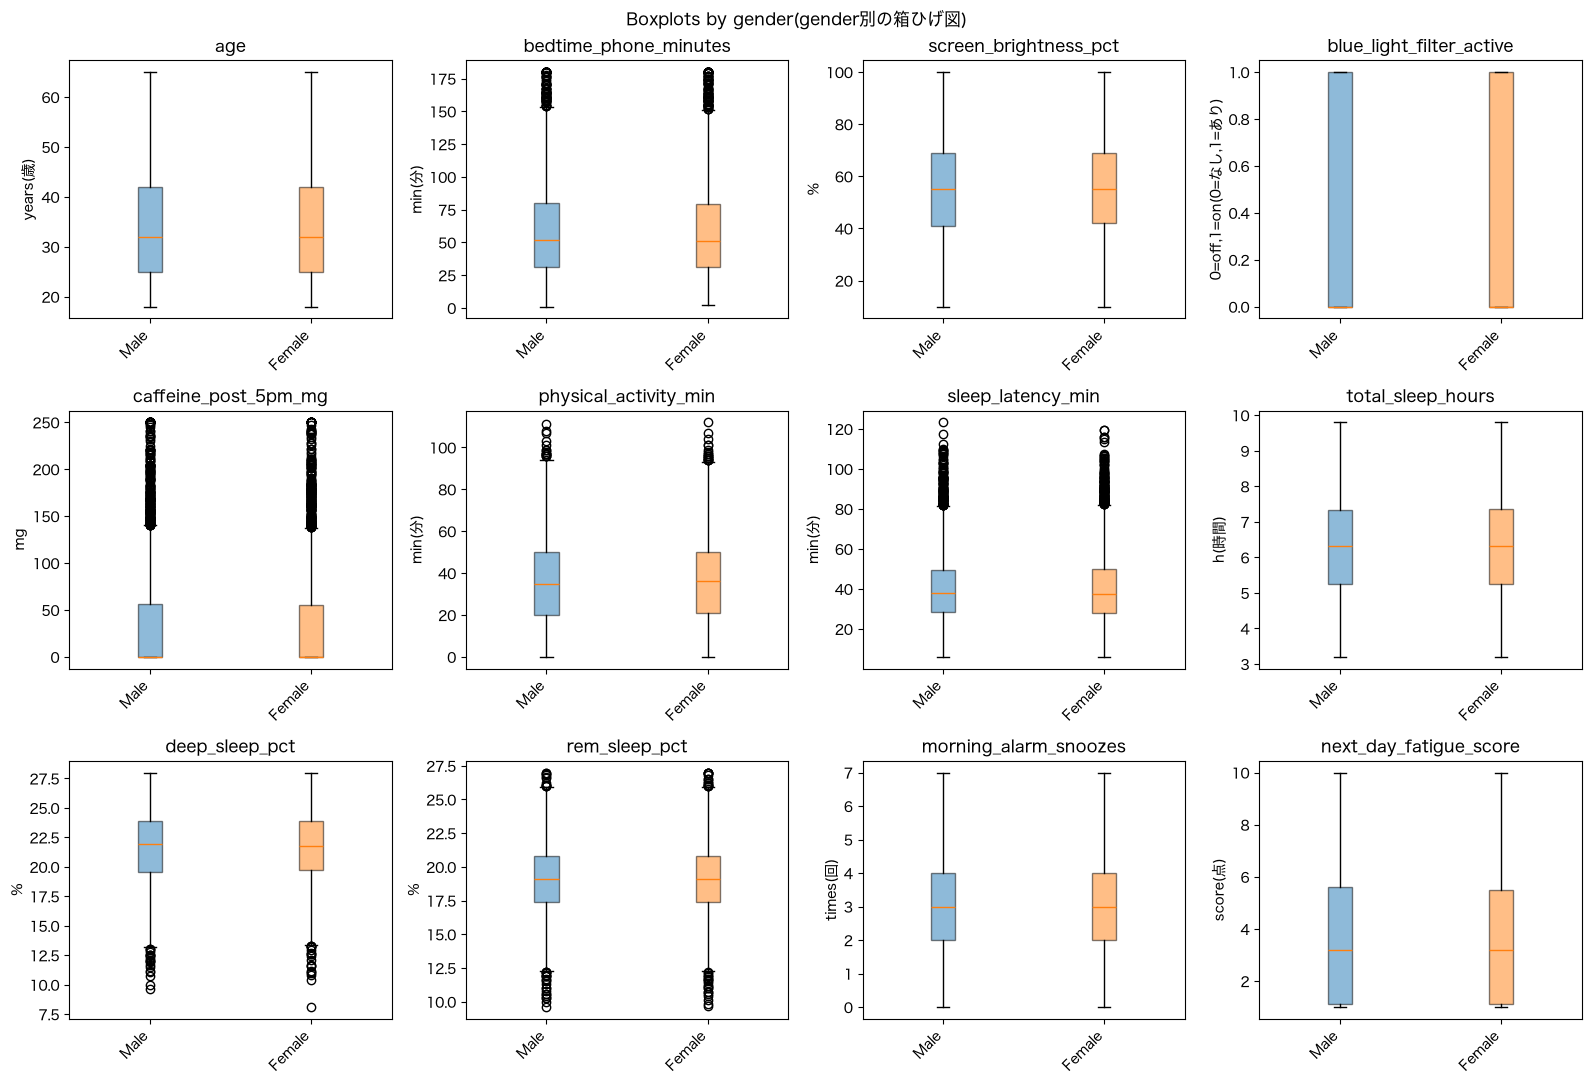

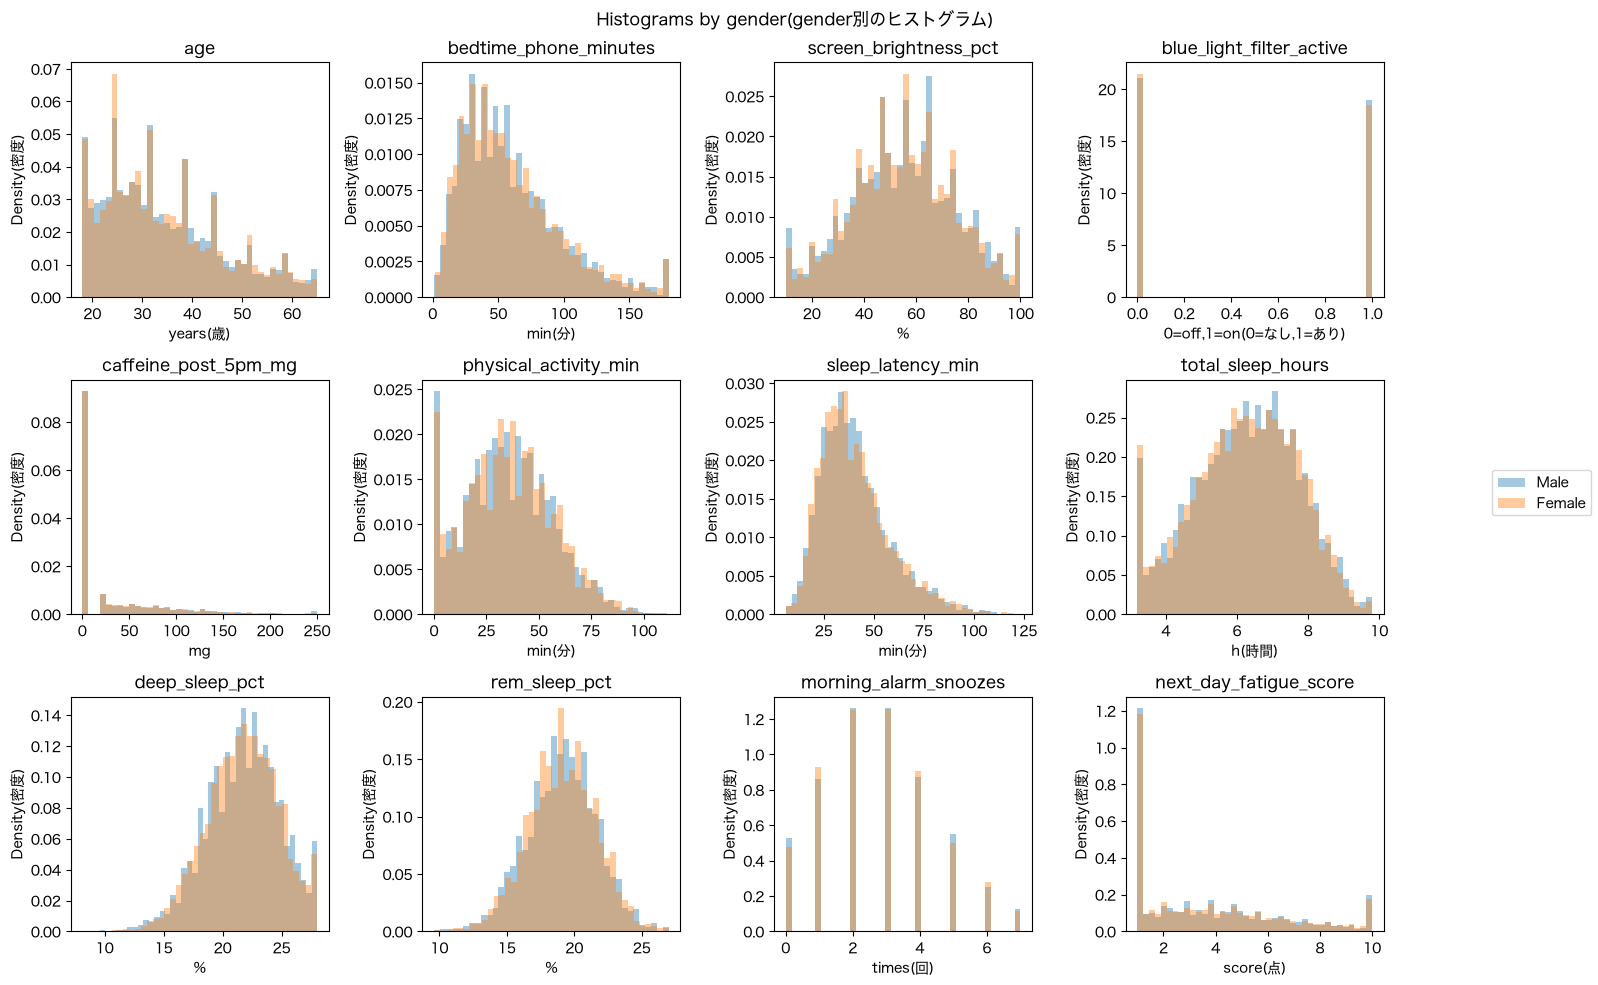

In [9]:
# 性別：男性・女性（ノンバイナリーは248人と少ないので除く）
describe_by_attr("gender", categories=["Male", "Female"])

Mean by occupation_type(occupation_type別の平均):
occupation_type           Corporate 9-to-5  Remote Tech  Student  Healthcare / Shift Worker  Freelance / Creative  Range(幅:最大-最小)
age                                 34.109       34.570   34.247                     34.316                34.863           0.754
bedtime_phone_minutes               59.070       59.404   58.892                     59.297                60.042           1.150
screen_brightness_pct               54.628       55.576   55.189                     55.962                54.850           1.334
blue_light_filter_active             0.383        0.592    0.582                      0.360                 0.354           0.237
caffeine_post_5pm_mg                32.785       33.734   32.213                     33.720                34.650           2.438
physical_activity_min               35.296       35.612   35.769                     35.454                37.344           2.048
sleep_latency_min                   40.834  

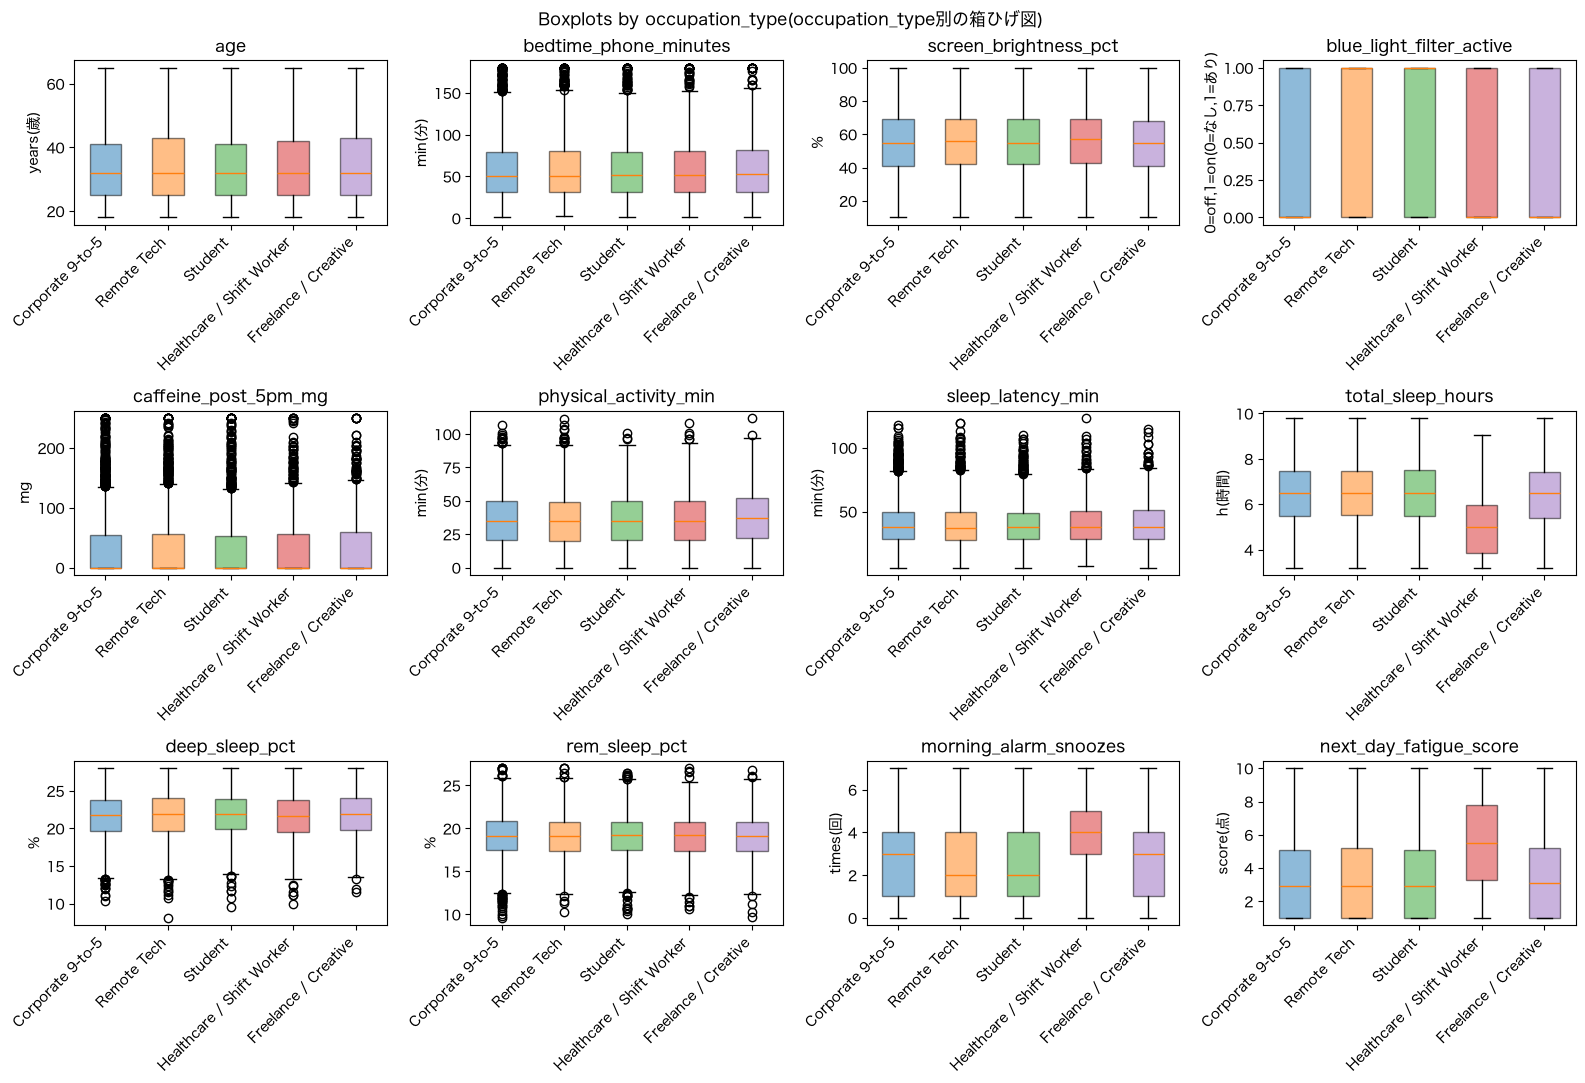

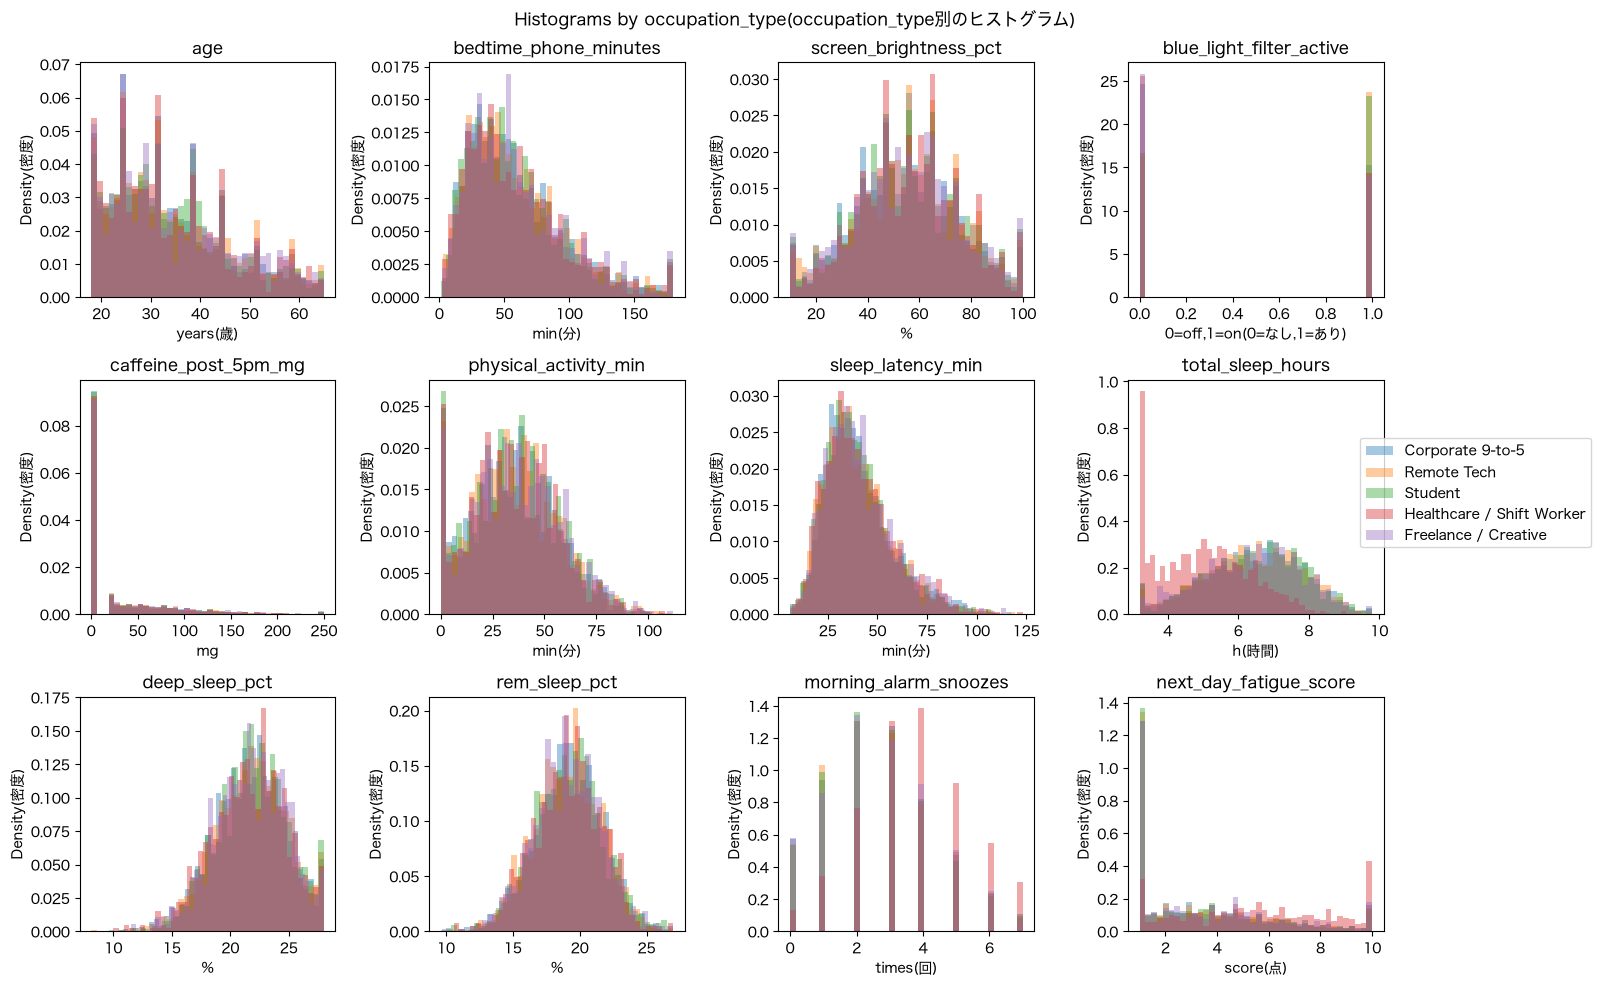

In [10]:
# 職業
describe_by_attr("occupation_type")

Mean by chronotype(chronotype別の平均):
chronotype                Intermediate  Night Owl  Morning Lark  Range(幅:最大-最小)
age                             34.418     34.438        34.150           0.288
bedtime_phone_minutes           59.565     58.307        59.755           1.448
screen_brightness_pct           55.514     54.970        54.717           0.796
blue_light_filter_active         0.461      0.475         0.471           0.014
caffeine_post_5pm_mg            32.623     33.380        34.118           1.495
physical_activity_min           35.368     35.827        36.157           0.789
sleep_latency_min               40.833     40.219        40.895           0.676
total_sleep_hours                6.438      5.012         7.381           2.370
deep_sleep_pct                  21.749     21.719        21.731           0.030
rem_sleep_pct                   19.112     19.126        19.071           0.055
morning_alarm_snoozes            2.613      3.731         1.945           1.786
next

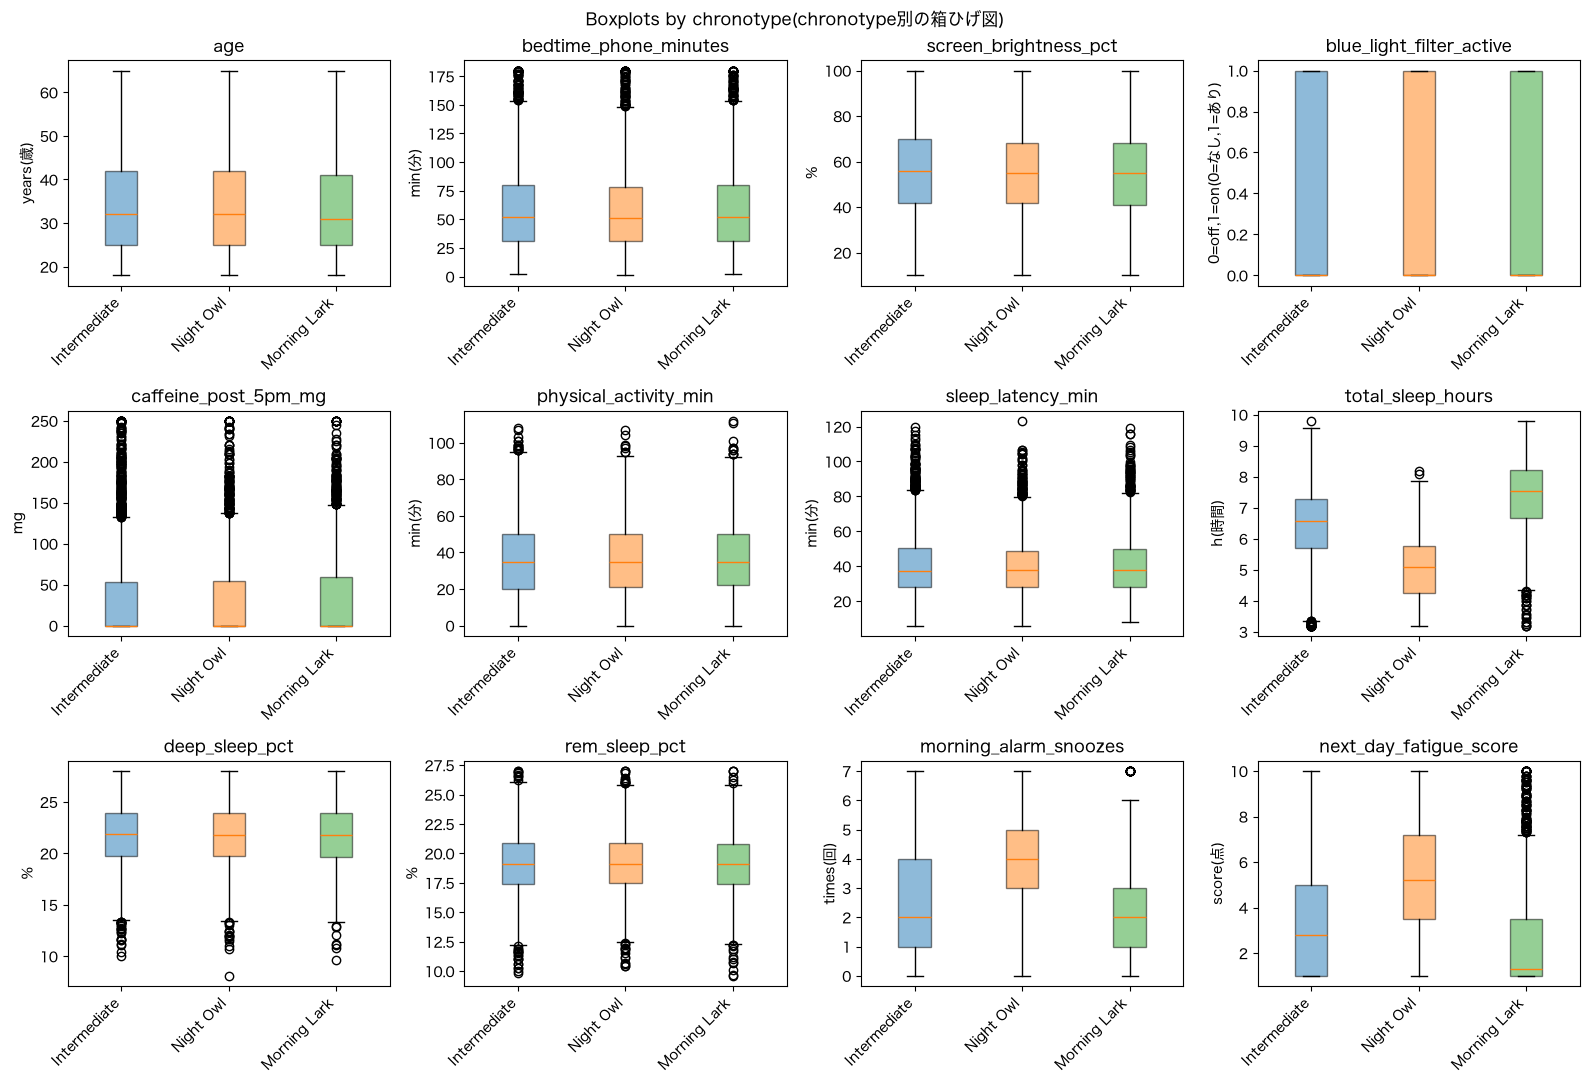

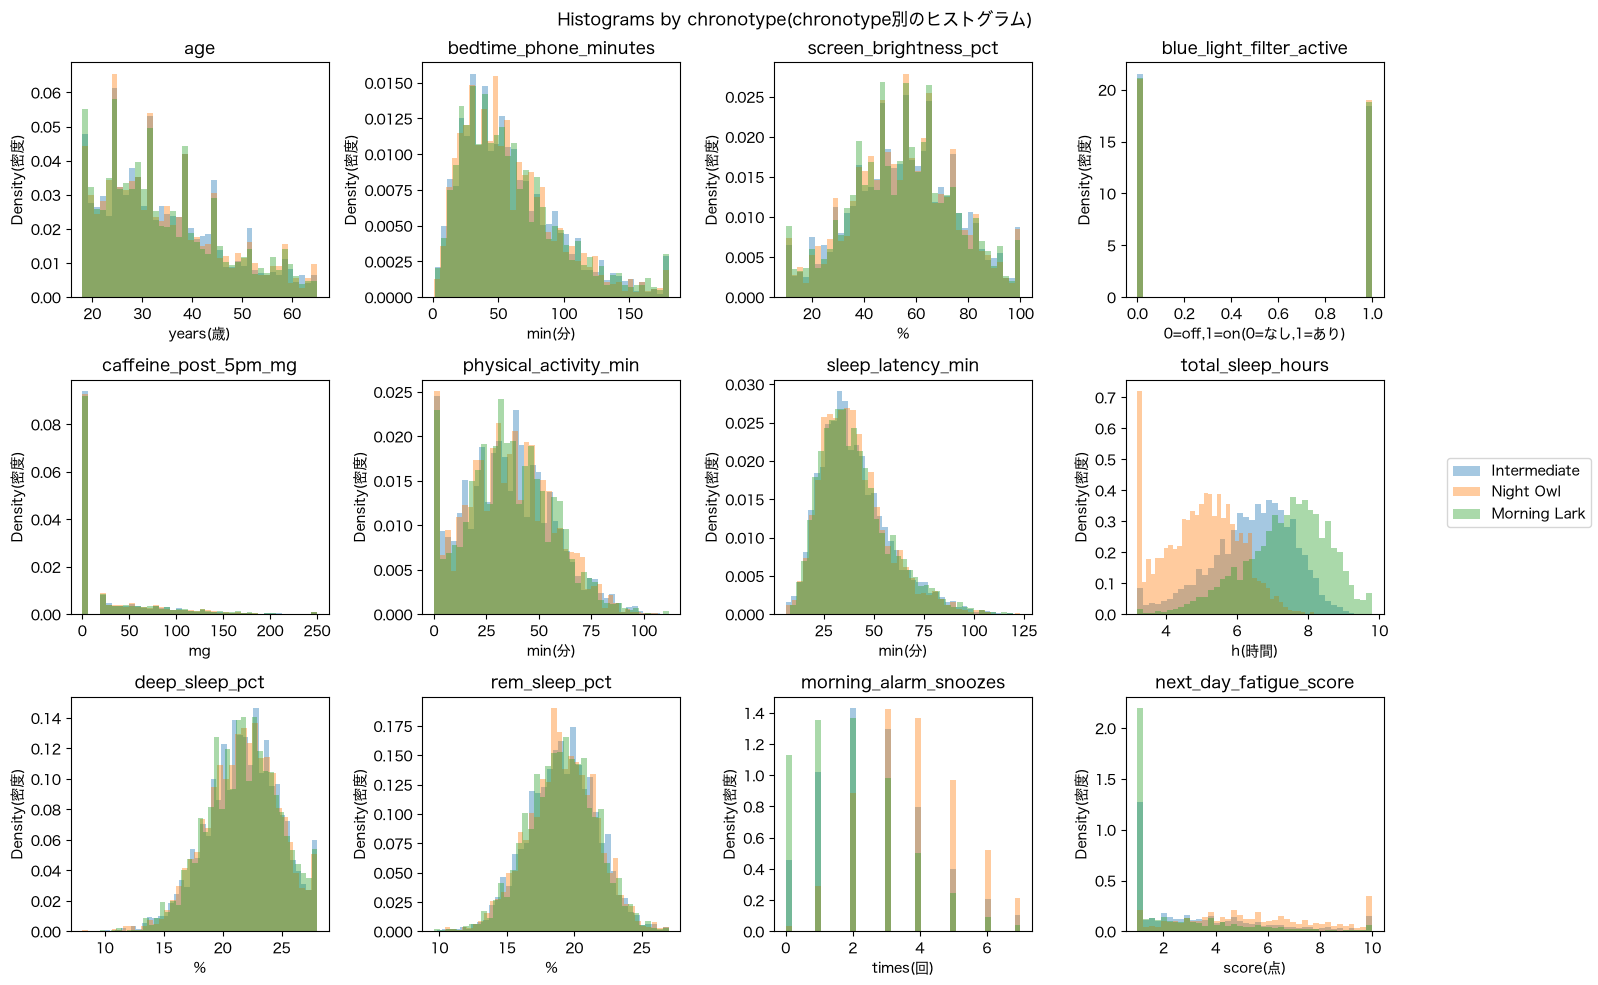

In [11]:
# クロノタイプ（朝型・夜型）
describe_by_attr("chronotype")

Mean by primary_bedtime_app(primary_bedtime_app別の平均):
primary_bedtime_app       TikTok / Reels  YouTube  Instagram / Reddit  Streaming (Netflix/Hulu)  Messaging / Chat  News / Reading  Range(幅:最大-最小)
age                               31.097   34.367              33.929                    37.141            36.765          38.002           6.905
bedtime_phone_minutes             59.853   58.290              60.858                    57.115            59.464          60.092           3.743
screen_brightness_pct             54.840   55.168              55.319                    55.397            54.797          55.794           0.997
blue_light_filter_active           0.465    0.449               0.487                     0.470             0.476           0.471           0.038
caffeine_post_5pm_mg              32.372   35.070              32.334                    33.248            31.757          34.842           3.313
physical_activity_min             35.201   36.113              35.648 

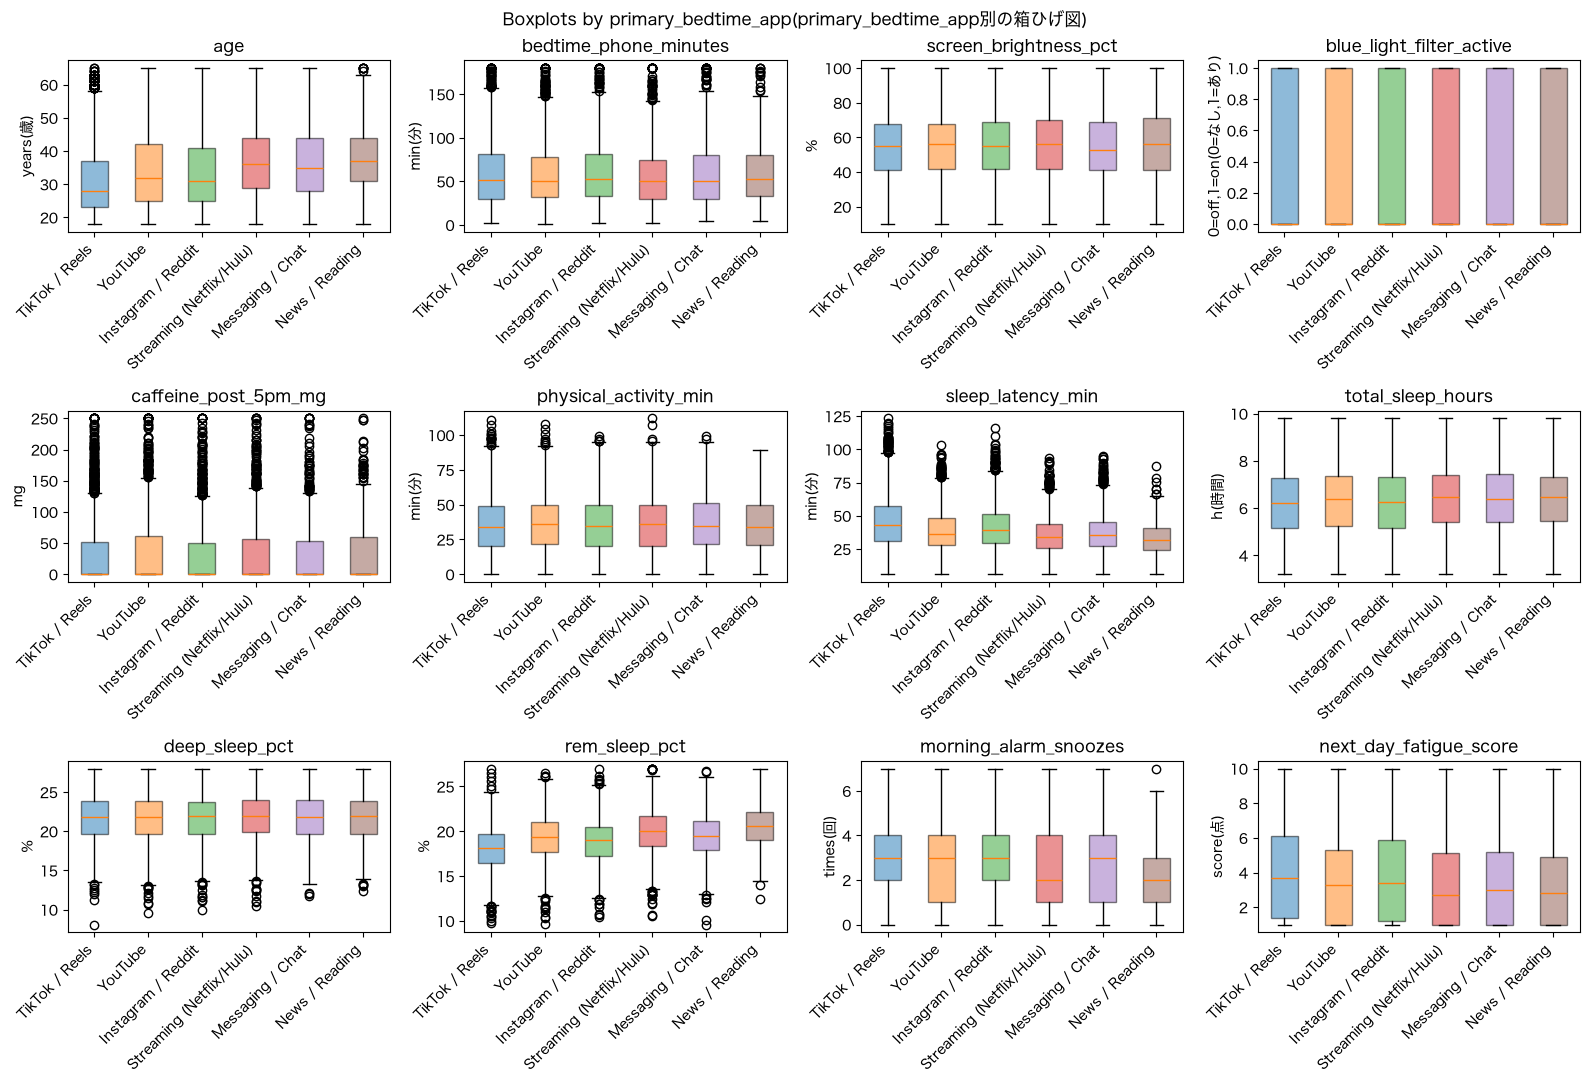

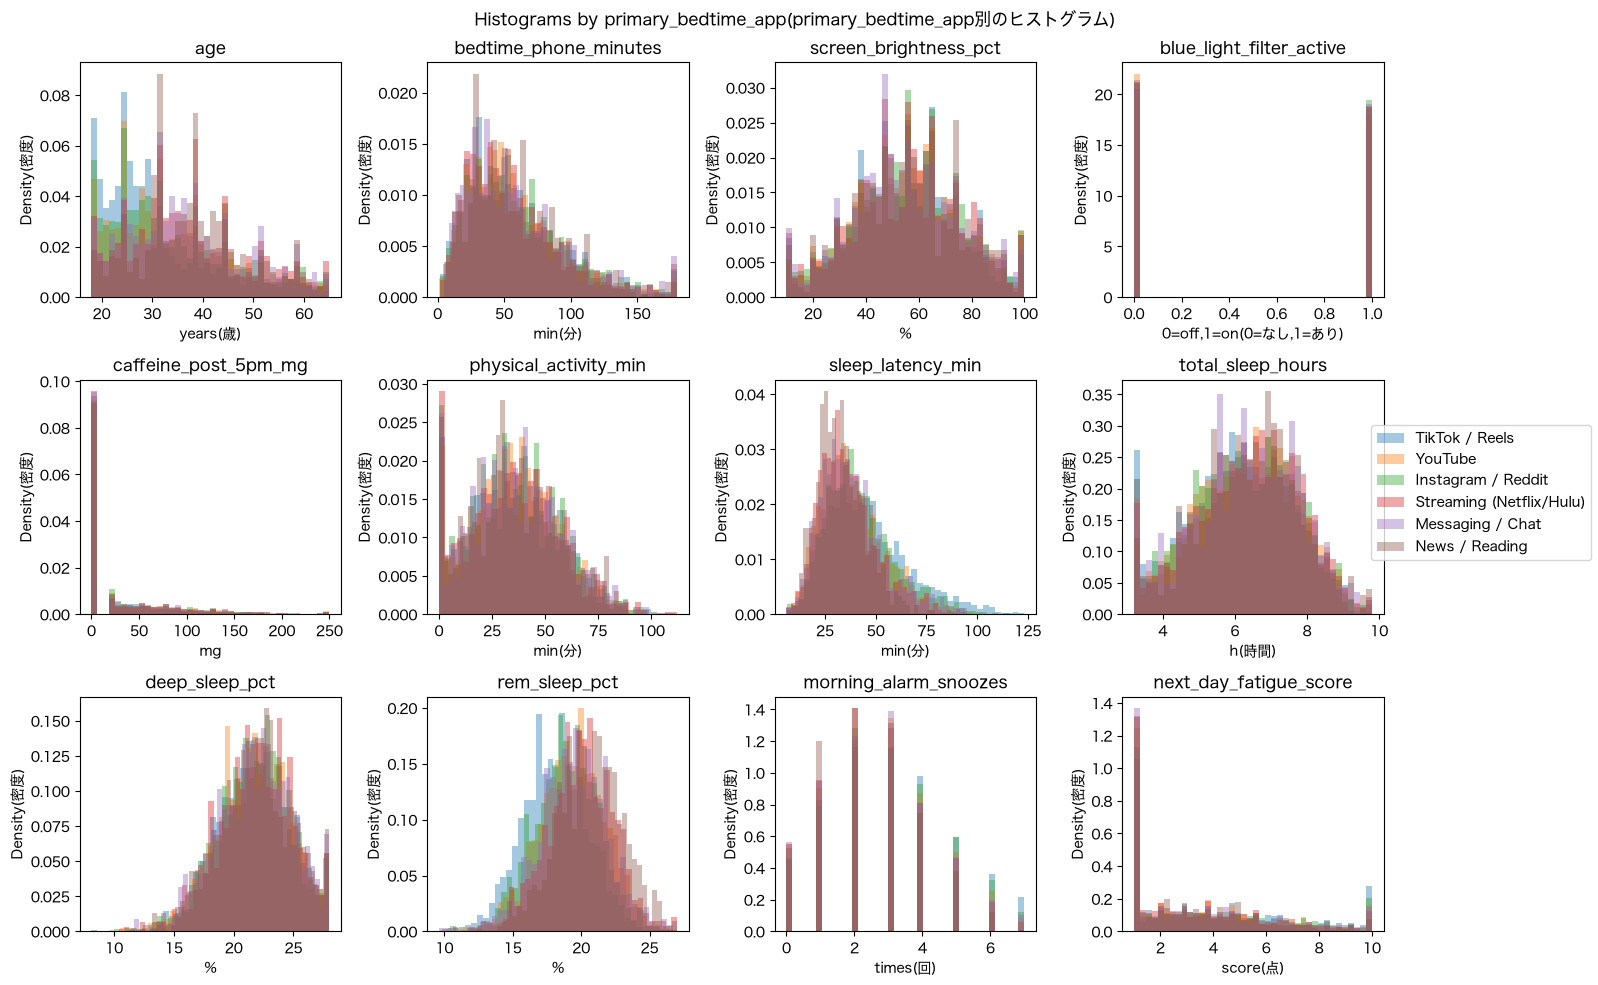

In [12]:
# 寝る前に使うアプリ
describe_by_attr("primary_bedtime_app")

## Step 3:Preprocessing(前処理)

- Missing values and duplicates(欠損値と重複):none(なし)
- Outliers(外れ値):kept as is(そのまま残す)
- Values at bounds(上限・下限への張り付き):kept as is(そのまま残す)
- Correlated features(相関の強い特徴量):kept as is. Their effect on the interpretation is in the limitations of 11-4(そのまま残す。解釈への影響は 11-4 の限界に書く)
- Scaling(標準化):not done. Linear regression coefficients are read in original units, and random forests do not need it(行わない。線形回帰の係数は元の単位のまま読み、RF には必要ない)

In [13]:
# 特徴量10個と目的変数を取り出す
# user_id はID、sleep_debt_category は睡眠時間から作られた列（答えの混入）なので除く
# 属性列（年齢・性別・職業・chronotype・アプリ）は使わない
FEATURES = [
    "bedtime_phone_minutes",
    "screen_brightness_pct",
    "blue_light_filter_active",
    "caffeine_post_5pm_mg",
    "physical_activity_min",
    "sleep_latency_min",
    "total_sleep_hours",
    "deep_sleep_pct",
    "rem_sleep_pct",
    "morning_alarm_snoozes",
]
X = df[FEATURES]
y = df[TARGET]

print(f"X rows(特徴量の行数):{X.shape[0]}")
print(f"X columns(特徴量の列数):{X.shape[1]}")
print(f"y rows(目的変数の行数):{y.shape[0]}")
print(f"Target(目的変数):{TARGET}")
print("Features(特徴量):")
for i, col in enumerate(FEATURES, start=1):
    print(f"{i}.{col}")
print("Dropped columns(除いた列):")
for col in df.columns.drop(FEATURES + [TARGET]):
    print(f"-{col}")

X rows(特徴量の行数):8500
X columns(特徴量の列数):10
y rows(目的変数の行数):8500
Target(目的変数):next_day_fatigue_score
Features(特徴量):
1.bedtime_phone_minutes
2.screen_brightness_pct
3.blue_light_filter_active
4.caffeine_post_5pm_mg
5.physical_activity_min
6.sleep_latency_min
7.total_sleep_hours
8.deep_sleep_pct
9.rem_sleep_pct
10.morning_alarm_snoozes
Dropped columns(除いた列):
-user_id
-age
-gender
-occupation_type
-chronotype
-primary_bedtime_app
-sleep_debt_category


## Step 4:Train/test split(学習データとテストデータに分ける)

- Each person has one row, so rows are split at random(1人1行なので、行をランダムに分ける)
- Stratified by 10-minute sleep bins, so the train and test sleep distributions have the same shape(睡眠時間の10分ごとの区切りで層化し、学習とテストの睡眠時間の分布を同じ形にする)
- The bins are narrower than any window width tried later (0.25h or more)(区切りは、後で試す窓の幅（0.25時間以上）より細かい)
- Test data is not used until Step 10(テストデータは Step 10 まで使わない)

Strata width(層化の区切りの幅):10min(分)
Number of strata(区切りの数、人がいるもの):40
Smallest stratum N(一番少ない区切りの人数):15
Largest stratum N(一番多い区切りの人数):390
Test size(テストの割合):0.2
Random state(乱数シード):42
Train rows(学習の行数):6800
Test rows(テストの行数):1700
Test ratio per stratum min(区切りごとのテストの割合の最小):0.1875
Test ratio per stratum max(区切りごとのテストの割合の最大):0.2051
Train sleep range(学習の睡眠時間の範囲) h(時間):3.2-9.8
Test sleep range(テストの睡眠時間の範囲) h(時間):3.2-9.8
KS statistic of sleep, train vs test(学習とテストの睡眠時間の分布のずれ、KS統計量):0.0059

Split by sleep group(睡眠時間グループごとの分割):
                       Train N(学習の人数)  Test N(テストの人数)  Total N(合計)  Test ratio(テストの割合)  Train fatigue mean(学習の疲労の平均)  Test fatigue mean(テストの疲労の平均)
Sleep group(睡眠時間グループ)                                                                                                                             
-5h                              1371             342         1713              0.1996                         7.659                         7.676
5-6h                             145

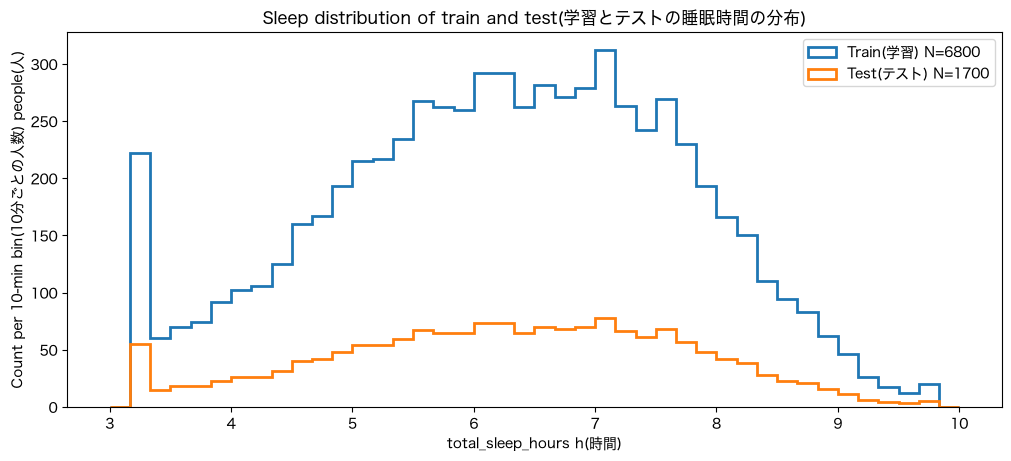

In [14]:
import numpy as np
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split

# 層化に使う区切り：睡眠時間を分に直し、180分（3時間）から600分（10時間）まで10分ごとに区切る（左閉じ・右開き）
STRATA_MINUTES = 10
strata_edges = np.arange(180, 600 + STRATA_MINUTES, STRATA_MINUTES)
strata = pd.cut(df[SLEEP] * 60, bins=strata_edges, right=False)
strata_n = strata.value_counts(sort=False)
strata_n = strata_n[strata_n > 0]

# 睡眠時間グループ（-5h, 5-6h, 6-7h, 7-8h, 8h+）。Step 9 でグループ別モデルと比べるときに使う
SLEEP_BINS = [0, 5, 6, 7, 8, 24]
GROUPS = ["-5h", "5-6h", "6-7h", "7-8h", "8h+"]
group = pd.cut(df[SLEEP], bins=SLEEP_BINS, labels=GROUPS, right=False)

# 各区切りの中で学習8：テスト2に分ける
TEST_SIZE = 0.2
RANDOM_STATE = 42
X_train, X_test, y_train, y_test, group_train, group_test = train_test_split(
    X, y, group, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=strata.astype(str)
)
strata_test_ratio = strata[X_test.index].value_counts(sort=False)[strata_n.index] / strata_n
ks = ks_2samp(X_train[SLEEP], X_test[SLEEP])

print(f"Strata width(層化の区切りの幅):{STRATA_MINUTES}min(分)")
print(f"Number of strata(区切りの数、人がいるもの):{len(strata_n)}")
print(f"Smallest stratum N(一番少ない区切りの人数):{strata_n.min()}")
print(f"Largest stratum N(一番多い区切りの人数):{strata_n.max()}")
print(f"Test size(テストの割合):{TEST_SIZE}")
print(f"Random state(乱数シード):{RANDOM_STATE}")
print(f"Train rows(学習の行数):{len(X_train)}")
print(f"Test rows(テストの行数):{len(X_test)}")
print(f"Test ratio per stratum min(区切りごとのテストの割合の最小):{strata_test_ratio.min():.4f}")
print(f"Test ratio per stratum max(区切りごとのテストの割合の最大):{strata_test_ratio.max():.4f}")
print(f"Train sleep range(学習の睡眠時間の範囲) h(時間):{X_train[SLEEP].min()}-{X_train[SLEEP].max()}")
print(f"Test sleep range(テストの睡眠時間の範囲) h(時間):{X_test[SLEEP].min()}-{X_test[SLEEP].max()}")
print(f"KS statistic of sleep, train vs test(学習とテストの睡眠時間の分布のずれ、KS統計量):{ks.statistic:.4f}")
print()

split_table = pd.DataFrame({
    "Train N(学習の人数)": group_train.value_counts(sort=False),
    "Test N(テストの人数)": group_test.value_counts(sort=False),
})
split_table["Total N(合計)"] = split_table["Train N(学習の人数)"] + split_table["Test N(テストの人数)"]
split_table["Test ratio(テストの割合)"] = (split_table["Test N(テストの人数)"] / split_table["Total N(合計)"]).round(4)
split_table["Train fatigue mean(学習の疲労の平均)"] = y_train.groupby(group_train, observed=False).mean().round(3)
split_table["Test fatigue mean(テストの疲労の平均)"] = y_test.groupby(group_test, observed=False).mean().round(3)
split_table.index.name = "Sleep group(睡眠時間グループ)"
print("Split by sleep group(睡眠時間グループごとの分割):")
print(split_table.to_string())

# 学習とテストの睡眠時間のヒストグラム（10分ごとの区切りの人数）
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
ax.hist(X_train[SLEEP], bins=strata_edges / 60, histtype="step", linewidth=2, label=f"Train(学習) N={len(X_train)}")
ax.hist(X_test[SLEEP], bins=strata_edges / 60, histtype="step", linewidth=2, label=f"Test(テスト) N={len(X_test)}")
ax.set_xlabel("total_sleep_hours h(時間)")
ax.set_ylabel(f"Count per {STRATA_MINUTES}-min bin({STRATA_MINUTES}分ごとの人数) people(人)")
ax.set_title("Sleep distribution of train and test(学習とテストの睡眠時間の分布)")
ax.legend()
plt.show()

## Step 5:Baseline(ベースライン)

One linear regression and one random forest trained on all 6,800 training rows, without using sleep windows(睡眠時間で分けず、学習データ6,800人全員で線形回帰と RF を1つずつ作る)

- Linear regression:multiple regression by ordinary least squares, coefficients in original units(線形回帰：最小二乗法による重回帰。係数は元の単位)
- Random forest:max_depth × min_samples_leaf chosen by 5-fold CV inside the training data(RF：深さと葉の最小人数を、学習データの中の5分割交差検証で選ぶ)
- CV folds are stratified by the 10-minute sleep bins of Step 4(交差検証の分割も Step 4 の10分ごとの区切りで層化する)
- Test data is not used here(テストデータはここでは使わない。評価は Step 10)

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 線形回帰：係数を元の単位で読めるように、標準化せずに学習する
base_lr = LinearRegression()
base_lr.fit(X_train, y_train)
lr_train_pred = base_lr.predict(X_train)

coef_table = pd.DataFrame({
    "Coefficient(係数)": base_lr.coef_,
    "Unit(単位)": [UNITS[col] for col in FEATURES],
}, index=FEATURES)
coef_table.index.name = "Feature(特徴量)"

print("Linear regression(線形回帰)")
print(f"Train MSE(学習データのMSE):{mean_squared_error(y_train, lr_train_pred):.4f}")
print(f"Train R2(学習データのR2):{r2_score(y_train, lr_train_pred):.4f}")
print(f"Intercept(切片):{base_lr.intercept_:.4f}")
print("Coefficients per 1 unit(1単位あたりの係数):")
print(coef_table.round(4).to_string())

Linear regression(線形回帰)
Train MSE(学習データのMSE):0.6322
Train R2(学習データのR2):0.9119
Intercept(切片):8.2255
Coefficients per 1 unit(1単位あたりの係数):
                          Coefficient(係数)               Unit(単位)
Feature(特徴量)                                                    
bedtime_phone_minutes              0.0062                 min(分)
screen_brightness_pct              0.0051                      %
blue_light_filter_active          -0.1379  0=off,1=on(0=なし,1=あり)
caffeine_post_5pm_mg               0.0040                     mg
physical_activity_min              0.0001                 min(分)
sleep_latency_min                  0.0297                 min(分)
total_sleep_hours                 -0.9517                  h(時間)
deep_sleep_pct                    -0.0642                      %
rem_sleep_pct                     -0.0030                      %
morning_alarm_snoozes              0.3797               times(回)


Default tree depth(既定の木の深さ):21-29
max_depth candidates(深さの候補):[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, None]
min_samples_leaf candidates(葉の最小人数の候補):[1, 2, 3, 5, 7, 10, 20, 50]
Combinations(組み合わせの数):192
Folds(分割数):5
Fits(学習回数):960
Best(最良):{'max_depth': 11, 'min_samples_leaf': 2, 'n_estimators': 100}
Best CV MSE(最良の交差検証MSE):0.36401

CV MSE(交差検証MSE) rows=max_depth(深さ),columns=min_samples_leaf(葉の最小人数):
min_samples_leaf       1        2        3        5        7        10       20       50
max_depth                                                                               
2                 1.28565  1.28565  1.28565  1.28565  1.28565  1.28565  1.28565  1.28565
3                 0.84257  0.84257  0.84257  0.84257  0.84257  0.84257  0.84257  0.84257
4                 0.62075  0.62075  0.62075  0.62075  0.62075  0.62075  0.62072  0.61981
5                 0.51102  0.51101  0.51093  0.51077  0.51069  0.51096  0.51087  0.52446
6                 0

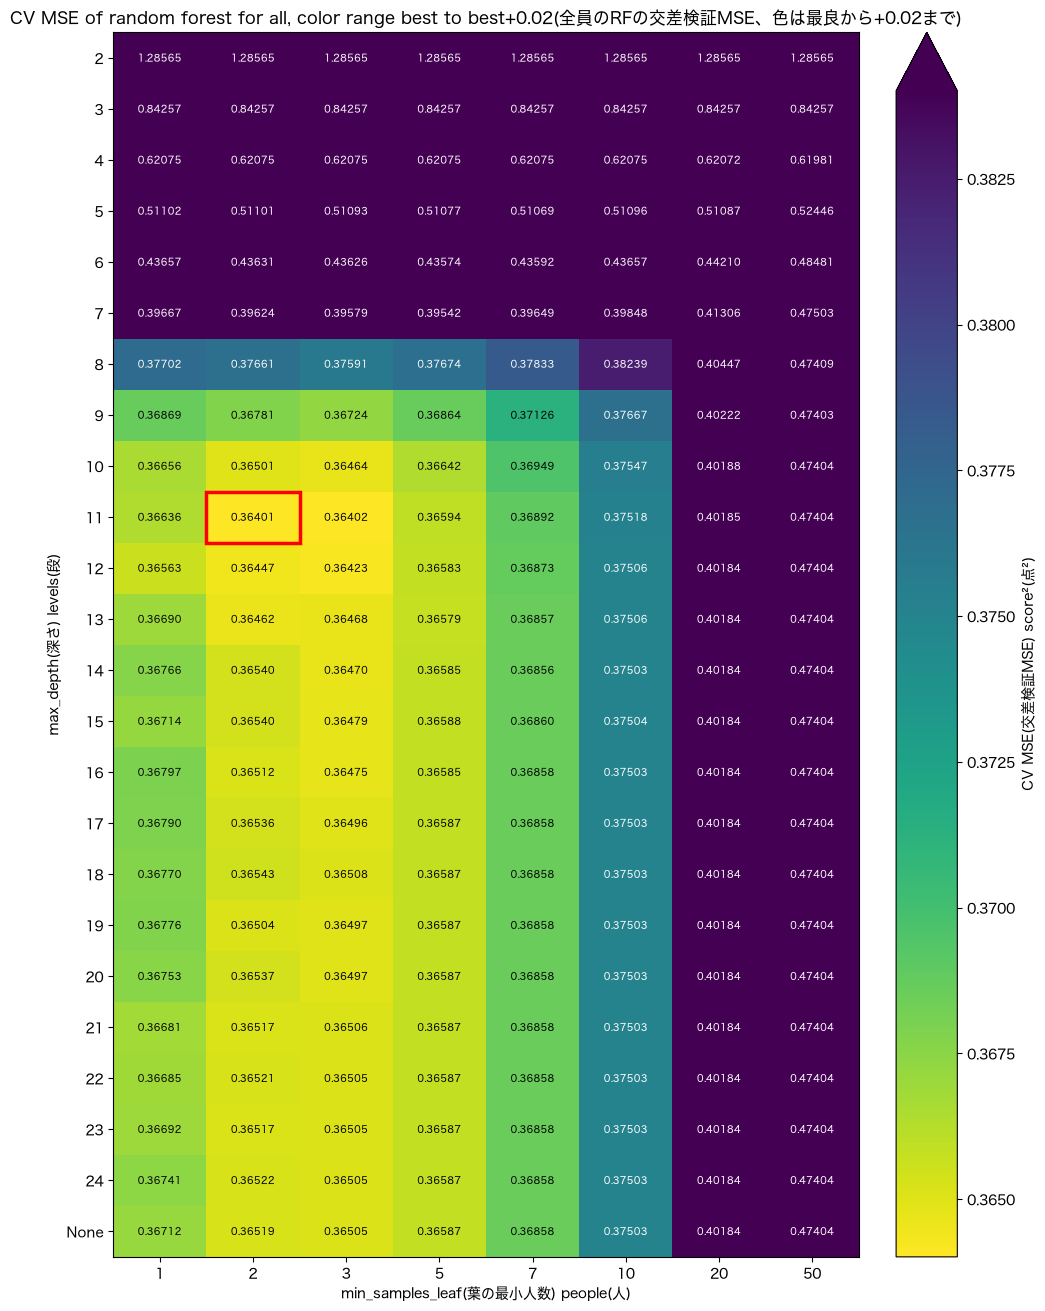

In [16]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 既定の設定（深さ制限なし、葉の最小人数1）で作った木の深さを確かめ、深さの候補を決める
DEFAULT_PARAMS = {"n_estimators": 100, "max_depth": None, "min_samples_leaf": 1}
default_rf = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **DEFAULT_PARAMS)
default_rf.fit(X_train, y_train)
default_depths = [tree.get_depth() for tree in default_rf.estimators_]

# 深さは2〜24のすべての整数と制限なし（既定の木より深い設定は、制限なしで調べたことになる）。木の本数は100に固定
DEPTHS = list(range(2, 25)) + [None]
LEAVES = [1, 2, 3, 5, 7, 10, 20, 50]
PARAM_GRID = {"n_estimators": [100], "max_depth": DEPTHS, "min_samples_leaf": LEAVES}

# 交差検証の分割：学習データを10分ごとの区切りで層化して5つに分ける
N_FOLDS = 5
strata_train = strata[X_train.index].astype(str)
cv_folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X_train, strata_train))

search = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    PARAM_GRID, cv=cv_folds, scoring="neg_mean_squared_error", return_train_score=True,
)
search.fit(X_train, y_train)

# 深さ × 葉の最小人数ごとの交差検証MSE（行：深さ、列：葉の最小人数）
cv_results = pd.DataFrame(search.cv_results_)
cv_long = pd.DataFrame({
    "max_depth": [str(p["max_depth"]) for p in cv_results["params"]],
    "min_samples_leaf": [p["min_samples_leaf"] for p in cv_results["params"]],
    "MSE": -cv_results["mean_test_score"],
})
cv_table = cv_long.pivot(index="max_depth", columns="min_samples_leaf", values="MSE").loc[[str(d) for d in DEPTHS]]

print(f"Default tree depth(既定の木の深さ):{min(default_depths)}-{max(default_depths)}")
print(f"max_depth candidates(深さの候補):{DEPTHS}")
print(f"min_samples_leaf candidates(葉の最小人数の候補):{LEAVES}")
print(f"Combinations(組み合わせの数):{len(DEPTHS) * len(LEAVES)}")
print(f"Folds(分割数):{N_FOLDS}")
print(f"Fits(学習回数):{len(DEPTHS) * len(LEAVES) * N_FOLDS}")
print(f"Best(最良):{search.best_params_}")
print(f"Best CV MSE(最良の交差検証MSE):{-search.best_score_:.5f}")
print()
print("CV MSE(交差検証MSE) rows=max_depth(深さ),columns=min_samples_leaf(葉の最小人数):")
print(cv_table.round(5).to_string())

# ヒートマップ。赤枠が最良
# 色の範囲は最良値から +COLOR_RANGE までにしぼる（浅い木の大きな MSE に合わせると、良い範囲がすべて同じ色になるため）
# それより悪いマスは一番濃い色にまとめる
COLOR_RANGE = 0.02
vmin = cv_table.values.min()
vmax = vmin + COLOR_RANGE
fig, ax = plt.subplots(figsize=(10, 13), layout="constrained")
im = ax.imshow(cv_table, cmap="viridis_r", aspect="auto", vmin=vmin, vmax=vmax)
for i in range(cv_table.shape[0]):
    for j in range(cv_table.shape[1]):
        value = cv_table.iloc[i, j]
        ax.text(j, i, f"{value:.5f}", ha="center", va="center", fontsize=7,
                color="black" if value < vmin + COLOR_RANGE / 2 else "white")
best_i = cv_table.index.get_loc(str(search.best_params_["max_depth"]))
best_j = cv_table.columns.get_loc(search.best_params_["min_samples_leaf"])
ax.add_patch(plt.Rectangle((best_j - 0.5, best_i - 0.5), 1, 1, fill=False, edgecolor="red", linewidth=2.5))
ax.set_xticks(range(cv_table.shape[1]), cv_table.columns)
ax.set_yticks(range(cv_table.shape[0]), cv_table.index)
ax.set_xlabel("min_samples_leaf(葉の最小人数) people(人)")
ax.set_ylabel("max_depth(深さ) levels(段)")
ax.set_title(f"CV MSE of random forest for all, color range best to best+{COLOR_RANGE}(全員のRFの交差検証MSE、色は最良から+{COLOR_RANGE}まで)")
fig.colorbar(im, ax=ax, extend="max", label="CV MSE(交差検証MSE) score²(点²)")
plt.show()

In [17]:
# 既定の設定と最良の設定の比較（学習MSEに対して交差検証MSEが何倍か＝学習データへの合わせすぎの目安）
def cv_scores(params):
    hit = cv_results["params"].apply(lambda p: p == params)
    return -cv_results.loc[hit, "mean_train_score"].iloc[0], -cv_results.loc[hit, "mean_test_score"].iloc[0]

compare_table = pd.DataFrame(
    [cv_scores(DEFAULT_PARAMS), cv_scores(search.best_params_)],
    index=["Default(既定)", "Best(最良)"],
    columns=["Train MSE in CV(交差検証の学習MSE)", "CV MSE(交差検証MSE)"],
)
compare_table["CV/train(倍率)"] = compare_table["CV MSE(交差検証MSE)"] / compare_table["Train MSE in CV(交差検証の学習MSE)"]
compare_table.index.name = "Setting(設定)"

# 調整後の RF（学習データ全体で学習し直したもの）
tuned_rf = search.best_estimator_
rf_train_pred = tuned_rf.predict(X_train)

print(f"CV MSE change, best - default(交差検証MSEの変化、最良-既定):{compare_table.iloc[1, 1] - compare_table.iloc[0, 1]:.4f}")
print(compare_table.round(4).to_string())
print()
print("Tuned random forest(調整後のRF)")
print(f"Train MSE(学習データのMSE):{mean_squared_error(y_train, rf_train_pred):.4f}")
print(f"Train R2(学習データのR2):{r2_score(y_train, rf_train_pred):.4f}")

CV MSE change, best - default(交差検証MSEの変化、最良-既定):-0.0031
             Train MSE in CV(交差検証の学習MSE)  CV MSE(交差検証MSE)  CV/train(倍率)
Setting(設定)                                                            
Default(既定)                       0.0516           0.3671        7.1115
Best(最良)                          0.1117           0.3640        3.2577

Tuned random forest(調整後のRF)
Train MSE(学習データのMSE):0.1204
Train R2(学習データのR2):0.9832


## Step 6:Moving windows(移動窓)

### 6-1:Window rules and number of people(窓のルールと人数の確認)

- A window with center c and width w holds people with c-w/2 ≤ sleep < c+w/2(中心c、幅wの窓には、睡眠時間がc-w/2以上c+w/2未満の人が入る)
- Centers move by 0.1h from 3.0h to 9.8h, covering the sleep range of the training data (3.2-9.8h) from the whole hour below it(中心は、学習データの睡眠時間の範囲3.2〜9.8時間を、その下のちょうどの時間3.0時間から0.1時間ずつ動かす)
- Width candidates are 0.25h, 0.5h, 1.0h, 1.25h and 1.5h. The width is chosen in 6-2(幅の候補は0.25、0.5、1.0、1.25、1.5時間。幅は6-2で選ぶ)
- A window is not fitted if it has fewer than 100 training people or everyone has the same fatigue(学習データが100人未満の窓と、疲労が全員同じ窓は学習しない)
- Windows at the edges are only partly filled, so the mean sleep in each window is also shown(端の窓は片側にしか人がいないので、窓の中の人の平均睡眠時間も出す)
- Only training data is used(学習データだけを使う)

In [18]:
# 窓のルール
WINDOW_WIDTHS = [0.25, 0.5, 1.0, 1.25, 1.5]
WINDOW_STEP = 0.1
MIN_TRAIN_N = 100
SLEEP_FLOOR = df[SLEEP].min()
window_centers = np.round(np.arange(np.floor(X_train[SLEEP].min()), X_train[SLEEP].max() + WINDOW_STEP / 2, WINDOW_STEP), 1)

def in_window(sleep, center, width):
    return (sleep >= center - width / 2) & (sleep < center + width / 2)

# 幅ごと・窓ごとの学習データの人数、平均睡眠時間、疲労の分布
window_rows = []
for width in WINDOW_WIDTHS:
    for center in window_centers:
        mask = in_window(X_train[SLEEP], center, width)
        sleep_w, fatigue_w = X_train.loc[mask, SLEEP], y_train[mask]
        n = int(mask.sum())
        std = fatigue_w.std() if n > 1 else np.nan
        window_rows.append({
            "Width(幅) h(時間)": width,
            "Center(中心) h(時間)": center,
            "Train N(学習の人数)": n,
            "Mean sleep(平均睡眠時間) h(時間)": sleep_w.mean(),
            "Shift from center(中心とのずれ) h(時間)": sleep_w.mean() - center,
            f"At {SLEEP_FLOOR:g}h ratio(睡眠{SLEEP_FLOOR:g}時間の割合)": sleep_w.eq(SLEEP_FLOOR).mean(),
            "Fatigue mean(疲労の平均)": fatigue_w.mean(),
            "Fatigue std(疲労の標準偏差)": std,
            "At 10.0 ratio(疲労10.0の割合)": fatigue_w.eq(10.0).mean(),
            "At 1.0 ratio(疲労1.0の割合)": fatigue_w.eq(1.0).mean(),
            "Fitted(学習する)": (n >= MIN_TRAIN_N) and (std > 0),
        })
window_info = pd.DataFrame(window_rows)

# 幅ごとのまとめ
summary_rows = []
for width, part in window_info.groupby("Width(幅) h(時間)"):
    fitted = part[part["Fitted(学習する)"]]
    summary_rows.append({
        "Width(幅) h(時間)": width,
        "Windows(窓の数)": len(part),
        "Fitted(学習する窓)": len(fitted),
        "Not fitted, N<100(学習しない、100人未満)": int((part["Train N(学習の人数)"] < MIN_TRAIN_N).sum()),
        "Not fitted, std=0(学習しない、標準偏差0)": int(((part["Train N(学習の人数)"] >= MIN_TRAIN_N) & ~(part["Fatigue std(疲労の標準偏差)"] > 0)).sum()),
        "First fitted center(学習する最初の中心) h(時間)": fitted["Center(中心) h(時間)"].min(),
        "Last fitted center(学習する最後の中心) h(時間)": fitted["Center(中心) h(時間)"].max(),
        "Min N of fitted(学習する窓の最少人数)": fitted["Train N(学習の人数)"].min(),
        "Max N of fitted(学習する窓の最多人数)": fitted["Train N(学習の人数)"].max(),
        "Max abs shift of fitted(学習する窓の中心とのずれの最大) h(時間)": fitted["Shift from center(中心とのずれ) h(時間)"].abs().max(),
    })
window_summary = pd.DataFrame(summary_rows).set_index("Width(幅) h(時間)")

print(f"Width candidates(幅の候補) h(時間):{WINDOW_WIDTHS}")
print(f"Step(ずらし幅) h(時間):{WINDOW_STEP}")
print(f"Centers(中心) h(時間):{window_centers[0]}-{window_centers[-1]}")
print(f"Number of centers(中心の数):{len(window_centers)}")
print(f"Min train N to fit(学習する最少人数):{MIN_TRAIN_N}")
print(f"Sleep floor in data(データの睡眠時間の最小値) h(時間):{SLEEP_FLOOR}")
print()
print("Summary by width(幅ごとのまとめ):")
print(window_summary.round(3).to_string())
for width in WINDOW_WIDTHS:
    print()
    print(f"Windows of width {width}h(幅{width}時間の窓):")
    part = window_info[window_info["Width(幅) h(時間)"] == width].drop(columns="Width(幅) h(時間)").set_index("Center(中心) h(時間)")
    print(part.round(3).to_string())

Width candidates(幅の候補) h(時間):[0.25, 0.5, 1.0, 1.25, 1.5]
Step(ずらし幅) h(時間):0.1
Centers(中心) h(時間):3.0-9.8
Number of centers(中心の数):69
Min train N to fit(学習する最少人数):100
Sleep floor in data(データの睡眠時間の最小値) h(時間):3.2

Summary by width(幅ごとのまとめ):
                Windows(窓の数)  Fitted(学習する窓)  Not fitted, N<100(学習しない、100人未満)  Not fitted, std=0(学習しない、標準偏差0)  First fitted center(学習する最初の中心) h(時間)  Last fitted center(学習する最後の中心) h(時間)  Min N of fitted(学習する窓の最少人数)  Max N of fitted(学習する窓の最多人数)  Max abs shift of fitted(学習する窓の中心とのずれの最大) h(時間)
Width(幅) h(時間)                                                                                                                                                                                                                                                                                   
0.25                      69             55                               12                               2                                   3.1                                  8.6 

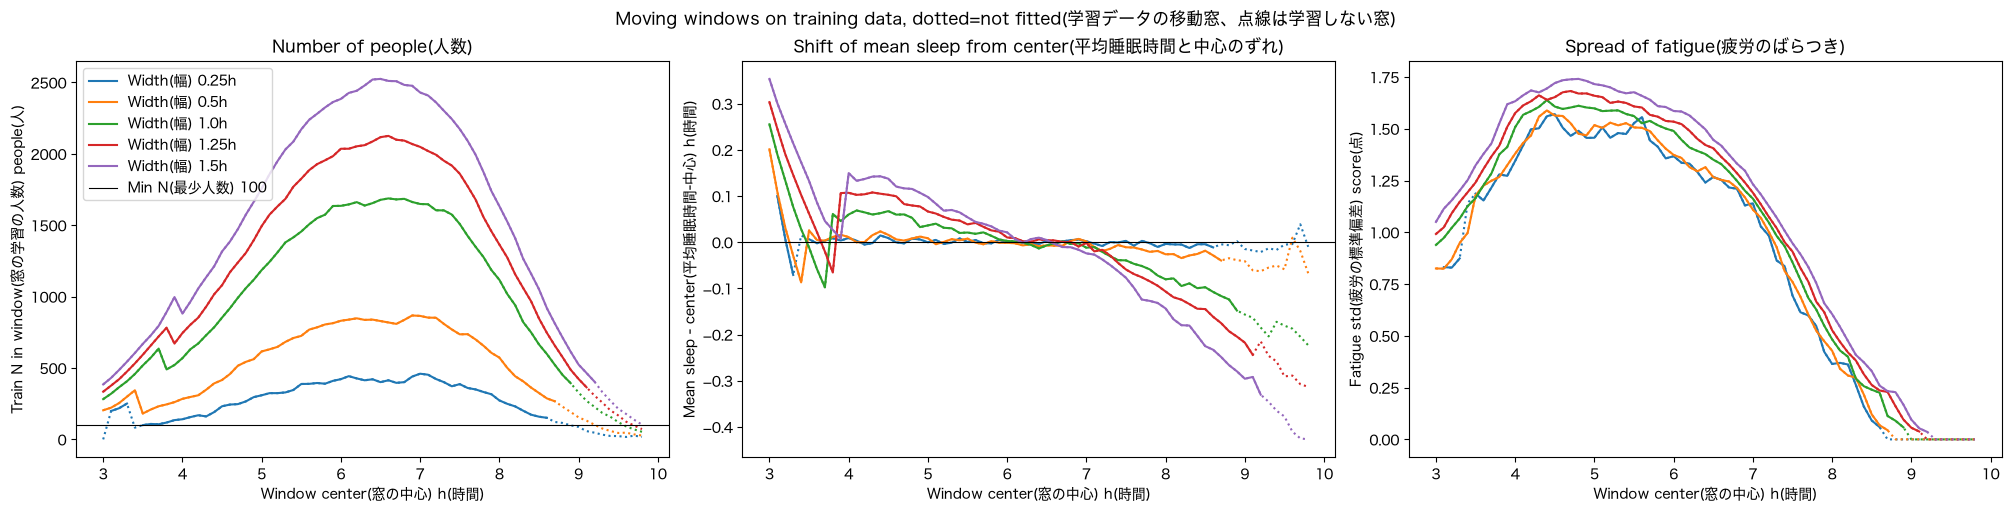

In [19]:
# 図：幅ごとの窓の人数、平均睡眠時間と中心のずれ、疲労の標準偏差（点線は学習しない窓）
fig, axes = plt.subplots(1, 3, figsize=(20, 5), layout="constrained")
for width in WINDOW_WIDTHS:
    part = window_info[window_info["Width(幅) h(時間)"] == width]
    fitted = part["Fitted(学習する)"]
    for ax, col in zip(axes, ["Train N(学習の人数)", "Shift from center(中心とのずれ) h(時間)", "Fatigue std(疲労の標準偏差)"]):
        line, = ax.plot(part["Center(中心) h(時間)"].where(fitted), part[col].where(fitted), label=f"Width(幅) {width}h")
        ax.plot(part["Center(中心) h(時間)"], part[col], linestyle=":", color=line.get_color())
axes[0].axhline(MIN_TRAIN_N, color="black", linewidth=0.8, label=f"Min N(最少人数) {MIN_TRAIN_N}")
axes[0].set_ylabel("Train N in window(窓の学習の人数) people(人)")
axes[0].set_title("Number of people(人数)")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("Mean sleep - center(平均睡眠時間-中心) h(時間)")
axes[1].set_title("Shift of mean sleep from center(平均睡眠時間と中心のずれ)")
axes[2].set_ylabel("Fatigue std(疲労の標準偏差) score(点)")
axes[2].set_title("Spread of fatigue(疲労のばらつき)")
for ax in axes:
    ax.set_xlabel("Window center(窓の中心) h(時間)")
axes[0].legend()
plt.suptitle("Moving windows on training data, dotted=not fitted(学習データの移動窓、点線は学習しない窓)")
plt.show()

### 6-2:Choosing the window width by CV(窓の幅を交差検証で選ぶ)

- The same 5 folds as Step 5 are used(Step 5 と同じ5分割を使う)
- In each fold, a linear regression is fitted in every window, and the held-out fold is predicted(各分割で窓ごとに線形回帰を作り、残した分割を予測する)
- One person is in several windows. Their predictions are averaged with triangular weights, 1 at the center and 0 at the edge(1人は複数の窓に入る。窓の予測を、中心で1・端で0になる三角形の重みで平均する)
- Windows with fewer than 100 people are not used. A window where everyone has the same fatigue predicts that value(100人未満の窓は使わない。疲労が全員同じ窓は、その値を予測にする)
- People with no usable window are predicted by the nearest usable window(使える窓がない人は、中心が一番近い使える窓で予測する)
- The width with the smallest mean CV MSE is used from Step 7 on, for both linear regression and random forest(交差検証MSEの平均が一番小さい幅を、Step 7 以降で線形回帰と RF の両方に使う)

Folds(分割数):5
Width candidates(幅の候補) h(時間):[0.25, 0.5, 1.0, 1.25, 1.5]
Best width(最良の幅) h(時間):1.0
Best mean CV MSE(最良の交差検証MSEの平均):0.32829
All LR mean CV MSE(全員の線形回帰の交差検証MSEの平均):0.63432
Tuned all RF CV MSE from Step 5(Step 5 の調整後の全員RFの交差検証MSE):0.36401

Summary(まとめ):
                              Mean CV MSE(交差検証MSEの平均)  Std of CV MSE(交差検証MSEの標準偏差)  Min(最小)  Max(最大)
Model(モデル)                                                                                          
All LR(全員の線形回帰)                               0.63432                      0.02040  0.61655  0.66839
Width 0.25h MSE(幅0.25時間のMSE)                  0.33705                      0.01801  0.31673  0.35879
Width 0.5h MSE(幅0.5時間のMSE)                    0.32940                      0.01673  0.31173  0.34918
Width 1.0h MSE(幅1.0時間のMSE)                    0.32829                      0.01525  0.31184  0.34510
Width 1.25h MSE(幅1.25時間のMSE)                  0.32965                      0.01451  0.31358  0.34521
Width 1.5h MSE(幅1.5時間のMSE)  

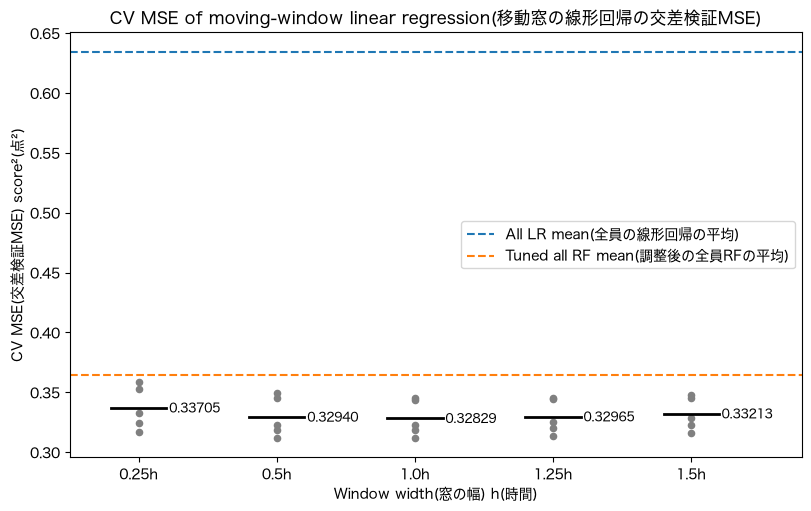

In [20]:
# 窓ごとのモデルを作る関数。{中心: モデル} を返す。疲労が全員同じ窓はモデルの代わりにその値を入れる
def fit_windows(X_part, y_part, width, make_model):
    models = {}
    for center in window_centers:
        mask = in_window(X_part[SLEEP], center, width)
        if mask.sum() < MIN_TRAIN_N:
            continue
        y_w = y_part[mask]
        models[center] = make_model().fit(X_part[mask], y_w) if y_w.std() > 0 else float(y_w.iloc[0])
    return models

def predict_one_window(model, X_rows):
    return np.full(len(X_rows), model) if isinstance(model, float) else model.predict(X_rows)

# 窓ごとの予測を三角形の重みで平均する関数。使える窓がない人の人数も返す
def predict_windows(models, X_part, width):
    sleep_values = X_part[SLEEP].to_numpy()
    weighted_sum = np.zeros(len(X_part))
    weight_total = np.zeros(len(X_part))
    for center, model in models.items():
        mask = in_window(X_part[SLEEP], center, width).to_numpy()
        if not mask.any():
            continue
        weight = 1 - np.abs(sleep_values[mask] - center) / (width / 2)
        weighted_sum[mask] += weight * predict_one_window(model, X_part[mask])
        weight_total[mask] += weight
    no_window = np.where(weight_total == 0)[0]
    pred = np.divide(weighted_sum, weight_total, out=np.zeros(len(X_part)), where=weight_total > 0)
    fitted_centers = np.array(list(models))
    for k in no_window:
        nearest = fitted_centers[np.argmin(np.abs(fitted_centers - sleep_values[k]))]
        pred[k] = predict_one_window(models[nearest], X_part.iloc[[k]])[0]
    return pred, len(no_window)

# 幅ごと・分割ごとの交差検証MSE（比べるため、全員で1つの線形回帰も同じ分割で計算する）
cv_rows = []
for fold, (tr_idx, va_idx) in enumerate(cv_folds, start=1):
    X_tr, y_tr = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
    X_va, y_va = X_train.iloc[va_idx], y_train.iloc[va_idx]
    row = {"Fold(分割)": fold, "Validation N(検証の人数)": len(va_idx)}
    row["All LR(全員の線形回帰)"] = mean_squared_error(y_va, LinearRegression().fit(X_tr, y_tr).predict(X_va))
    for width in WINDOW_WIDTHS:
        models = fit_windows(X_tr, y_tr, width, LinearRegression)
        pred, n_no_window = predict_windows(models, X_va, width)
        row[f"Width {width}h MSE(幅{width}時間のMSE)"] = mean_squared_error(y_va, pred)
        row[f"Width {width}h windows(幅{width}時間の使える窓)"] = len(models)
        row[f"Width {width}h no window(幅{width}時間の使える窓がない人)"] = n_no_window
    cv_rows.append(row)
width_cv = pd.DataFrame(cv_rows).set_index("Fold(分割)")

mse_cols = ["All LR(全員の線形回帰)"] + [f"Width {w}h MSE(幅{w}時間のMSE)" for w in WINDOW_WIDTHS]
width_cv_summary = pd.DataFrame({
    "Mean CV MSE(交差検証MSEの平均)": width_cv[mse_cols].mean(),
    "Std of CV MSE(交差検証MSEの標準偏差)": width_cv[mse_cols].std(),
    "Min(最小)": width_cv[mse_cols].min(),
    "Max(最大)": width_cv[mse_cols].max(),
})
width_cv_summary.index.name = "Model(モデル)"
width_means = pd.Series({w: width_cv[f"Width {w}h MSE(幅{w}時間のMSE)"].mean() for w in WINDOW_WIDTHS})
BEST_WIDTH = float(width_means.idxmin())

print(f"Folds(分割数):{len(cv_folds)}")
print(f"Width candidates(幅の候補) h(時間):{WINDOW_WIDTHS}")
print(f"Best width(最良の幅) h(時間):{BEST_WIDTH}")
print(f"Best mean CV MSE(最良の交差検証MSEの平均):{width_means.min():.5f}")
print(f"All LR mean CV MSE(全員の線形回帰の交差検証MSEの平均):{width_cv['All LR(全員の線形回帰)'].mean():.5f}")
print(f"Tuned all RF CV MSE from Step 5(Step 5 の調整後の全員RFの交差検証MSE):{-search.best_score_:.5f}")
print()
print("Summary(まとめ):")
print(width_cv_summary.round(5).to_string())
print()
print("By fold(分割ごと):")
print(width_cv.round(5).to_string())

# 図：幅ごとの交差検証MSE（点は分割ごと、横線は平均）。比べるため全員の線形回帰と全員のRFの平均も引く
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
for k, width in enumerate(WINDOW_WIDTHS):
    values = width_cv[f"Width {width}h MSE(幅{width}時間のMSE)"]
    ax.scatter(np.full(len(values), k), values, color="gray", s=20)
    ax.plot([k - 0.2, k + 0.2], [values.mean(), values.mean()], color="black", linewidth=2)
    ax.text(k + 0.22, values.mean(), f"{values.mean():.5f}", va="center", fontsize=9)
ax.axhline(width_cv["All LR(全員の線形回帰)"].mean(), color="tab:blue", linestyle="--", label="All LR mean(全員の線形回帰の平均)")
ax.axhline(-search.best_score_, color="tab:orange", linestyle="--", label="Tuned all RF mean(調整後の全員RFの平均)")
ax.set_xticks(range(len(WINDOW_WIDTHS)), [f"{w}h" for w in WINDOW_WIDTHS])
ax.set_xlim(-0.5, len(WINDOW_WIDTHS) - 0.2)
ax.set_xlabel("Window width(窓の幅) h(時間)")
ax.set_ylabel("CV MSE(交差検証MSE) score²(点²)")
ax.set_title("CV MSE of moving-window linear regression(移動窓の線形回帰の交差検証MSE)")
ax.legend()
plt.show()

## Step 7:Moving-window linear regression(移動窓の線形回帰)

### 7-1:Coefficient curves(係数の曲線)

- Width chosen in 6-2, step 0.1h, all 6,800 training rows(6-2 で選んだ幅、ずらし幅0.1時間、学習データ6,800人全員)
- One linear regression per window. Coefficients are in original units(窓ごとに線形回帰を1つ作る。係数は元の単位)
- The mean sleep of the people in each window is kept for the x-axis of the figure in 7-2(窓の中の人の平均睡眠時間を、7-2 の図の横軸に使う)
- Windows where everyone has the same fatigue have no coefficients and are left out(疲労が全員同じ窓は係数がないので除く)

In [21]:
import os

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# 学習データ全体で、選んだ幅の窓ごとに線形回帰を作る
window_lr = fit_windows(X_train, y_train, BEST_WIDTH, LinearRegression)
lr_centers = [c for c, m in window_lr.items() if not isinstance(m, float)]

# 窓ごとの係数（行：窓、列：特徴量）と、窓の人数・平均睡眠時間
coef_rows = []
for center in lr_centers:
    mask = in_window(X_train[SLEEP], center, BEST_WIDTH)
    row = {
        "Center(中心) h(時間)": center,
        "Train N(学習の人数)": int(mask.sum()),
        "Mean sleep(平均睡眠時間) h(時間)": X_train.loc[mask, SLEEP].mean(),
    }
    row.update(dict(zip(FEATURES, window_lr[center].coef_)))
    coef_rows.append(row)
window_coef = pd.DataFrame(coef_rows).set_index("Center(中心) h(時間)")
mean_sleep = window_coef["Mean sleep(平均睡眠時間) h(時間)"]

# 特徴量ごとのまとめ：係数の最小・最大と、そのときの平均睡眠時間、全員の線形回帰の係数
coef_summary = pd.DataFrame({
    "All LR coef(全員の線形回帰の係数)": base_lr.coef_,
    "Min coef(係数の最小)": window_coef[FEATURES].min(),
    "Sleep at min(最小の平均睡眠時間) h(時間)": [mean_sleep[window_coef[col].idxmin()] for col in FEATURES],
    "Max coef(係数の最大)": window_coef[FEATURES].max(),
    "Sleep at max(最大の平均睡眠時間) h(時間)": [mean_sleep[window_coef[col].idxmax()] for col in FEATURES],
    "Max-min(最大-最小)": window_coef[FEATURES].max() - window_coef[FEATURES].min(),
    "Unit(単位)": [UNITS[col] for col in FEATURES],
}, index=FEATURES)
coef_summary.index.name = "Feature(特徴量)"

print(f"Width(幅) h(時間):{BEST_WIDTH}")
print(f"Windows with a model(モデルを作った窓):{len(lr_centers)}")
print(f"Windows with same fatigue(疲労が全員同じ窓):{len(window_lr) - len(lr_centers)}")
print(f"Centers with a model(モデルを作った中心) h(時間):{min(lr_centers)}-{max(lr_centers)}")
print(f"Mean sleep range(平均睡眠時間の範囲) h(時間):{mean_sleep.min():.3f}-{mean_sleep.max():.3f}")
print()
print("Summary by feature(特徴量ごとのまとめ):")
print(coef_summary.round(4).to_string())
print()
print("Coefficients by window(窓ごとの係数):")
print(window_coef.round(4).to_string())

Width(幅) h(時間):1.0
Windows with a model(モデルを作った窓):60
Windows with same fatigue(疲労が全員同じ窓):6
Centers with a model(モデルを作った中心) h(時間):3.0-8.9
Mean sleep range(平均睡眠時間の範囲) h(時間):3.255-8.752

Summary by feature(特徴量ごとのまとめ):
                          All LR coef(全員の線形回帰の係数)  Min coef(係数の最小)  Sleep at min(最小の平均睡眠時間) h(時間)  Max coef(係数の最大)  Sleep at max(最大の平均睡眠時間) h(時間)  Max-min(最大-最小)               Unit(単位)
Feature(特徴量)                                                                                                                                                                            
bedtime_phone_minutes                      0.0062           0.0003                         7.9197           0.0070                         4.4628          0.0068                 min(分)
screen_brightness_pct                      0.0051          -0.0001                         8.6761           0.0091                         3.9457          0.0091                      %
blue_light_filter_active                  -0.

### 7-2:Bootstrap bands(ブートストラップの帯)

- The 6,800 training rows are resampled with replacement 200 times(学習データ6,800人を、重複を許して200回選び直す)
- Each time, the windows are rebuilt with the same rules and the coefficients are computed again(毎回、同じルールで窓を作り直し、係数を計算し直す)
- The 2.5% and 97.5% values of the 200 coefficients give a 95% band for each window(200個の係数の2.5%と97.5%の値を、窓ごとの95%の帯にする)
- The band is pointwise: it shows how much each point can move, not a test between two points(帯は点ごとのもので、各点がどれくらい動きうるかを表す。2点の比較は7-3で行う)
- The x-axis is the mean sleep of the people in each window, not the window center(横軸は窓の中心ではなく、窓の中の人の平均睡眠時間)

Bootstrap samples(ブートストラップの回数):200
Windows(窓の数):60
Windows missing in some samples(作れなかった回がある窓):1
Max missing samples in one window(1つの窓で作れなかった回の最大):3

Summary by feature(特徴量ごとのまとめ):
                          Mean band width(帯の幅の平均)  Max band width(帯の幅の最大)  Windows above 0(帯が0より上の窓)  Windows below 0(帯が0より下の窓)  Windows with 0 in band(帯が0を含む窓)               Unit(単位)
Feature(特徴量)                                                                                                                                                                           
bedtime_phone_minutes                      0.0040                  0.0060                         50                          0                               10                 min(分)
screen_brightness_pct                      0.0037                  0.0073                         57                          0                                3                      %
blue_light_filter_active                   0.1387                  0.2793        

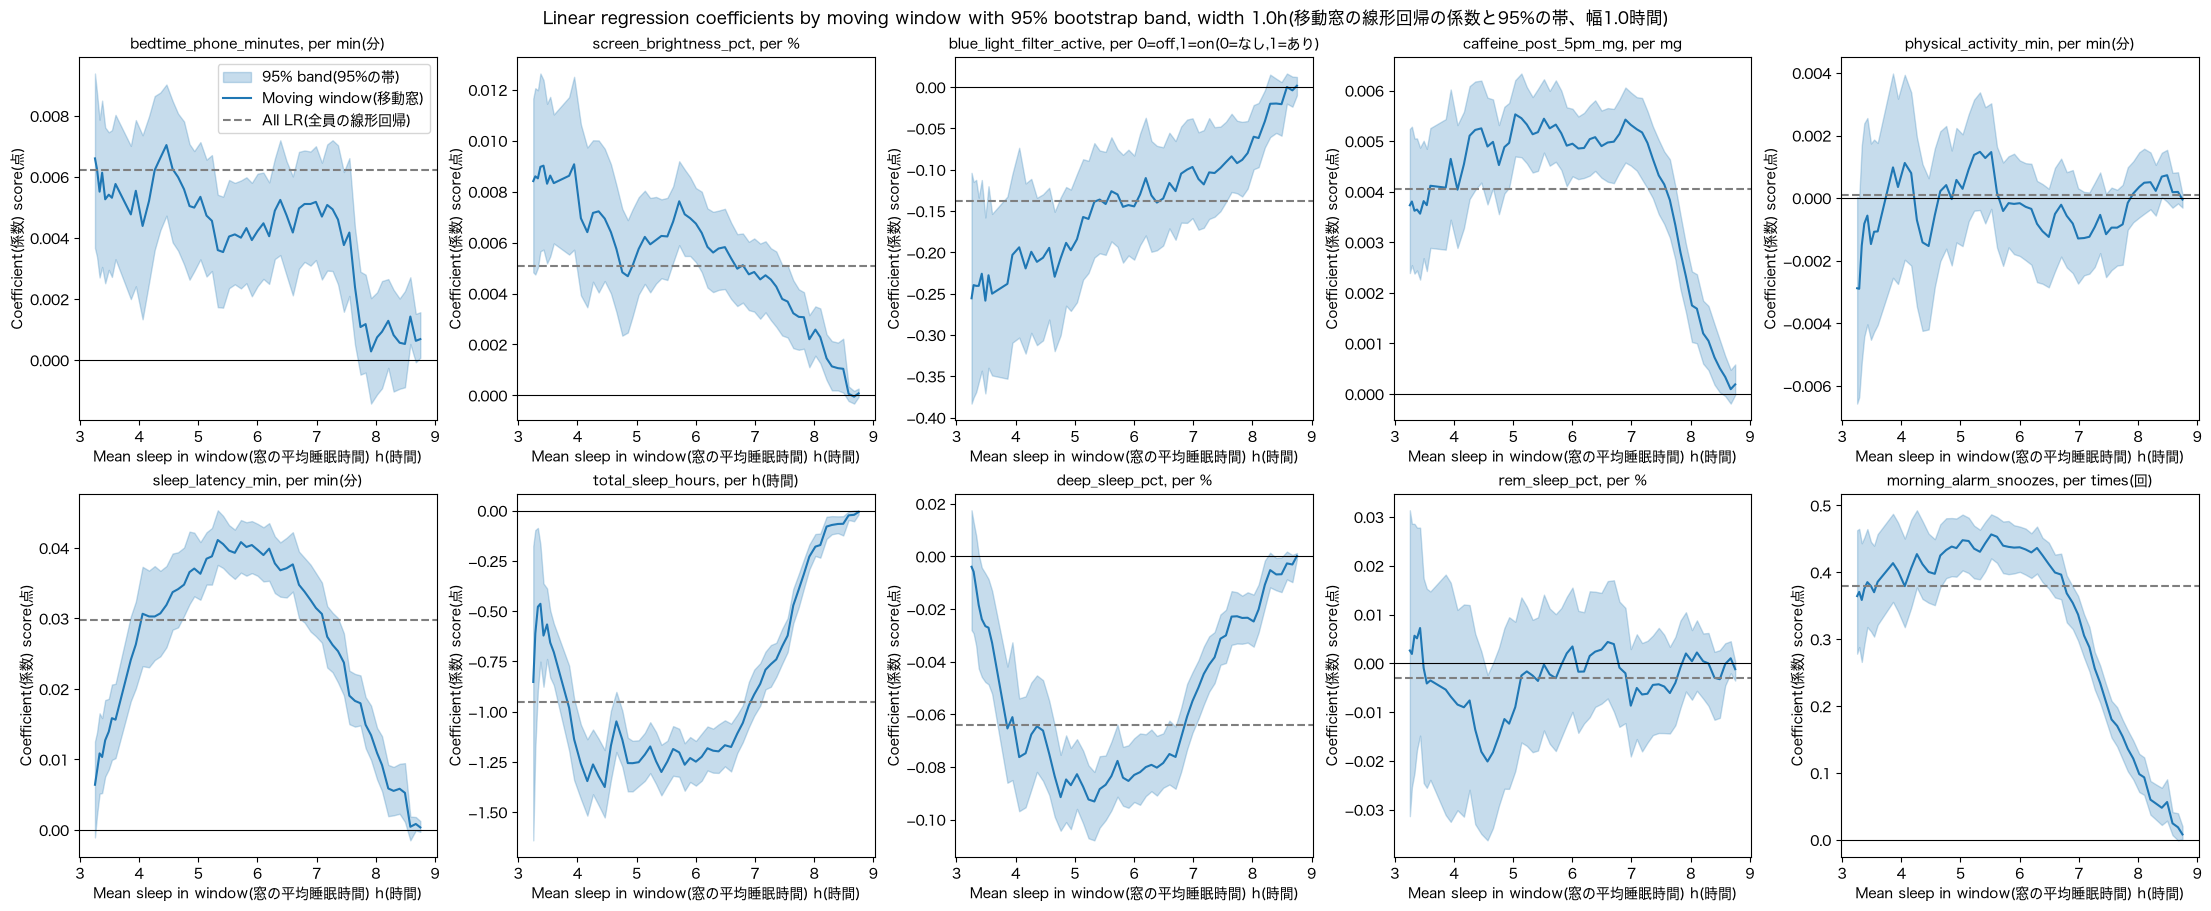

In [22]:
N_BOOT = 200
rng = np.random.default_rng(RANDOM_STATE)

# 選び直したデータで窓を作り直し、7-1 と同じ窓の係数を返す（窓が作れなかったときは NaN）
def window_coefs(X_part, y_part):
    models = fit_windows(X_part, y_part, BEST_WIDTH, LinearRegression)
    table = pd.DataFrame(np.nan, index=lr_centers, columns=FEATURES)
    for center in lr_centers:
        model = models.get(center)
        if model is not None and not isinstance(model, float):
            table.loc[center] = model.coef_
    return table

boot_coefs = []
for b in range(N_BOOT):
    idx = rng.integers(0, len(X_train), len(X_train))
    boot_coefs.append(window_coefs(X_train.iloc[idx], y_train.iloc[idx]).to_numpy())
boot_coefs = np.stack(boot_coefs)  # 形：(回数, 窓, 特徴量)

band_low = pd.DataFrame(np.nanpercentile(boot_coefs, 2.5, axis=0), index=lr_centers, columns=FEATURES)
band_high = pd.DataFrame(np.nanpercentile(boot_coefs, 97.5, axis=0), index=lr_centers, columns=FEATURES)
missing = pd.Series(np.isnan(boot_coefs[:, :, 0]).sum(axis=0), index=lr_centers)

# 特徴量ごとのまとめ：帯の幅と、帯が0を含まない窓の数
band_summary = pd.DataFrame({
    "Mean band width(帯の幅の平均)": (band_high - band_low).mean(),
    "Max band width(帯の幅の最大)": (band_high - band_low).max(),
    "Windows above 0(帯が0より上の窓)": (band_low > 0).sum(),
    "Windows below 0(帯が0より下の窓)": (band_high < 0).sum(),
    "Windows with 0 in band(帯が0を含む窓)": ((band_low <= 0) & (band_high >= 0)).sum(),
    "Unit(単位)": [UNITS[col] for col in FEATURES],
})
band_summary.index.name = "Feature(特徴量)"

print(f"Bootstrap samples(ブートストラップの回数):{N_BOOT}")
print(f"Windows(窓の数):{len(lr_centers)}")
print(f"Windows missing in some samples(作れなかった回がある窓):{int((missing > 0).sum())}")
print(f"Max missing samples in one window(1つの窓で作れなかった回の最大):{int(missing.max())}")
print()
print("Summary by feature(特徴量ごとのまとめ):")
print(band_summary.round(4).to_string())
for col in FEATURES:
    print()
    print(f"{col} {UNITS[col]}:")
    print(pd.DataFrame({
        "Mean sleep(平均睡眠時間) h(時間)": mean_sleep,
        "Coef(係数)": window_coef[col],
        "Band low(帯の下端)": band_low[col],
        "Band high(帯の上端)": band_high[col],
    }).round(4).to_string())

# 図：特徴量ごとの係数の曲線と95%の帯。点線は全員の線形回帰の係数
fig, axes = plt.subplots(2, 5, figsize=(22, 9), layout="constrained")
for ax, col in zip(axes.flatten(), FEATURES):
    ax.fill_between(mean_sleep, band_low[col], band_high[col], color="tab:blue", alpha=0.25, label="95% band(95%の帯)")
    ax.plot(mean_sleep, window_coef[col], color="tab:blue", label="Moving window(移動窓)")
    ax.axhline(base_lr.coef_[FEATURES.index(col)], color="tab:gray", linestyle="--", label="All LR(全員の線形回帰)")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{col}, per {UNITS[col]}", fontsize=10)
    ax.set_xlabel("Mean sleep in window(窓の平均睡眠時間) h(時間)")
    ax.set_ylabel("Coefficient(係数) score(点)")
axes[0, 0].legend()
plt.suptitle(f"Linear regression coefficients by moving window with 95% bootstrap band, width {BEST_WIDTH}h(移動窓の線形回帰の係数と95%の帯、幅{BEST_WIDTH}時間)")
fig.savefig(f"{FIG_DIR}/window_lr_coef.png", dpi=150)
plt.show()

### 7-3:Does the effect change with sleep?(効果は睡眠時間によって変わるか)

- Windows centered at every hour from 3.0 to 8.0h are compared with their neighbor(1時間ごとの中心3.0〜8.0時間の窓を隣どうしで比べる)
- The 3.0h window holds only people with 3.2-3.5h, and many of them have exactly 3.2h, so its total_sleep_hours coefficient is unstable(3.0時間の窓には3.2〜3.5時間の人しかおらず、ちょうど3.2時間の人が多いので、睡眠時間の係数は不安定)
- 9.0h and above cannot be used: everyone there has fatigue 1.0. There is no data above 9.8h(9.0時間以上は疲労が全員1.0なので使えない。9.8時間より長いデータはない)
- With width 1.0h these windows do not share people(幅1.0時間では、これらの窓に同じ人は入らない)
- The difference of coefficients is computed in each of the 200 bootstrap samples. If its 95% range does not include 0, the effect changes between the two windows(200回のブートストラップそれぞれで係数の差を計算し、その95%の範囲が0を含まなければ、2つの窓で効果が違うと考える)
- A range including 0 means a change cannot be shown, not that there is no change(範囲が0を含むときは「違うとは言えない」という意味で、「違わない」という意味ではない)
- 50 comparisons are made (10 features × 5 pairs), so about 2.5 of them can exclude 0 by chance(比べるのは10特徴量×5組＝50回なので、偶然でも2.5回ほどは0を含まなくなりうる)

Compared centers(比べる中心) h(時間):[3.0, 4.0, 5.0, 6.0, 7.0, 8.0]
Comparisons(比べた回数):50
Comparisons excluding 0(0を含まなかった回数):14
Expected by chance at 5%(5%の偶然で起きる回数の目安):2.5

Compared windows(比べた窓):
                  Mean sleep(平均睡眠時間) h(時間)  Train N(学習の人数)  At 3.2h ratio(睡眠3.2時間の割合)
Center(中心) h(時間)                                                                     
3.0                                  3.255             282                      0.691
4.0                                  4.060             569                      0.000
5.0                                  5.036            1186                      0.000
6.0                                  6.003            1636                      0.000
7.0                                  6.988            1649                      0.000
8.0                                  7.920            1118                      0.000

Excludes 0 by feature and pair(特徴量と組ごとの、0を含まないか):
Pair(組)                   3h→4h  4h→5h  5h→6h  6h→7h  7h→8h
Feature(特

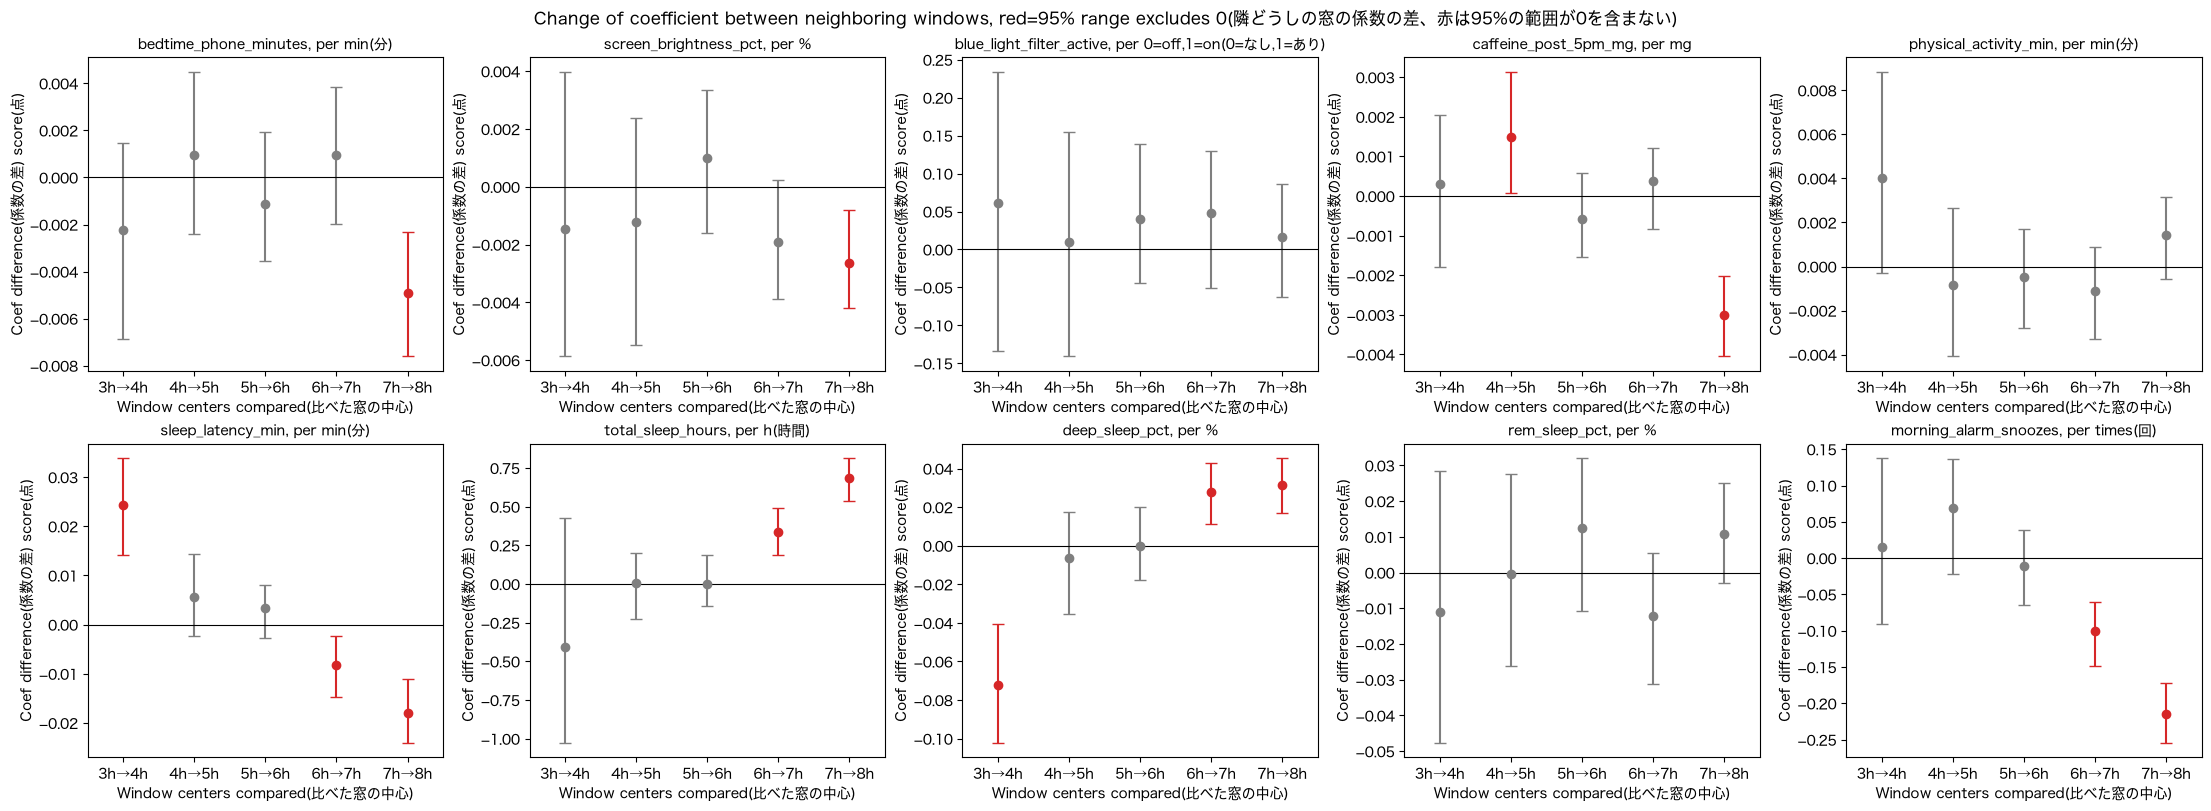

In [23]:
COMPARE_CENTERS = [3.0, 4.0, 5.0, 6.0, 7.0, 8.0]
compare_pairs = list(zip(COMPARE_CENTERS[:-1], COMPARE_CENTERS[1:]))
pos = {c: lr_centers.index(c) for c in COMPARE_CENTERS}

diff_rows = []
for col in FEATURES:
    j = FEATURES.index(col)
    for low_c, high_c in compare_pairs:
        boot_diff = boot_coefs[:, pos[high_c], j] - boot_coefs[:, pos[low_c], j]
        boot_diff = boot_diff[~np.isnan(boot_diff)]
        ci_low, ci_high = np.percentile(boot_diff, [2.5, 97.5])
        diff_rows.append({
            "Feature(特徴量)": col,
            "Pair(組)": f"{low_c:g}h→{high_c:g}h",
            "Coef at low(低い方の係数)": window_coef.loc[low_c, col],
            "Coef at high(高い方の係数)": window_coef.loc[high_c, col],
            "Difference(差＝高-低)": window_coef.loc[high_c, col] - window_coef.loc[low_c, col],
            "CI low(95%の下端)": ci_low,
            "CI high(95%の上端)": ci_high,
            "Excludes 0(0を含まない)": (ci_low > 0) or (ci_high < 0),
            "Unit(単位)": UNITS[col],
        })
diff_table = pd.DataFrame(diff_rows)

pair_mean_sleep = pd.DataFrame({
    "Mean sleep(平均睡眠時間) h(時間)": mean_sleep[COMPARE_CENTERS],
    "Train N(学習の人数)": window_coef.loc[COMPARE_CENTERS, "Train N(学習の人数)"],
    f"At {SLEEP_FLOOR:g}h ratio(睡眠{SLEEP_FLOOR:g}時間の割合)": [X_train.loc[in_window(X_train[SLEEP], c, BEST_WIDTH), SLEEP].eq(SLEEP_FLOOR).mean() for c in COMPARE_CENTERS],
})
pair_mean_sleep.index.name = "Center(中心) h(時間)"
excludes_table = diff_table.pivot(index="Feature(特徴量)", columns="Pair(組)", values="Excludes 0(0を含まない)").loc[FEATURES]

print(f"Compared centers(比べる中心) h(時間):{COMPARE_CENTERS}")
print(f"Comparisons(比べた回数):{len(diff_table)}")
print(f"Comparisons excluding 0(0を含まなかった回数):{int(diff_table['Excludes 0(0を含まない)'].sum())}")
print(f"Expected by chance at 5%(5%の偶然で起きる回数の目安):{len(diff_table) * 0.05:.1f}")
print()
print("Compared windows(比べた窓):")
print(pair_mean_sleep.round(3).to_string())
print()
print("Excludes 0 by feature and pair(特徴量と組ごとの、0を含まないか):")
print(excludes_table.to_string())
print()
print("Details(詳細):")
with pd.option_context("display.float_format", "{:.4f}".format):
    print(diff_table.to_string(index=False))

# 図：隣どうしの窓の係数の差と95%の範囲。0の線から離れていれば効果が変わる
fig, axes = plt.subplots(2, 5, figsize=(22, 8), layout="constrained")
for ax, col in zip(axes.flatten(), FEATURES):
    part = diff_table[diff_table["Feature(特徴量)"] == col].reset_index(drop=True)
    for k, row in part.iterrows():
        color = "tab:red" if row["Excludes 0(0を含まない)"] else "tab:gray"
        ax.errorbar(k, row["Difference(差＝高-低)"],
                    yerr=[[row["Difference(差＝高-低)"] - row["CI low(95%の下端)"]], [row["CI high(95%の上端)"] - row["Difference(差＝高-低)"]]],
                    fmt="o", color=color, capsize=4)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(range(len(part)), part["Pair(組)"])
    ax.set_xlim(-0.5, len(part) - 0.5)
    ax.set_title(f"{col}, per {UNITS[col]}", fontsize=10)
    ax.set_xlabel("Window centers compared(比べた窓の中心)")
    ax.set_ylabel("Coef difference(係数の差) score(点)")
plt.suptitle("Change of coefficient between neighboring windows, red=95% range excludes 0(隣どうしの窓の係数の差、赤は95%の範囲が0を含まない)")
fig.savefig(f"{FIG_DIR}/window_lr_coef_diff.png", dpi=150)
plt.show()

## Step 8:Moving-window random forest(移動窓のランダムフォレスト)

### 8-1:Choosing random forest settings by CV(RFの設定を交差検証で選ぶ)

- One window holds 282-1,688 people, far fewer than the 6,800 used in Step 5, so the settings are chosen again(1つの窓は282〜1,688人で、Step 5 の6,800人よりずっと少ないので、設定を選び直す)
- max_depth 6, 8, 10, 12, no limit × min_samples_leaf 2, 5, 10(深さ6、8、10、12、制限なし × 葉の最小人数2、5、10)
- Same 5 folds and same prediction rule as 6-2. All windows use the same settings(6-2 と同じ5分割と予測のまとめ方。すべての窓で同じ設定を使う)

Width(幅) h(時間):1.0
max_depth candidates(深さの候補):[6, 8, 10, 12, None]
min_samples_leaf candidates(葉の最小人数の候補):[2, 5, 10]
Combinations(組み合わせの数):15
Folds(分割数):5
Best(最良):{'n_estimators': 100, 'max_depth': 10, 'min_samples_leaf': 2}
Best mean CV MSE(最良の交差検証MSEの平均):0.36140
Moving-window LR mean CV MSE from 6-2(6-2 の移動窓の線形回帰の交差検証MSEの平均):0.32829
Tuned all RF CV MSE from Step 5(Step 5 の調整後の全員RFの交差検証MSE):0.36401

CV MSE(交差検証MSE) rows=max_depth(深さ),columns=min_samples_leaf(葉の最小人数):
min_samples_leaf       2        5        10
max_depth                                  
6                 0.37132  0.37174  0.37960
8                 0.36232  0.36446  0.37535
10                0.36140  0.36394  0.37517
12                0.36158  0.36394  0.37516
None              0.36156  0.36397  0.37517

CV MSE by fold(分割ごとの交差検証MSE):
Fold(分割)                          1        2        3        4        5
max_depth min_samples_leaf                                             
6         2                 0.36464  0.380

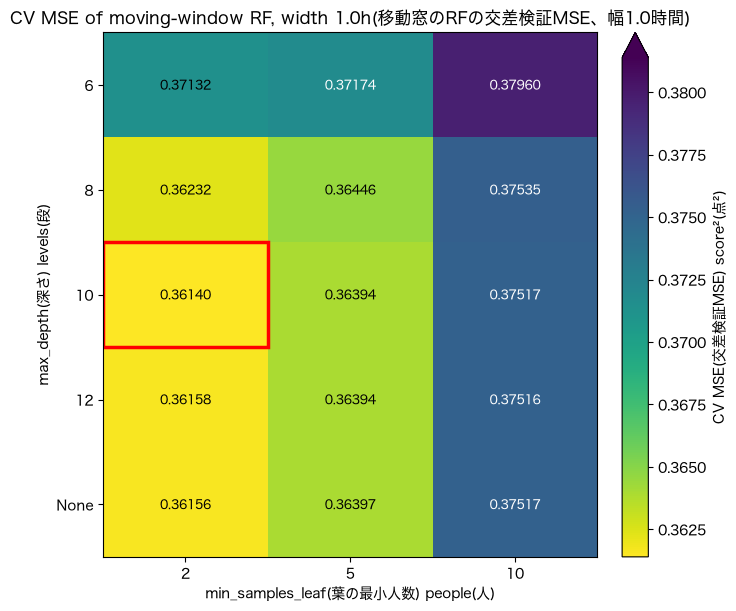

In [24]:
WRF_DEPTHS = [6, 8, 10, 12, None]
WRF_LEAVES = [2, 5, 10]

# 深さ × 葉の最小人数ごとに、5分割それぞれで窓ごとの RF を作り、残した分割を予測する
wrf_rows = []
for depth in WRF_DEPTHS:
    for leaf in WRF_LEAVES:
        make_rf = lambda d=depth, l=leaf: RandomForestRegressor(
            n_estimators=100, max_depth=d, min_samples_leaf=l, random_state=RANDOM_STATE, n_jobs=-1)
        for fold, (tr_idx, va_idx) in enumerate(cv_folds, start=1):
            models = fit_windows(X_train.iloc[tr_idx], y_train.iloc[tr_idx], BEST_WIDTH, make_rf)
            pred, _ = predict_windows(models, X_train.iloc[va_idx], BEST_WIDTH)
            wrf_rows.append({"max_depth": str(depth), "min_samples_leaf": leaf, "Fold(分割)": fold,
                             "MSE": mean_squared_error(y_train.iloc[va_idx], pred)})
wrf_cv = pd.DataFrame(wrf_rows)
wrf_table = wrf_cv.pivot_table(index="max_depth", columns="min_samples_leaf", values="MSE", aggfunc="mean").loc[[str(d) for d in WRF_DEPTHS]]
best_depth, best_leaf = wrf_table.stack().idxmin()
WINDOW_RF_PARAMS = {"n_estimators": 100, "max_depth": None if best_depth == "None" else int(best_depth), "min_samples_leaf": int(best_leaf)}
window_lr_cv = width_cv[f"Width {BEST_WIDTH}h MSE(幅{BEST_WIDTH}時間のMSE)"].mean()

print(f"Width(幅) h(時間):{BEST_WIDTH}")
print(f"max_depth candidates(深さの候補):{WRF_DEPTHS}")
print(f"min_samples_leaf candidates(葉の最小人数の候補):{WRF_LEAVES}")
print(f"Combinations(組み合わせの数):{len(WRF_DEPTHS) * len(WRF_LEAVES)}")
print(f"Folds(分割数):{len(cv_folds)}")
print(f"Best(最良):{WINDOW_RF_PARAMS}")
print(f"Best mean CV MSE(最良の交差検証MSEの平均):{wrf_table.values.min():.5f}")
print(f"Moving-window LR mean CV MSE from 6-2(6-2 の移動窓の線形回帰の交差検証MSEの平均):{window_lr_cv:.5f}")
print(f"Tuned all RF CV MSE from Step 5(Step 5 の調整後の全員RFの交差検証MSE):{-search.best_score_:.5f}")
print()
print("CV MSE(交差検証MSE) rows=max_depth(深さ),columns=min_samples_leaf(葉の最小人数):")
print(wrf_table.round(5).to_string())
print()
print("CV MSE by fold(分割ごとの交差検証MSE):")
print(wrf_cv.pivot_table(index=["max_depth", "min_samples_leaf"], columns="Fold(分割)", values="MSE").loc[[str(d) for d in WRF_DEPTHS]].round(5).to_string())

# ヒートマップ。色の範囲は Step 5 と同じく最良値から +COLOR_RANGE まで。赤枠が最良
vmin = wrf_table.values.min()
vmax = vmin + COLOR_RANGE
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
im = ax.imshow(wrf_table, cmap="viridis_r", aspect="auto", vmin=vmin, vmax=vmax)
for i in range(wrf_table.shape[0]):
    for j in range(wrf_table.shape[1]):
        value = wrf_table.iloc[i, j]
        ax.text(j, i, f"{value:.5f}", ha="center", va="center", fontsize=9,
                color="black" if value < vmin + COLOR_RANGE / 2 else "white")
best_i = wrf_table.index.get_loc(best_depth)
best_j = wrf_table.columns.get_loc(best_leaf)
ax.add_patch(plt.Rectangle((best_j - 0.5, best_i - 0.5), 1, 1, fill=False, edgecolor="red", linewidth=2.5))
ax.set_xticks(range(wrf_table.shape[1]), wrf_table.columns)
ax.set_yticks(range(wrf_table.shape[0]), wrf_table.index)
ax.set_xlabel("min_samples_leaf(葉の最小人数) people(人)")
ax.set_ylabel("max_depth(深さ) levels(段)")
ax.set_title(f"CV MSE of moving-window RF, width {BEST_WIDTH}h(移動窓のRFの交差検証MSE、幅{BEST_WIDTH}時間)")
fig.colorbar(im, ax=ax, extend="max", label="CV MSE(交差検証MSE) score²(点²)")
plt.show()

### 8-2:SHAP slope curves(SHAPの傾きの曲線)

- One random forest per window, with the same width and windows as Step 7(Step 7 と同じ幅と窓で、窓ごとに RF を1つ作る)
- Settings are the ones chosen in 8-1(設定は 8-1 で選んだもの)
- SHAP values are computed for the training people in each window(SHAP 値は、各窓の学習データの人について計算する)
- SHAP slope:the slope of a straight line fitted to SHAP value against feature value in the window. It has the same unit as a linear regression coefficient(SHAP の傾き：窓の中で SHAP 値を特徴量の値に直線で当てはめた傾き。線形回帰の係数と同じ単位になる)
- No bootstrap band is drawn, because 200 samples would take about 6 hours. The curves are compared with the linear regression curves and their bands(200回のブートストラップは約6時間かかるので帯は付けない。線形回帰の曲線と帯と比べる)

In [25]:
import shap

make_window_rf = lambda: RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **WINDOW_RF_PARAMS)
window_rf = fit_windows(X_train, y_train, BEST_WIDTH, make_window_rf)
rf_centers = [c for c, m in window_rf.items() if not isinstance(m, float)]

# 窓ごとの SHAP の傾きと、平均|SHAP|の割合
slope_rows, share_rows = [], []
for center in rf_centers:
    mask = in_window(X_train[SLEEP], center, BEST_WIDTH)
    X_w = X_train[mask]
    shap_w = shap.TreeExplainer(window_rf[center]).shap_values(X_w)
    slopes = {}
    for j, col in enumerate(FEATURES):
        x = X_w[col].to_numpy()
        slopes[col] = np.cov(x, shap_w[:, j])[0, 1] / x.var(ddof=1) if x.var() > 0 else np.nan
    slope_rows.append({"Center(中心) h(時間)": center, **slopes})
    mean_abs = np.abs(shap_w).mean(axis=0)
    share_rows.append({"Center(中心) h(時間)": center, **dict(zip(FEATURES, mean_abs / mean_abs.sum() * 100))})
shap_slope = pd.DataFrame(slope_rows).set_index("Center(中心) h(時間)")
shap_share = pd.DataFrame(share_rows).set_index("Center(中心) h(時間)")

# 線形回帰の係数との比べ：同じ向きの窓の割合と、相関
compare_rows = []
for col in FEATURES:
    lr, rf = window_coef.loc[rf_centers, col], shap_slope[col]
    in_band = (rf >= band_low.loc[rf_centers, col]) & (rf <= band_high.loc[rf_centers, col])
    compare_rows.append({
        "Feature(特徴量)": col,
        "Same sign(同じ向きの窓の割合)": (np.sign(lr) == np.sign(rf)).mean(),
        "Correlation(相関)": lr.corr(rf),
        "RF slope in LR band(RFの傾きがLRの帯に入る窓の割合)": in_band.mean(),
        "Median RF slope / LR coef(RFの傾き÷LRの係数の中央値)": (rf / lr).median(),
        "Unit(単位)": UNITS[col],
    })
rf_lr_compare = pd.DataFrame(compare_rows).set_index("Feature(特徴量)")

print(f"RF settings(RFの設定):{WINDOW_RF_PARAMS}")
print(f"Windows with a model(モデルを作った窓):{len(rf_centers)}")
print(f"Same windows as linear regression(線形回帰と同じ窓か):{rf_centers == lr_centers}")
print()
print("RF SHAP slope vs LR coefficient(RFのSHAPの傾きと線形回帰の係数の比べ):")
print(rf_lr_compare.round(3).to_string())
print()
print("SHAP slope by window(窓ごとのSHAPの傾き):")
print(shap_slope.round(4).to_string())
print()
print("Share of mean |SHAP| by window(窓ごとの平均|SHAP|の割合) %:")
print(shap_share.round(2).to_string())

/Users/ch1nam1/Documents/ICU/isc353_TopicsInInformationScience/final_report/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


RF settings(RFの設定):{'n_estimators': 100, 'max_depth': 10, 'min_samples_leaf': 2}
Windows with a model(モデルを作った窓):60
Same windows as linear regression(線形回帰と同じ窓か):True

RF SHAP slope vs LR coefficient(RFのSHAPの傾きと線形回帰の係数の比べ):
                          Same sign(同じ向きの窓の割合)  Correlation(相関)  RF slope in LR band(RFの傾きがLRの帯に入る窓の割合)  Median RF slope / LR coef(RFの傾き÷LRの係数の中央値)               Unit(単位)
Feature(特徴量)                                                                                                                                                              
bedtime_phone_minutes                    1.000            0.244                                   0.217                                       0.230                 min(分)
screen_brightness_pct                    0.983            0.936                                   0.100                                       0.462                      %
blue_light_filter_active                 0.983            0.895                               

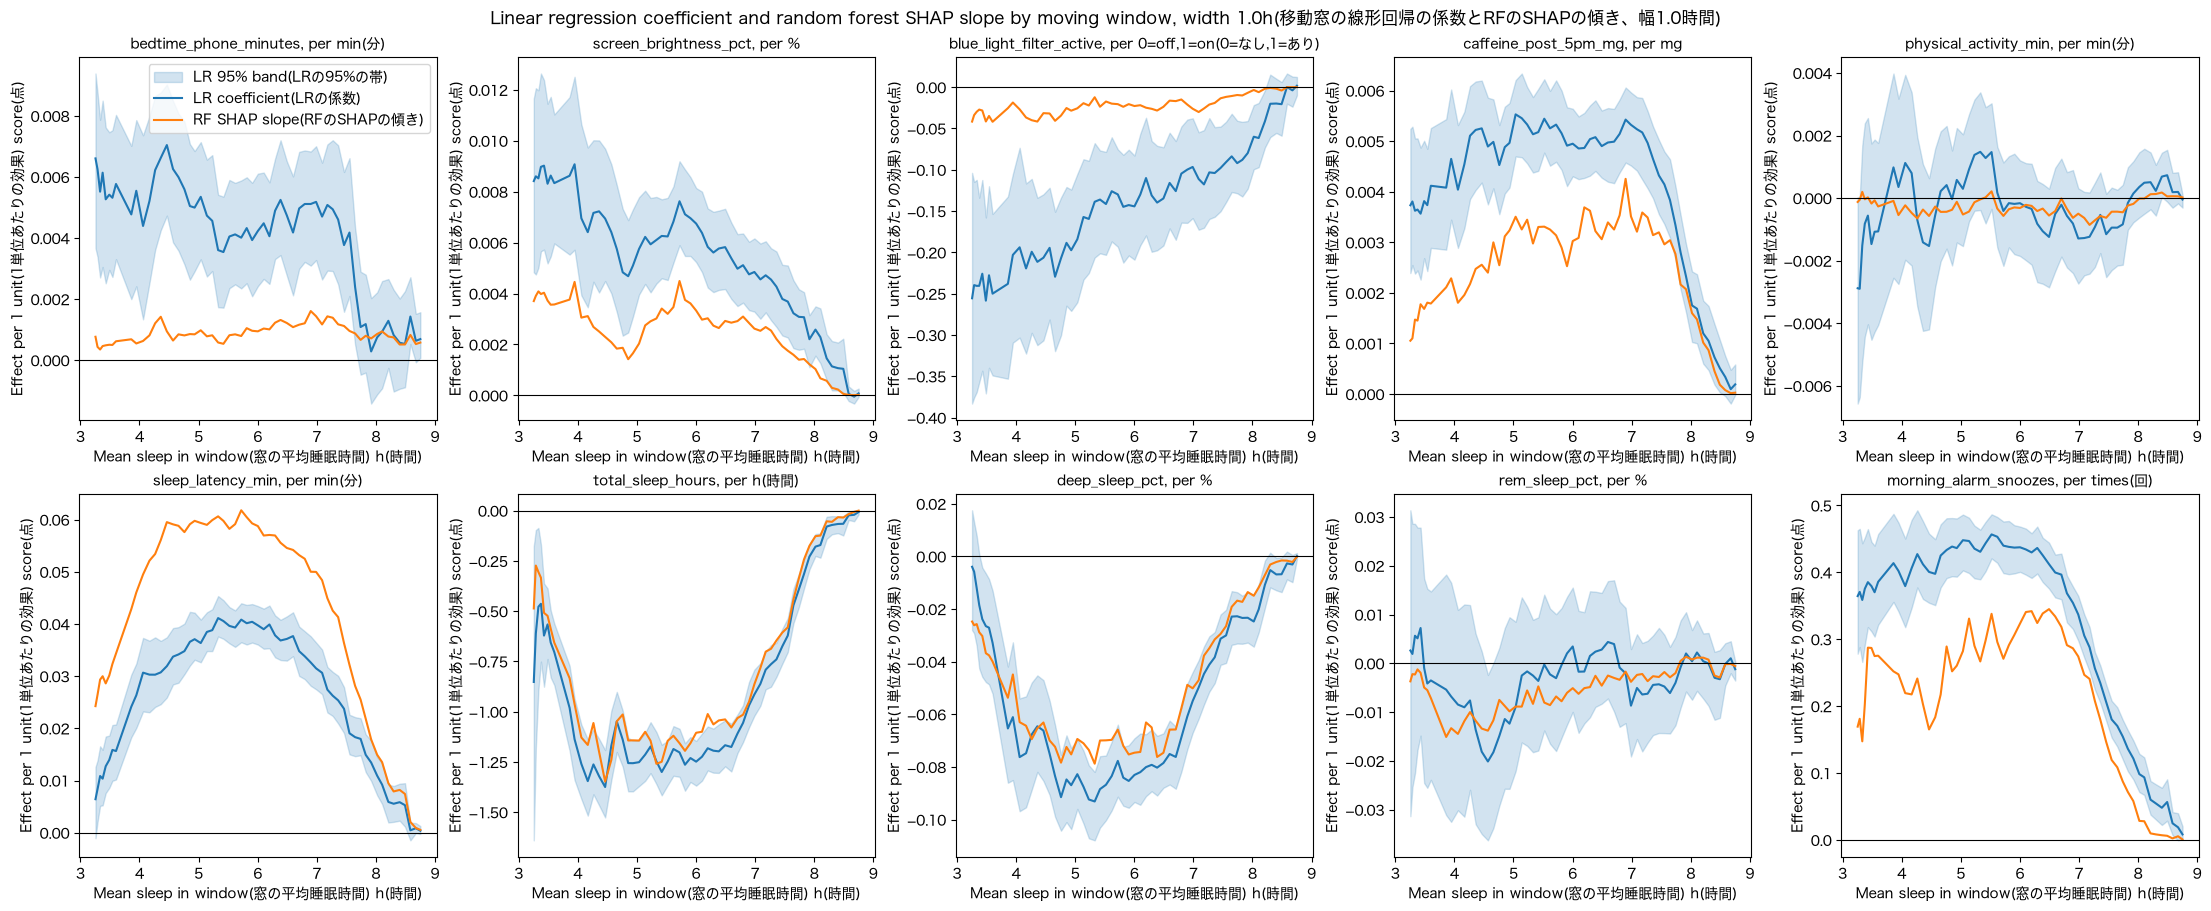

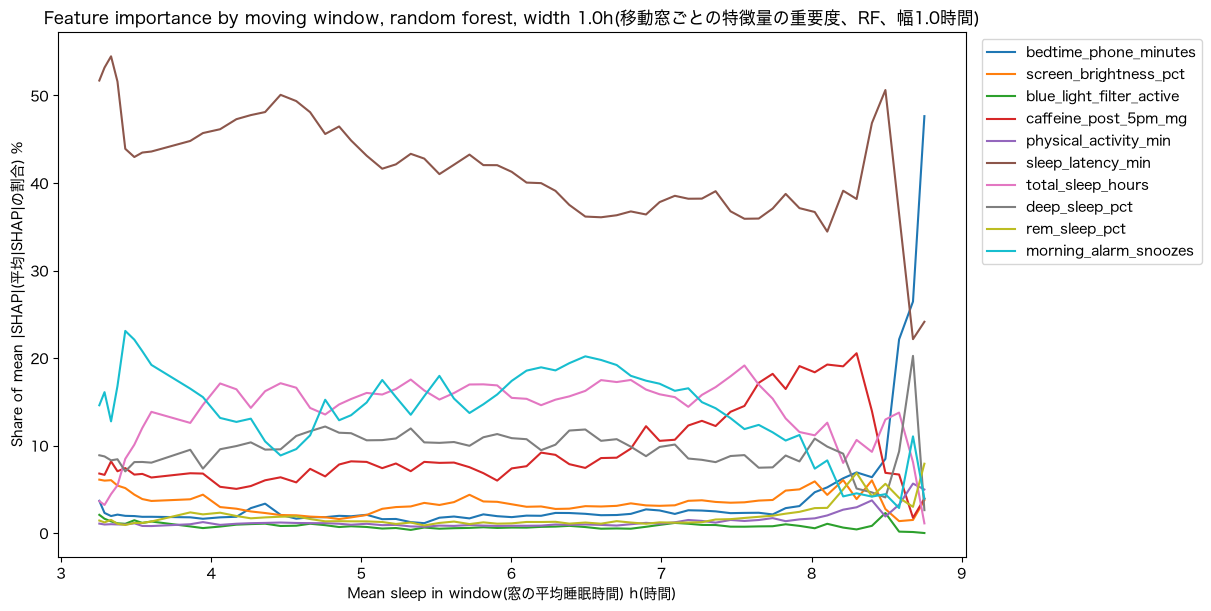

In [26]:
# 図1：特徴量ごとに、線形回帰の係数（帯つき）と RF の SHAP の傾きを重ねる
fig, axes = plt.subplots(2, 5, figsize=(22, 9), layout="constrained")
for ax, col in zip(axes.flatten(), FEATURES):
    ax.fill_between(mean_sleep, band_low[col], band_high[col], color="tab:blue", alpha=0.2, label="LR 95% band(LRの95%の帯)")
    ax.plot(mean_sleep, window_coef[col], color="tab:blue", label="LR coefficient(LRの係数)")
    ax.plot(mean_sleep[rf_centers], shap_slope[col], color="tab:orange", label="RF SHAP slope(RFのSHAPの傾き)")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{col}, per {UNITS[col]}", fontsize=10)
    ax.set_xlabel("Mean sleep in window(窓の平均睡眠時間) h(時間)")
    ax.set_ylabel("Effect per 1 unit(1単位あたりの効果) score(点)")
axes[0, 0].legend()
plt.suptitle(f"Linear regression coefficient and random forest SHAP slope by moving window, width {BEST_WIDTH}h(移動窓の線形回帰の係数とRFのSHAPの傾き、幅{BEST_WIDTH}時間)")
fig.savefig(f"{FIG_DIR}/window_rf_shap_slope.png", dpi=150)
plt.show()

# 図2：窓ごとの平均|SHAP|の割合（どの特徴量がどれだけ効いているか）
fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
for col in FEATURES:
    ax.plot(mean_sleep[rf_centers], shap_share[col], label=col)
ax.set_xlabel("Mean sleep in window(窓の平均睡眠時間) h(時間)")
ax.set_ylabel("Share of mean |SHAP|(平均|SHAP|の割合) %")
ax.set_title(f"Feature importance by moving window, random forest, width {BEST_WIDTH}h(移動窓ごとの特徴量の重要度、RF、幅{BEST_WIDTH}時間)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
fig.savefig(f"{FIG_DIR}/window_rf_shap_share.png", dpi=150)
plt.show()

## Step 9:Comparing models by sleep range(睡眠時間の区間ごとのモデルの比較)

### 9-1:CV MSE and R² by range(区間ごとの交差検証MSEとR²)

- 10-fold CV inside the training data, stratified by the 10-minute sleep bins of Step 4(学習データの中で10分割交差検証。Step 4 の10分ごとの区切りで層化する)
- 10 folds instead of 5, so that the t-test in 9-3 has 10 pairs(9-3 の t検定で10組を使えるように、5分割ではなく10分割にする)
- Five models with the settings already chosen in Steps 5-8, not tuned again(Step 5〜8 で選んだ設定の5つのモデル。設定は選び直さない)
  - All LR:one linear regression for everyone(全員の線形回帰)
  - All RF:one random forest for everyone(全員のRF)
  - Group LR:one linear regression per sleep group of Step 4(Step 4 の睡眠時間グループごとの線形回帰)
  - Window LR:moving-window linear regression of Step 7(Step 7 の移動窓の線形回帰)
  - Window RF:moving-window random forest of Step 8(Step 8 の移動窓のRF)
- Ranges are the sleep groups of Step 4:-5h, 5-6h, 6-7h, 7-8h, 8h+(区間は Step 4 の睡眠時間グループ)
- MSE is computed in each fold and range, then averaged over the 10 folds(MSE は分割ごと・区間ごとに計算し、10分割で平均する)
- R² is computed per range from the predictions of all 6,800 people together, because one fold of a range has few people(R² は、1つの分割の区間には人が少ないので、6,800人分の予測をまとめて区間ごとに計算する)
- In the same range all models share the same fatigue variance, so a smaller MSE always means a larger R²(同じ区間ではどのモデルも疲労の分散が同じなので、MSE が小さいほど R² は大きい)

In [27]:
from scipy import stats

# 評価用の分割：学習データを10分ごとの区切りで層化して10に分ける
N_EVAL_FOLDS = 10
eval_folds = list(StratifiedKFold(n_splits=N_EVAL_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X_train, strata_train))

def sleep_group(X_part):
    return pd.cut(X_part[SLEEP], bins=SLEEP_BINS, labels=GROUPS, right=False)

# 睡眠時間グループごとに線形回帰を1つずつ作り、予測する
def fit_predict_group_lr(X_tr, y_tr, X_va):
    g_tr, g_va = sleep_group(X_tr), sleep_group(X_va)
    pred = np.zeros(len(X_va))
    for name in GROUPS:
        mask = (g_va == name).to_numpy()
        if mask.any():
            pred[mask] = LinearRegression().fit(X_tr[g_tr == name], y_tr[g_tr == name]).predict(X_va[mask])
    return pred

# 比べるモデル：(学習のX, 学習のy, 予測するX) を受け取り、予測を返す関数。Step 10 でも使う
MODELS = {
    "All LR(全員の線形回帰)": lambda X_tr, y_tr, X_va: LinearRegression().fit(X_tr, y_tr).predict(X_va),
    "All RF(全員のRF)": lambda X_tr, y_tr, X_va: RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **search.best_params_).fit(X_tr, y_tr).predict(X_va),
    "Group LR(グループ別の線形回帰)": fit_predict_group_lr,
    "Window LR(移動窓の線形回帰)": lambda X_tr, y_tr, X_va: predict_windows(fit_windows(X_tr, y_tr, BEST_WIDTH, LinearRegression), X_va, BEST_WIDTH)[0],
    "Window RF(移動窓のRF)": lambda X_tr, y_tr, X_va: predict_windows(fit_windows(X_tr, y_tr, BEST_WIDTH, make_window_rf), X_va, BEST_WIDTH)[0],
}
MODEL_NAMES = list(MODELS)
ALL = "All(全体)"
RANGES = GROUPS + [ALL]

# 分割ごとに、各モデルで残した分割の人を予測する（6,800人分の予測を1つの表にためる）
oof_pred = pd.DataFrame(index=X_train.index, columns=MODEL_NAMES, dtype=float)
oof_fold = pd.Series(0, index=X_train.index)
for fold, (tr_idx, va_idx) in enumerate(eval_folds, start=1):
    X_tr, y_tr, X_va = X_train.iloc[tr_idx], y_train.iloc[tr_idx], X_train.iloc[va_idx]
    for name, fit_predict in MODELS.items():
        oof_pred.iloc[va_idx, MODEL_NAMES.index(name)] = fit_predict(X_tr, y_tr, X_va)
    oof_fold.iloc[va_idx] = fold

def range_mask(groups, name):
    return pd.Series(True, index=groups.index) if name == ALL else groups == name

# 分割ごと・区間ごとのMSE（行：区間と分割、列：モデル）
def fold_range_mse(pred_table):
    rows = []
    for name in RANGES:
        for fold in range(1, N_EVAL_FOLDS + 1):
            mask = range_mask(group_train, name) & (oof_fold == fold)
            err = pred_table[mask].sub(y_train[mask], axis=0) ** 2
            rows.append({"Range(区間)": name, "Fold(分割)": fold, **err.mean().to_dict()})
    return pd.DataFrame(rows).set_index(["Range(区間)", "Fold(分割)"])

# 区間ごとの R²（6,800人分の予測をまとめて計算）
def range_r2(pred_table):
    return pd.DataFrame({
        name: {col: r2_score(y_train[range_mask(group_train, name)], pred_table.loc[range_mask(group_train, name), col]) for col in pred_table.columns}
        for name in RANGES
    }).T

fold_mse = fold_range_mse(oof_pred)
range_mse = fold_mse.groupby(level=0, sort=False).mean()
range_mse_std = fold_mse.groupby(level=0, sort=False).std()
range_r2_table = range_r2(oof_pred)
range_info = pd.DataFrame({
    "Train N(学習の人数)": [int(range_mask(group_train, n).sum()) for n in RANGES],
    "Fatigue mean(疲労の平均)": [y_train[range_mask(group_train, n)].mean() for n in RANGES],
    "Fatigue var(疲労の分散)": [y_train[range_mask(group_train, n)].var(ddof=0) for n in RANGES],
}, index=RANGES)
range_info.index.name = "Range(区間)"
fold_n = oof_fold.value_counts()

print(f"Folds(分割数):{N_EVAL_FOLDS}")
print(f"Validation N per fold(分割ごとの検証の人数):{fold_n.min()}-{fold_n.max()}")
print(f"Models(モデル):{MODEL_NAMES}")
print(f"Window width(窓の幅) h(時間):{BEST_WIDTH}")
print(f"All RF settings(全員のRFの設定):{search.best_params_}")
print(f"Window RF settings(移動窓のRFの設定):{WINDOW_RF_PARAMS}")
print()
print("Ranges(区間):")
print(range_info.round(4).to_string())
print()
print("Mean CV MSE by range(区間ごとの交差検証MSEの平均) score²(点²):")
print(range_mse.round(5).to_string())
print()
print("Std of CV MSE over folds by range(区間ごとの交差検証MSEの分割間の標準偏差) score²(点²):")
print(range_mse_std.round(5).to_string())
print()
print("R2 by range from all predictions(区間ごとのR2、全員分の予測から):")
print(range_r2_table.round(4).to_string())

Folds(分割数):10
Validation N per fold(分割ごとの検証の人数):680-680
Models(モデル):['All LR(全員の線形回帰)', 'All RF(全員のRF)', 'Group LR(グループ別の線形回帰)', 'Window LR(移動窓の線形回帰)', 'Window RF(移動窓のRF)']
Window width(窓の幅) h(時間):1.0
All RF settings(全員のRFの設定):{'max_depth': 11, 'min_samples_leaf': 2, 'n_estimators': 100}
Window RF settings(移動窓のRFの設定):{'n_estimators': 100, 'max_depth': 10, 'min_samples_leaf': 2}

Ranges(区間):
           Train N(学習の人数)  Fatigue mean(疲労の平均)  Fatigue var(疲労の分散)
Range(区間)                                                         
-5h                  1371               7.6587              3.1617
5-6h                 1456               4.8571              2.4358
6-7h                 1678               2.9759              1.8235
7-8h                 1509               1.5600              0.7311
8h+                   786               1.0416              0.0489
All(全体)              6800               3.7850              7.1785

Mean CV MSE by range(区間ごとの交差検証MSEの平均) score²(点²):
           All LR(全

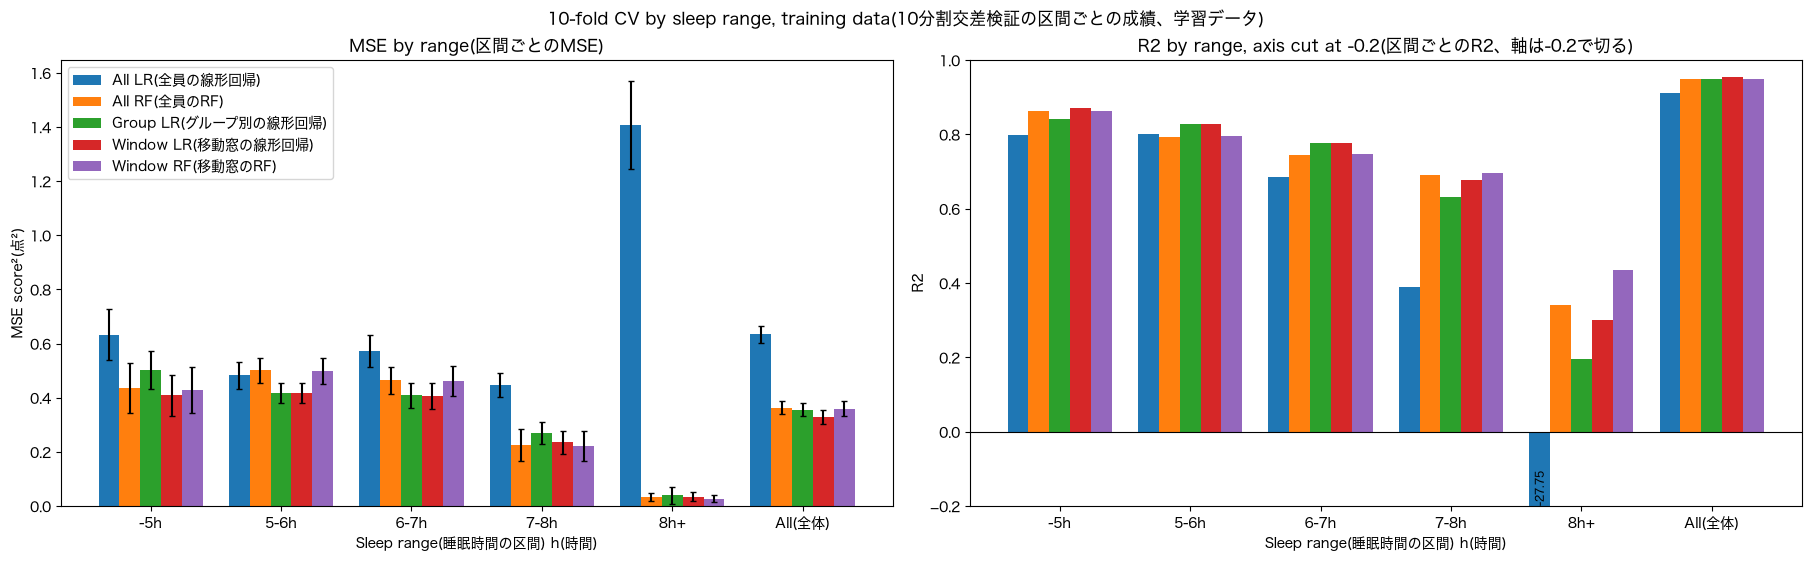

In [28]:
# 図：区間ごとの交差検証MSE（棒は10分割の平均、線は分割間の標準偏差）と R²
# R² の軸の下限。全員の線形回帰の 8h+ のように大きくマイナスになる値に軸を合わせると、ほかの棒が読めなくなるため
R2_FLOOR = -0.2
def plot_by_range(mse_table, mse_err, r2_table, title, path):
    fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), layout="constrained")
    names = list(mse_table.columns)
    bar_w = 0.8 / len(names)
    x = np.arange(len(RANGES))
    for k, name in enumerate(names):
        offset = (k - (len(names) - 1) / 2) * bar_w
        axes[0].bar(x + offset, mse_table.loc[RANGES, name], bar_w,
                    yerr=None if mse_err is None else mse_err.loc[RANGES, name], capsize=2, label=name)
        r2 = r2_table.loc[RANGES, name]
        axes[1].bar(x + offset, r2.clip(lower=R2_FLOOR), bar_w, label=name)
        # 下限より小さい R² は下限で切り、本当の値を書く
        for k_range, value in enumerate(r2):
            if value < R2_FLOOR:
                axes[1].text(x[k_range] + offset, R2_FLOOR, f"{value:.2f}", rotation=90, ha="center", va="bottom", fontsize=8)
    for ax in axes:
        ax.set_xticks(x, RANGES)
        ax.set_xlabel("Sleep range(睡眠時間の区間) h(時間)")
    axes[0].set_ylabel("MSE score²(点²)")
    axes[0].set_title("MSE by range(区間ごとのMSE)")
    axes[1].axhline(0, color="black", linewidth=0.8)
    axes[1].set_ylim(R2_FLOOR, 1)
    axes[1].set_ylabel("R2")
    axes[1].set_title(f"R2 by range, axis cut at {R2_FLOOR}(区間ごとのR2、軸は{R2_FLOOR}で切る)")
    axes[0].legend()
    plt.suptitle(title)
    fig.savefig(path, dpi=150)
    plt.show()

plot_by_range(range_mse[MODEL_NAMES], range_mse_std[MODEL_NAMES], range_r2_table[MODEL_NAMES],
              f"{N_EVAL_FOLDS}-fold CV by sleep range, training data({N_EVAL_FOLDS}分割交差検証の区間ごとの成績、学習データ)",
              f"{FIG_DIR}/range_cv.png")

### 9-2:Best model by range(区間別の最良モデル)

- In each range, the model with the smallest mean CV MSE in 9-1 is chosen(区間ごとに、9-1 の交差検証MSEの平均が一番小さいモデルを選ぶ)
- The combined model predicts each person with the model chosen for their sleep range(区間別の最良モデルは、その人の睡眠時間の区間で選ばれたモデルで予測する)
- The choice is made only with training data. Test data is used once in Step 10(選ぶのは学習データだけで行う。テストデータは Step 10 で1回だけ使う)
- The CV score of the combined model is a little too good, because the same CV was used to choose it. Its fair score is the test score in Step 10(同じ交差検証で選んだので、区間別の最良モデルの交差検証の成績は少し良く出る。公平な成績は Step 10 のテストの値)

Chosen model by range(区間ごとに選んだモデル):
-5h:Window LR(移動窓の線形回帰)
5-6h:Group LR(グループ別の線形回帰)
6-7h:Window LR(移動窓の線形回帰)
7-8h:Window RF(移動窓のRF)
8h+:Window RF(移動窓のRF)
Best single model overall(全体で一番良い単独のモデル):Window LR(移動窓の線形回帰)
Best single model mean CV MSE(全体で一番良い単独のモデルの交差検証MSEの平均):0.32847
Best by range mean CV MSE(区間別の最良モデルの交差検証MSEの平均):0.32488
Difference, best by range - best single(差、区間別の最良モデル-単独で一番良いモデル):-0.00360

Choice by range(区間ごとの選択) MSE score²(点²):
             Best model(最良のモデル)  Best MSE(最良のMSE) Second model(2番目のモデル)  Second MSE(2番目のMSE)  All LR MSE(全員の線形回帰のMSE)  Second-best(2番目-最良)  Best R2(最良のR2)
Range(区間)                                                                                                                                                 
-5h         Window LR(移動窓の線形回帰)           0.40894     Window RF(移動窓のRF)              0.43011                  0.63369              0.02117         0.87066
5-6h       Group LR(グループ別の線形回帰)           0.41841   Window LR(移動窓の線形回帰)            

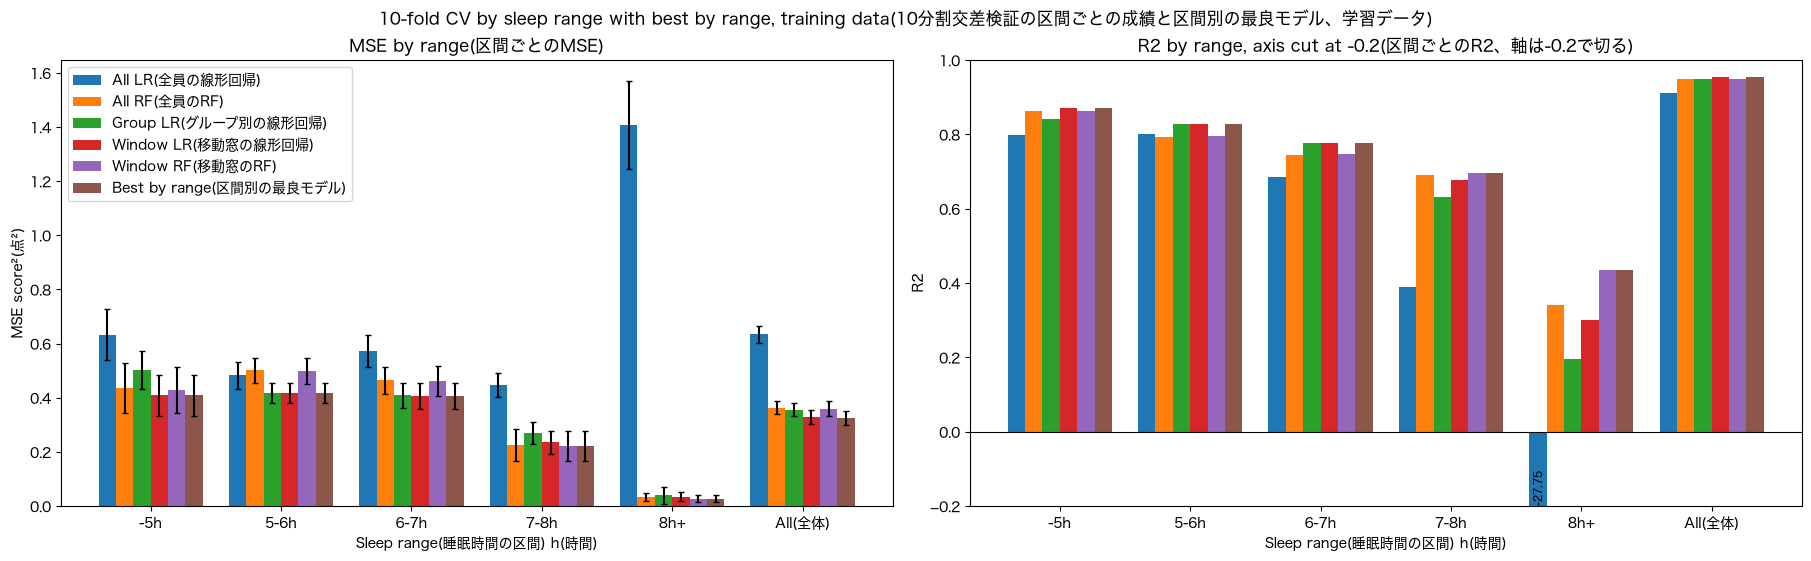

In [29]:
# 区間ごとに、交差検証MSEの平均が一番小さいモデルを選ぶ（全体の行は使わない）
range_rank = range_mse.loc[GROUPS, MODEL_NAMES]
best_by_range = range_rank.idxmin(axis=1)
second_by_range = range_rank.apply(lambda row: row.sort_values().index[1], axis=1)

# 区間別の最良モデルの予測：その人の区間で選ばれたモデルの予測を使う
def combine_by_range(pred_table, groups):
    out = pd.Series(np.nan, index=pred_table.index)
    for name, model in best_by_range.items():
        mask = groups == name
        out[mask] = pred_table.loc[mask, model]
    return out

HYBRID = "Best by range(区間別の最良モデル)"
oof_pred[HYBRID] = combine_by_range(oof_pred[MODEL_NAMES], group_train)
fold_mse = fold_range_mse(oof_pred)
range_mse = fold_mse.groupby(level=0, sort=False).mean()
range_mse_std = fold_mse.groupby(level=0, sort=False).std()
range_r2_table = range_r2(oof_pred)

choice_table = pd.DataFrame({
    "Best model(最良のモデル)": best_by_range,
    "Best MSE(最良のMSE)": [range_rank.loc[n, m] for n, m in best_by_range.items()],
    "Second model(2番目のモデル)": second_by_range,
    "Second MSE(2番目のMSE)": [range_rank.loc[n, m] for n, m in second_by_range.items()],
    "All LR MSE(全員の線形回帰のMSE)": range_rank["All LR(全員の線形回帰)"],
})
choice_table["Second-best(2番目-最良)"] = choice_table["Second MSE(2番目のMSE)"] - choice_table["Best MSE(最良のMSE)"]
choice_table["Best R2(最良のR2)"] = [range_r2_table.loc[n, m] for n, m in best_by_range.items()]
choice_table.index.name = "Range(区間)"

best_single = range_mse.loc[ALL, MODEL_NAMES].idxmin()
overall_table = pd.DataFrame({
    "Mean CV MSE(交差検証MSEの平均)": range_mse.loc[ALL],
    "Std over folds(分割間の標準偏差)": range_mse_std.loc[ALL],
    "R2": range_r2_table.loc[ALL],
})
overall_table.index.name = "Model(モデル)"

print("Chosen model by range(区間ごとに選んだモデル):")
for name, model in best_by_range.items():
    print(f"{name}:{model}")
print(f"Best single model overall(全体で一番良い単独のモデル):{best_single}")
print(f"Best single model mean CV MSE(全体で一番良い単独のモデルの交差検証MSEの平均):{range_mse.loc[ALL, best_single]:.5f}")
print(f"Best by range mean CV MSE(区間別の最良モデルの交差検証MSEの平均):{range_mse.loc[ALL, HYBRID]:.5f}")
print(f"Difference, best by range - best single(差、区間別の最良モデル-単独で一番良いモデル):{range_mse.loc[ALL, HYBRID] - range_mse.loc[ALL, best_single]:.5f}")
print()
print("Choice by range(区間ごとの選択) MSE score²(点²):")
print(choice_table.round(5).to_string())
print()
print("Overall CV(全体の交差検証):")
print(overall_table.round(5).to_string())

plot_by_range(range_mse, range_mse_std, range_r2_table,
              f"{N_EVAL_FOLDS}-fold CV by sleep range with best by range, training data({N_EVAL_FOLDS}分割交差検証の区間ごとの成績と区間別の最良モデル、学習データ)",
              f"{FIG_DIR}/range_cv_best.png")

### 9-3:CV t-test with the Nadeau-Bengio correction(Nadeau–Bengio の補正つき交差検証の t検定)

- The 10 per-fold MSE differences d between two models are tested(2つのモデルの、分割ごとのMSEの差 d の10個を検定する)
- The training parts of the folds overlap, so the usual t-test is too optimistic. The variance of the mean is enlarged from s²/J to (1/J + n_test/n_train)·s²(分割どうしで学習データが重なるので、普通の t検定では有意になりやすい。平均の分散を s²/J から (1/J + n_test/n_train)·s² に大きくする)
- J = 10 folds, n_test/n_train ≈ 1/9, degrees of freedom J-1 = 9(J=10分割、n_test/n_train≈1/9、自由度 J-1=9)
- Table 1:overall, each model against the best single model(表1：全体で、各モデルと一番良い単独のモデルを比べる)
- Table 2:in each range, the chosen model against the second model(表2：区間ごとに、選んだモデルと2番目のモデルを比べる)
- Holm's method adjusts the p-values within each table for multiple comparisons(多重比較のため、表ごとに Holm の方法で p値を補正する)
- The combined model was chosen with the same CV, so its p-value is only a reference(区間別の最良モデルは同じ交差検証で選んだので、その p値は参考)

In [30]:
# 分割ごとの「学習の人数に対する検証の人数」の比
test_train_ratio = np.mean([len(va) / len(tr) for tr, va in eval_folds])

# Nadeau–Bengio の補正つき t検定。d = MSE_a - MSE_b（正なら a の方が悪い）
def corrected_t_test(mse_a, mse_b):
    d = np.asarray(mse_a) - np.asarray(mse_b)
    n_folds = len(d)
    t = d.mean() / np.sqrt((1 / n_folds + test_train_ratio) * d.var(ddof=1))
    return d.mean(), t, 2 * stats.t.sf(abs(t), df=n_folds - 1)

# Holm の方法で p値を補正する
def holm(p_values):
    p = np.asarray(p_values, dtype=float)
    adjusted = np.empty(len(p))
    running = 0.0
    for rank, k in enumerate(np.argsort(p)):
        running = max(running, (len(p) - rank) * p[k])
        adjusted[k] = min(running, 1.0)
    return adjusted

def t_test_table(pairs):
    rows = []
    for label, range_name, model_a, model_b in pairs:
        mean_d, t, p = corrected_t_test(fold_mse.loc[range_name, model_a], fold_mse.loc[range_name, model_b])
        rows.append({"Comparison(比べたもの)": label, "Model a(モデルa)": model_a, "Model b(モデルb)": model_b,
                     "Mean d=a-b(差の平均)": mean_d, "t": t, "p": p})
    table = pd.DataFrame(rows).set_index("Comparison(比べたもの)")
    table["Holm p(Holm補正後のp)"] = holm(table["p"])
    table["Significant at 5%(5%で有意)"] = table["Holm p(Holm補正後のp)"] < 0.05
    return table

# 表1：全体で、各モデルと一番良い単独のモデル
overall_tests = t_test_table([(name, ALL, name, best_single) for name in MODEL_NAMES + [HYBRID] if name != best_single])
# 表2：区間ごとに、選んだモデルと2番目のモデル
range_tests = t_test_table([(name, name, second_by_range[name], best_by_range[name]) for name in GROUPS])

print(f"Folds J(分割数):{N_EVAL_FOLDS}")
print(f"n_test/n_train(検証の人数÷学習の人数):{test_train_ratio:.4f}")
print(f"Variance factor, corrected vs usual(分散の倍率、補正あり÷補正なし):{(1 / N_EVAL_FOLDS + test_train_ratio) / (1 / N_EVAL_FOLDS):.4f}")
print(f"Degrees of freedom(自由度):{N_EVAL_FOLDS - 1}")
print()
print(f"Table 1, overall, model a vs best single model b = {best_single}(表1、全体、各モデルaと一番良い単独のモデルb):")
with pd.option_context("display.float_format", "{:.5f}".format):
    print(overall_tests.drop(columns=["Model a(モデルa)"]).to_string())
print()
print("Table 2, by range, second model a vs chosen model b(表2、区間ごと、2番目のモデルaと選んだモデルb):")
with pd.option_context("display.float_format", "{:.5f}".format):
    print(range_tests.to_string())

Folds J(分割数):10
n_test/n_train(検証の人数÷学習の人数):0.1111
Variance factor, corrected vs usual(分散の倍率、補正あり÷補正なし):2.1111
Degrees of freedom(自由度):9

Table 1, overall, model a vs best single model b = Window LR(移動窓の線形回帰)(表1、全体、各モデルaと一番良い単独のモデルb):
                                Model b(モデルb)  Mean d=a-b(差の平均)        t       p  Holm p(Holm補正後のp)  Significant at 5%(5%で有意)
Comparison(比べたもの)                                                                                                            
All LR(全員の線形回帰)           Window LR(移動窓の線形回帰)           0.30595 21.24335 0.00000            0.00000                      True
All RF(全員のRF)             Window LR(移動窓の線形回帰)           0.03497  6.03478 0.00019            0.00039                      True
Group LR(グループ別の線形回帰)      Window LR(移動窓の線形回帰)           0.02791  6.91914 0.00007            0.00021                      True
Window RF(移動窓のRF)         Window LR(移動窓の線形回帰)           0.03168  8.17198 0.00002            0.00007                      True
Best by r

## Step 10:Test evaluation(テストデータでの評価)

### 10-1:Test MSE and R² by range(区間ごとのテストのMSEとR²)

- The test data (1,700 people) is used here for the first and only time(テストデータ1,700人は、ここで初めて1回だけ使う)
- Each of the five models is trained on all 6,800 training rows with the settings chosen in Steps 5-8, then predicts the test data(5つのモデルを、Step 5〜8 で選んだ設定で学習データ6,800人全員で学習し、テストデータを予測する)
- The best model by range uses the choice made in 9-2. Nothing is chosen again with the test data(区間別の最良モデルは 9-2 の選択をそのまま使う。テストデータで選び直すことはしない)
- Test MSE is compared with the CV MSE of Step 9 to check that the scores hold on new people(テストのMSEを Step 9 の交差検証MSEと比べ、新しい人でも成績が保たれるかを確かめる)

Train rows(学習の行数):6800
Test rows(テストの行数):1700
Best test MSE overall(全体でテストのMSEが一番小さいモデル):Best by range(区間別の最良モデル)
Best test MSE(一番小さいテストのMSE):0.33042

Test ranges(テストの区間):
           Test N(テストの人数)  Fatigue mean(疲労の平均)  Fatigue var(疲労の分散)
Range(区間)                                                         
-5h                   342               7.6760              3.1159
5-6h                  364               5.0165              2.6075
6-7h                  419               3.0587              1.9740
7-8h                  378               1.5418              0.6869
8h+                   197               1.0198              0.0215
All(全体)              1700               3.8332              7.3301

Overall, CV vs test(全体、交差検証とテスト):
                          CV MSE(交差検証MSE)  Test MSE(テストのMSE)  Test-CV(テスト-交差検証)  CV R2(交差検証のR2)  Test R2(テストのR2)
Model(モデル)                                                                                                      
All LR(全員の線形回帰)                

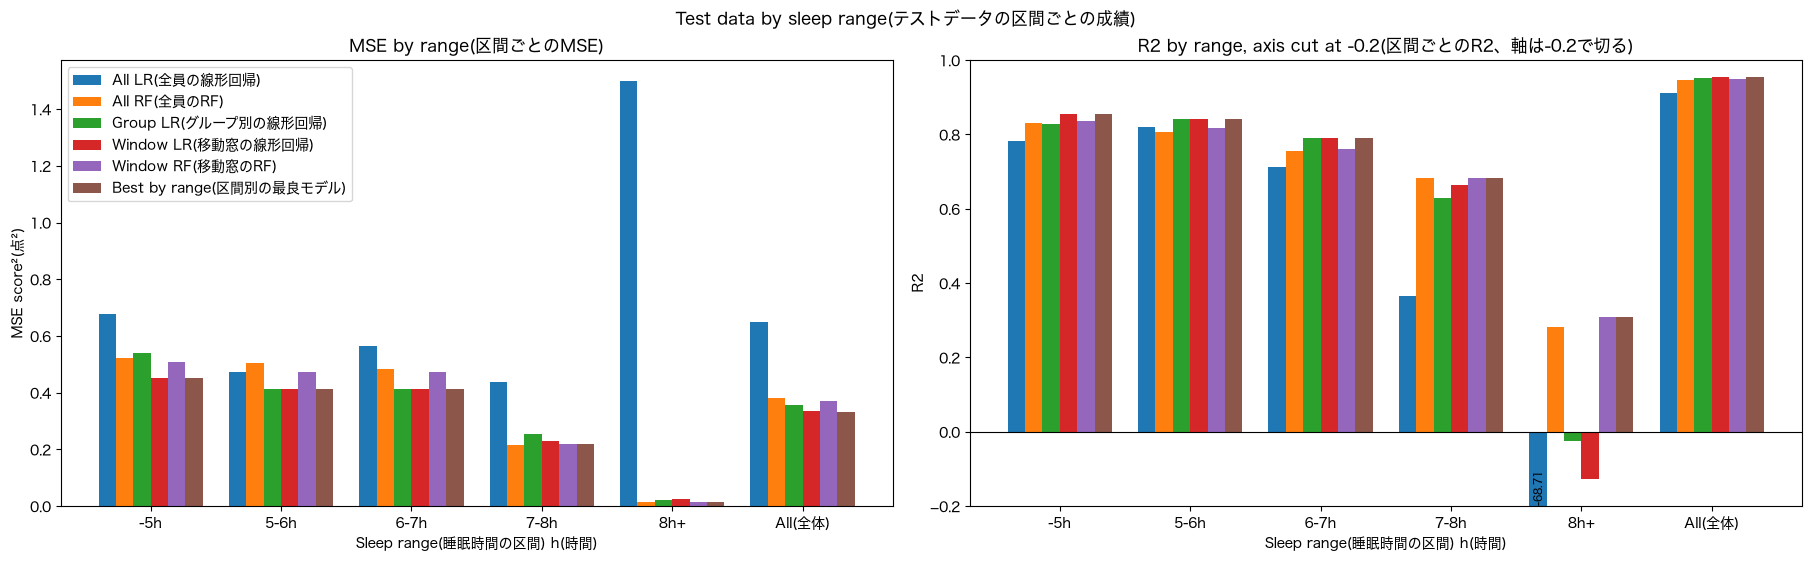

In [31]:
# 学習データ全員で各モデルを学習し、テストデータを予測する
test_pred = pd.DataFrame({name: fit_predict(X_train, y_train, X_test) for name, fit_predict in MODELS.items()}, index=X_test.index)
test_pred[HYBRID] = combine_by_range(test_pred[MODEL_NAMES], group_test)
EVAL_NAMES = list(test_pred.columns)

# 区間ごとの指標（行：区間、列：モデル）
def metric_by_range(pred_table, y_true, groups, metric):
    return pd.DataFrame({
        name: {col: metric(y_true[range_mask(groups, name)], pred_table.loc[range_mask(groups, name), col]) for col in pred_table.columns}
        for name in RANGES
    }).T

test_mse = metric_by_range(test_pred, y_test, group_test, mean_squared_error)
test_r2 = metric_by_range(test_pred, y_test, group_test, r2_score)
test_range_info = pd.DataFrame({
    "Test N(テストの人数)": [int(range_mask(group_test, n).sum()) for n in RANGES],
    "Fatigue mean(疲労の平均)": [y_test[range_mask(group_test, n)].mean() for n in RANGES],
    "Fatigue var(疲労の分散)": [y_test[range_mask(group_test, n)].var(ddof=0) for n in RANGES],
}, index=RANGES)
test_range_info.index.name = "Range(区間)"

# 全体の交差検証（Step 9）とテストの比べ
cv_vs_test = pd.DataFrame({
    "CV MSE(交差検証MSE)": range_mse.loc[ALL, EVAL_NAMES],
    "Test MSE(テストのMSE)": test_mse.loc[ALL, EVAL_NAMES],
    "CV R2(交差検証のR2)": range_r2_table.loc[ALL, EVAL_NAMES],
    "Test R2(テストのR2)": test_r2.loc[ALL, EVAL_NAMES],
})
cv_vs_test.insert(2, "Test-CV(テスト-交差検証)", cv_vs_test["Test MSE(テストのMSE)"] - cv_vs_test["CV MSE(交差検証MSE)"])
cv_vs_test.index.name = "Model(モデル)"
best_test = test_mse.loc[ALL, EVAL_NAMES].idxmin()

print(f"Train rows(学習の行数):{len(X_train)}")
print(f"Test rows(テストの行数):{len(X_test)}")
print(f"Best test MSE overall(全体でテストのMSEが一番小さいモデル):{best_test}")
print(f"Best test MSE(一番小さいテストのMSE):{test_mse.loc[ALL, best_test]:.5f}")
print()
print("Test ranges(テストの区間):")
print(test_range_info.round(4).to_string())
print()
print("Overall, CV vs test(全体、交差検証とテスト):")
print(cv_vs_test.round(5).to_string())
print()
print("Test MSE by range(区間ごとのテストのMSE) score²(点²):")
print(test_mse.round(5).to_string())
print()
print("Test R2 by range(区間ごとのテストのR2):")
print(test_r2.round(4).to_string())
print()
print("Best model on test by range(区間ごとにテストのMSEが一番小さいモデル):")
print(pd.DataFrame({
    "Chosen in 9-2(9-2で選んだモデル)": best_by_range,
    "Best on test(テストで一番良いモデル)": test_mse.loc[GROUPS, MODEL_NAMES].idxmin(axis=1),
}).to_string())

plot_by_range(test_mse, None, test_r2,
              "Test data by sleep range(テストデータの区間ごとの成績)", f"{FIG_DIR}/range_test.png")

### 10-2:Differences on test and the final model(テストでの差と最終モデル)

- Each model is compared with the moving-window linear regression, the best single model in Step 9(各モデルを、Step 9 で一番良かった単独のモデル＝移動窓の線形回帰と比べる)
- The 1,700 test people are resampled with replacement 2,000 times. Each time, the test MSE difference is computed with the same people for both models(テスト1,700人を重複を許して2,000回選び直し、毎回同じ人で2つのモデルのテストのMSEの差を計算する)
- If the 95% range of the difference does not include 0, the two models differ on test(差の95%の範囲が0を含まなければ、テストで2つのモデルに差があると考える)
- Rule for the final model, fixed before looking at the test result:the best model by range is used only if its 95% range is entirely below 0. Otherwise the simpler moving-window linear regression is used(最終モデルの決め方は、テストの結果を見る前に決めておく：区間別の最良モデルの95%の範囲がすべて0より下のときだけ、それを使う。そうでなければ、より単純な移動窓の線形回帰を使う)

Bootstrap samples(ブートストラップの回数):2000
Reference model(比べる基準のモデル):Window LR(移動窓の線形回帰)
Reference test MSE(基準のモデルのテストのMSE):0.33470

Test MSE difference, model - Window LR(移動窓の線形回帰)(テストのMSEの差、各モデル-基準):
                          Test MSE(テストのMSE)  Difference(差)  CI low(95%の下端)  CI high(95%の上端)  Excludes 0(0を含まない)
Model(モデル)                                                                                                     
All LR(全員の線形回帰)                     0.64775        0.31305         0.26919          0.35687                True
All RF(全員のRF)                       0.38229        0.04758         0.02941          0.06620                True
Group LR(グループ別の線形回帰)                0.35775        0.02304         0.01140          0.03443                True
Window RF(移動窓のRF)                   0.37000        0.03530         0.01835          0.05251                True
Best by range(区間別の最良モデル)            0.33042       -0.00428        -0.01035          0.00181               False

Final model(最終モデル):

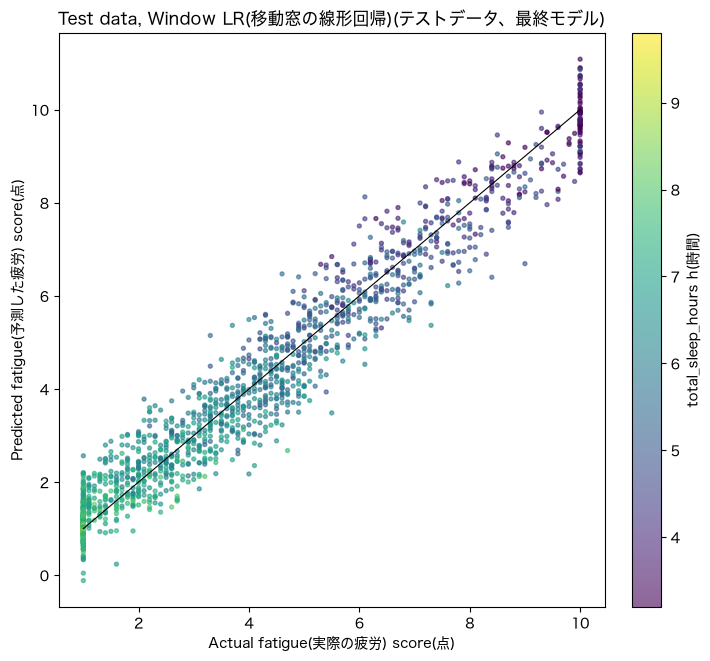

In [32]:
N_TEST_BOOT = 2000
test_rng = np.random.default_rng(RANDOM_STATE)
boot_idx = test_rng.integers(0, len(y_test), (N_TEST_BOOT, len(y_test)))
sq_err = test_pred.sub(y_test, axis=0) ** 2

# 各モデル − 移動窓の線形回帰 のテストのMSEの差（正なら移動窓の線形回帰より悪い）
diff_rows = []
for name in EVAL_NAMES:
    if name == best_single:
        continue
    d = (sq_err[name] - sq_err[best_single]).to_numpy()
    boot = d[boot_idx].mean(axis=1)
    ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
    diff_rows.append({
        "Model(モデル)": name,
        "Test MSE(テストのMSE)": sq_err[name].mean(),
        "Difference(差)": d.mean(),
        "CI low(95%の下端)": ci_low,
        "CI high(95%の上端)": ci_high,
        "Excludes 0(0を含まない)": (ci_low > 0) or (ci_high < 0),
    })
test_diff = pd.DataFrame(diff_rows).set_index("Model(モデル)")

FINAL_MODEL = HYBRID if test_diff.loc[HYBRID, "CI high(95%の上端)"] < 0 else best_single
final_table = pd.DataFrame({
    "Test N(テストの人数)": test_range_info["Test N(テストの人数)"],
    "Test MSE(テストのMSE)": test_mse[FINAL_MODEL],
    "Test R2(テストのR2)": test_r2[FINAL_MODEL],
    "All LR test MSE(全員の線形回帰のテストのMSE)": test_mse["All LR(全員の線形回帰)"],
})
final_table.index.name = "Range(区間)"

print(f"Bootstrap samples(ブートストラップの回数):{N_TEST_BOOT}")
print(f"Reference model(比べる基準のモデル):{best_single}")
print(f"Reference test MSE(基準のモデルのテストのMSE):{sq_err[best_single].mean():.5f}")
print()
print(f"Test MSE difference, model - {best_single}(テストのMSEの差、各モデル-基準):")
with pd.option_context("display.float_format", "{:.5f}".format):
    print(test_diff.to_string())
print()
print(f"Final model(最終モデル):{FINAL_MODEL}")
print(f"Final test MSE(最終モデルのテストのMSE):{test_mse.loc[ALL, FINAL_MODEL]:.5f}")
print(f"Final test R2(最終モデルのテストのR2):{test_r2.loc[ALL, FINAL_MODEL]:.4f}")
print()
print("Final model by range(最終モデルの区間ごとの成績):")
print(final_table.round(5).to_string())

# 図：最終モデルの、テストデータの実際の疲労と予測
fig, ax = plt.subplots(figsize=(7, 6.5), layout="constrained")
sc = ax.scatter(y_test, test_pred[FINAL_MODEL], c=X_test[SLEEP], cmap="viridis", s=8, alpha=0.6)
ax.plot([1, 10], [1, 10], color="black", linewidth=0.8)
ax.set_xlabel("Actual fatigue(実際の疲労) score(点)")
ax.set_ylabel("Predicted fatigue(予測した疲労) score(点)")
ax.set_title(f"Test data, {FINAL_MODEL}(テストデータ、最終モデル)")
fig.colorbar(sc, ax=ax, label="total_sleep_hours h(時間)")
fig.savefig(f"{FIG_DIR}/final_test_pred.png", dpi=150)
plt.show()

## Step 11:Conclusion and limitations(結論と限界)

### 11-1:Answer table(研究課題への答えの表)

- One row per feature:the moving-window linear regression coefficient at each compared center (Step 7), the neighbor pairs where the effect changed (7-3), and the agreement with the random forest SHAP slope (8-2)(特徴量ごとに1行：比べた中心での移動窓の線形回帰の係数（Step 7）、効果が変わった隣どうしの組（7-3）、RF の SHAP の傾きとの一致（8-2）)
- The moving-window linear regression is the final model of Step 10, so its coefficients are the main answer(移動窓の線形回帰は Step 10 の最終モデルなので、その係数を答えの中心にする)

In [33]:
# 比べた中心での係数（行：特徴量、列：中心）
coef_at = window_coef.loc[COMPARE_CENTERS, FEATURES].T
coef_at.columns = [f"{c:g}h" for c in COMPARE_CENTERS]

# 7-3 で95%の範囲が0を含まなかった組
changed = diff_table[diff_table["Excludes 0(0を含まない)"]].groupby("Feature(特徴量)")["Pair(組)"].apply(", ".join)

answer_table = coef_at.copy()
answer_table["Changes at(効果が変わった組)"] = changed.reindex(FEATURES).fillna("none(なし)")
answer_table["RF-LR correlation(RFとLRの相関)"] = rf_lr_compare["Correlation(相関)"]
answer_table["Unit(単位)"] = [UNITS[col] for col in FEATURES]
answer_table.index.name = "Feature(特徴量)"

print(f"Final model(最終モデル):{FINAL_MODEL}")
print(f"Window width(窓の幅) h(時間):{BEST_WIDTH}")
print(f"Final test MSE(最終モデルのテストのMSE):{test_mse.loc[ALL, FINAL_MODEL]:.5f}")
print(f"All LR test MSE(全員の線形回帰のテストのMSE):{test_mse.loc[ALL, 'All LR(全員の線形回帰)']:.5f}")
print(f"Features whose effect changed at least once(効果が1回以上変わった特徴量):{int((answer_table['Changes at(効果が変わった組)'] != 'none(なし)').sum())}/{len(FEATURES)}")
print(f"Comparisons excluding 0(0を含まなかった比べ):{int(diff_table['Excludes 0(0を含まない)'].sum())}/{len(diff_table)}")
print()
print("Answer table, coefficient per 1 unit at each window center(研究課題への答え、各中心での1単位あたりの係数) score(点):")
print(answer_table.round(4).to_string())

Final model(最終モデル):Window LR(移動窓の線形回帰)
Window width(窓の幅) h(時間):1.0
Final test MSE(最終モデルのテストのMSE):0.33470
All LR test MSE(全員の線形回帰のテストのMSE):0.64775
Features whose effect changed at least once(効果が1回以上変わった特徴量):7/10
Comparisons excluding 0(0を含まなかった比べ):14/50

Answer table, coefficient per 1 unit at each window center(研究課題への答え、各中心での1単位あたりの係数) score(点):
                              3h      4h      5h      6h      7h      8h Changes at(効果が変わった組)  RF-LR correlation(RFとLRの相関)               Unit(単位)
Feature(特徴量)                                                                                                                                     
bedtime_phone_minutes     0.0066  0.0044  0.0053  0.0042  0.0052  0.0003                7h→8h                       0.2443                 min(分)
screen_brightness_pct     0.0084  0.0070  0.0058  0.0067  0.0048  0.0022                7h→8h                       0.9363                      %
blue_light_filter_active -0.2555 -0.1938 -0.1841 -0.1443 -0.0966 -0.

### 11-2:Numbers for the limitations(限界に関わる数値)

- Fatigue piles up at 1.0 and 10.0, and sleep piles up at its floor(疲労は1.0と10.0に、睡眠時間は最小値にたまっている)

In [34]:
limit_table = pd.DataFrame({
    "Train N(学習の人数)": [int(range_mask(group_train, n).sum()) for n in RANGES],
    "Fatigue 1.0 ratio(疲労1.0の割合)": [y_train[range_mask(group_train, n)].eq(1.0).mean() for n in RANGES],
    "Fatigue 10.0 ratio(疲労10.0の割合)": [y_train[range_mask(group_train, n)].eq(10.0).mean() for n in RANGES],
    f"Sleep {SLEEP_FLOOR:g}h ratio(睡眠{SLEEP_FLOOR:g}時間の割合)": [X_train.loc[range_mask(group_train, n), SLEEP].eq(SLEEP_FLOOR).mean() for n in RANGES],
}, index=RANGES)
limit_table.index.name = "Range(区間)"

print(f"People at sleep {SLEEP_FLOOR:g}h, all data(睡眠{SLEEP_FLOOR:g}時間の人数、全データ):{int(df[SLEEP].eq(SLEEP_FLOOR).sum())}")
print(f"People at fatigue 1.0, all data(疲労1.0の人数、全データ):{int(df[TARGET].eq(1.0).sum())}")
print(f"People at fatigue 10.0, all data(疲労10.0の人数、全データ):{int(df[TARGET].eq(10.0).sum())}")
print(f"Windows with same fatigue, not fitted(疲労が全員同じで係数のない窓):{len(window_lr) - len(lr_centers)}")
print()
print("Training data by range(学習データの区間ごと):")
print(limit_table.round(4).to_string())

People at sleep 3.2h, all data(睡眠3.2時間の人数、全データ):242
People at fatigue 1.0, all data(疲労1.0の人数、全データ):2110
People at fatigue 10.0, all data(疲労10.0の人数、全データ):314
Windows with same fatigue, not fitted(疲労が全員同じで係数のない窓):6

Training data by range(学習データの区間ごと):
           Train N(学習の人数)  Fatigue 1.0 ratio(疲労1.0の割合)  Fatigue 10.0 ratio(疲労10.0の割合)  Sleep 3.2h ratio(睡眠3.2時間の割合)
Range(区間)                                                                                                          
-5h                  1371                       0.0000                         0.1758                        0.1422
5-6h                 1456                       0.0027                         0.0021                        0.0000
6-7h                 1678                       0.0912                         0.0000                        0.0000
7-8h                 1509                       0.5229                         0.0000                        0.0000
8h+                   786                       0.9402

### 11-3:Conclusion(結論)

**RQ:How does the effect of each behavioural factor on next-day fatigue change with sleep duration?(各要素が翌日の疲労に与える影響は、睡眠時間によってどのように変わるか？)**

**Final model(最終モデル)**

- The moving-window linear regression (width 1.0h) is the final model. Test MSE 0.33470, R² 0.9543, about half of one linear regression for everyone (0.64775)(移動窓の線形回帰（幅1.0時間）を最終モデルにする。テストのMSEは0.33470、R²は0.9543で、全員で1つの線形回帰（0.64775）の約半分)
- The best model by range had test MSE 0.33042, but the 95% range of its difference from the moving-window linear regression (-0.01035 to 0.00181) includes 0, so the simpler model is kept by the rule fixed in 10-2(区間別の最良モデルのテストのMSEは0.33042だったが、移動窓の線形回帰との差の95%の範囲（-0.01035〜0.00181）が0を含むので、10-2 で決めたルールにより単純な方を使う)
- One effect per feature for everyone is not enough:the effects change with sleep(全員に1つの効果を当てはめるだけでは足りない。効果は睡眠時間によって変わる)

**How the effects change(効果の変わり方)** (7 of 10 features changed at least once; 14 of 50 neighbor comparisons exclude 0, against about 2.5 expected by chance(10特徴量のうち7つで1回以上変わった。隣どうしの比べ50回のうち14回で0を含まず、偶然の目安2.5回より多い))

1. Sleep-related factors are strongest at 4-6h and weaken from 6h to 8h(睡眠に関係する要因は4〜6時間で一番強く、6時間から8時間にかけて弱まる)
   - sleep_latency_min:0.0397 per min at 6h → 0.0135 at 8h(寝つくまでの時間：6時間で1分あたり0.0397点 → 8時間で0.0135点)
   - total_sleep_hours:-1.25 per h at 4-6h → -0.23 at 8h(睡眠時間：4〜6時間で1時間あたり-1.25点 → 8時間で-0.23点)
   - morning_alarm_snoozes:0.448 per time at 5h → 0.122 at 8h(スヌーズ：5時間で1回あたり0.448点 → 8時間で0.122点)
   - deep_sleep_pct:-0.083 per % at 5-6h → -0.023 at 8h(深い睡眠：5〜6時間で1%あたり-0.083点 → 8時間で-0.023点)
2. Phone use and caffeine stay about the same up to 7h and become smaller from 7h to 8h. Screen brightness also drops from 7h to 8h, but it already goes down slowly before 7h(スマホとカフェインは7時間まではほぼ同じで、7時間から8時間で小さくなる。画面の明るさも7時間から8時間で小さくなるが、7時間までにも少しずつ下がっている)
   - bedtime_phone_minutes:0.0052 per min at 7h → 0.0003 at 8h(寝る前のスマホ：7時間で1分あたり0.0052点 → 8時間で0.0003点)
   - caffeine_post_5pm_mg:0.0053 per mg at 7h → 0.0023 at 8h(カフェイン：7時間で1mgあたり0.0053点 → 8時間で0.0023点)
   - screen_brightness_pct:0.0084 per % at 3h → 0.0048 at 7h with no clear single step, then 0.0022 at 8h(画面の明るさ：3時間で1%あたり0.0084点 → 7時間で0.0048点。1時間ごとの差ははっきりしない。8時間で0.0022点)
   - Caffeine also rises from 4h to 5h, but its range only just excludes 0 (lower end 0.0001), so this may be chance(カフェインは4→5時間でも上がるが、範囲の下端が0.0001でぎりぎりなので、偶然かもしれない)
3. Blue light filter, physical activity and REM sleep show no change between neighbors(ブルーライトフィルター、運動、レム睡眠は、隣どうしで変わるとは言えない)
   - The blue light filter coefficient moves from -0.26 at 3h to -0.08 at 8h, but no single step is clear(ブルーライトフィルターの係数は3時間の-0.26から8時間の-0.08へ動くが、1時間ごとの差ははっきりしない)
   - Only neighbors 1h apart were compared, so a slow change over several hours is not tested (see 11-4)(比べたのは1時間となりの窓どうしだけなので、数時間かけたゆっくりした変化は確かめていない（11-4 を参照）)
4. All effects shrink above 7h partly because fatigue cannot go below 1.0:52.3% of 7-8h and 94.0% of 8h+ training people have fatigue 1.0(7時間以上ですべての効果が小さくなるのは、疲労が1.0より下がらないことも理由。学習データで疲労1.0の人は7〜8時間で52.3%、8時間以上で94.0%)
5. The random forest agrees:its SHAP slopes correlate with the linear regression curves at 0.89-0.99 for 6 features and 0.877 for caffeine. Agreement is low for phone use (0.244), physical activity (0.336) and REM sleep (0.665). For phone use, its strong correlation with sleep latency may be the reason (see 11-4)(RF も同じ形を示す。SHAP の傾きと線形回帰の曲線の相関は6つの特徴量で0.89〜0.99、カフェインで0.877。スマホ（0.244）、運動（0.336）、レム睡眠（0.665）は一致が低い。スマホは、寝つくまでの時間との相関が強いことが理由かもしれない（11-4 を参照）)

### 11-4:Limitations(限界)

- **Floor and ceiling of fatigue(疲労の下限と上限)**:2,110 people have fatigue 1.0 and 314 have 10.0. Linear regression does not know these limits, so effects near them are made smaller. A Tobit model would treat them, but was not used(疲労1.0が2,110人、10.0が314人いる。線形回帰はこの上下限を知らないので、その近くの効果は小さく出る。Tobit 回帰なら扱えるが、使っていない)
- **Sleep floor at 3.2h(睡眠時間の下限3.2時間)**:242 people have exactly 3.2h (14.2% of the -5h training group, 69.1% of the 3.0h window), so the 3.0h window and the 3h→4h comparisons are unstable(ちょうど3.2時間の人が242人いて、-5h の学習データの14.2%、3.0時間の窓の69.1%を占める。3.0時間の窓と3→4時間の比べは不安定)
- **No answer above about 9h(約9時間以上は答えられない)**:6 windows from 9.0h have the same fatigue for everyone, so they have no coefficients(9.0時間からの6つの窓は疲労が全員同じなので、係数がない)
- **Correlated features and features in between(相関の強い特徴量と、間にはさまる特徴量)**:in all data, bedtime_phone_minutes and sleep_latency_min have r=0.858, and total_sleep_hours and morning_alarm_snoozes have r=-0.831 (Step 2). A coefficient is the difference when the other features are the same, so the part of phone use that works through sleep latency is not in the phone coefficient. This may also be why the random forest agrees little for phone use (0.244). Sleep latency, deep sleep, REM sleep and snoozes are results of sleep rather than habits(全データで、寝る前のスマホと寝つくまでの時間の相関は0.858、睡眠時間とスヌーズの相関は-0.831（Step 2）。係数はほかの特徴量が同じときの差なので、スマホが寝つくまでの時間を通して疲労を変える分は、スマホの係数に入らない。スマホで RF との一致が低い（0.244）のも、これが理由かもしれない。寝つくまでの時間、深い睡眠、レム睡眠、スヌーズは、習慣というより睡眠の結果である)
- **Only neighbors are compared(隣どうししか比べていない)**:7-3 compares windows 1h apart. A slow change over several hours, such as blue light filter (-0.26 at 3h to -0.08 at 8h) or screen brightness (0.0084 at 3h to 0.0048 at 7h), is not tested. "No change shown" means only that no 1h step is clear(7-3 は1時間となりの窓どうしだけを比べている。ブルーライトフィルター（3時間の-0.26から8時間の-0.08）や画面の明るさ（3時間の0.0084から7時間の0.0048）のような、数時間かけたゆっくりした変化は確かめていない。「変わるとは言えない」は、1時間ごとの差がはっきりしないという意味だけ)
- **200 bootstrap samples(ブートストラップは200回)**:each end of a 95% range is set by only 5 of the 200 values. Borderline results such as caffeine 4h→5h (lower end 0.0001) may change with more samples(95%の範囲の端は、200個のうち5個だけで決まる。カフェインの4→5時間（下端0.0001）のようなぎりぎりの結果は、回数を増やすと変わりうる)
- **Multiple comparisons(多重比較)**:50 neighbor comparisons are made without correction. 14 exceed the 2.5 expected by chance, but any single borderline one may be chance(隣どうしの比べ50回は補正していない。14回は偶然の目安2.5回より多いが、ぎりぎりの1つ1つは偶然かもしれない)
- **Bands are pointwise(帯は点ごと)**:the 95% bands of 7-2 are for each window, not for the whole curve at once(7-2 の95%の帯は窓ごとのもので、曲線全体を同時に囲むものではない)
- **No band for the random forest(RF には帯がない)**:the bootstrap would take about 6 hours, so the RF curves are checked only by agreement with the linear regression(ブートストラップに約6時間かかるので、RF の曲線は線形回帰との一致でしか確かめていない)
- **Final model is weak at 8h+(最終モデルは8時間以上で弱い)**:its test R² there is -0.127, worse than predicting the mean for everyone, while the moving-window random forest gets 0.309. Predictions can also fall below 1.0 or above 10.0 (figures/final_test_pred.png), because they are not cut to the score range(8時間以上でのテストのR²は-0.127で、全員に平均を予測するより悪い。移動窓のRFは0.309。また、予測を点数の範囲で切っていないので、1.0より下や10.0より上になる人がいる（figures/final_test_pred.png）)
- **Per-range model choice is within CV noise(区間ごとのモデルの選択は交差検証のノイズの範囲内)**:in 9-3 no chosen model beat the second one (Holm p ≥ 0.38)(9-3 で、選んだモデルが2番目のモデルより有意に良い区間はなかった（Holm補正後 p ≥ 0.38）)
- **CV of Step 9 is a little too good(Step 9 の交差検証の成績は少し良く出る)**:the window width and the random forest settings were chosen with the same training data. The order of the models did not change on test data(窓の幅と RF の設定を、同じ学習データで選んでいるため。テストデータでもモデルの順番は変わらなかった)
- **SHAP on training data(SHAP は学習データで計算)**:the random forests fit the training people closely, so SHAP slopes may be a little larger than they would be for new people(RF は学習データの人に強く合わせているので、SHAP の傾きは新しい人で計算するより少し大きく出るかもしれない)
- **Window width chosen with linear regression(窓の幅は線形回帰で選んだ)**:the random forest uses the same 1.0h width without its own choice(RF も自分で選ばずに同じ1.0時間の幅を使う)
- **No causal claims(因果関係は言えない)**:the data is simulated and observational. A coefficient shows how fatigue differs between people, not what happens if one person changes a habit(データはシミュレーションで、観察データの形をしている。係数は人どうしの疲労の違いを表すもので、1人が習慣を変えたらどうなるかを表すものではない)

## Appendix:Results of the original 1-hour groups(付録：元の計画の1時間グループの結果)

- The original plan compared one linear regression per sleep group (-5h, 5-6h, 6-7h, 7-8h, 8h+)(元の計画は、睡眠時間グループごとに線形回帰を1つずつ作って比べるものだった)
- Same training data as above. Coefficients and 95% CI from statsmodels OLS(上と同じ学習データ。係数と95%信頼区間は statsmodels の OLS で出す)
- Each group is drawn at its mean sleep on top of the moving-window curves of Step 7(各グループは、平均睡眠時間の位置に Step 7 の移動窓の曲線と重ねて描く)
- The group model is the "Group LR" of Steps 9-10. Its test MSE 0.35775 is worse than the moving-window linear regression (difference 95% range 0.01140 to 0.03443)(このモデルは Step 9〜10 の「グループ別の線形回帰」。テストのMSE 0.35775 は移動窓の線形回帰より悪い（差の95%の範囲0.01140〜0.03443）)

Groups(グループ):
-5h:N(人数)=1371,Mean sleep(平均睡眠時間)=4.160h,R2=0.8438
5-6h:N(人数)=1456,Mean sleep(平均睡眠時間)=5.521h,R2=0.8306
6-7h:N(人数)=1678,Mean sleep(平均睡眠時間)=6.493h,R2=0.7788
7-8h:N(人数)=1509,Mean sleep(平均睡眠時間)=7.461h,R2=0.6376
8h+:N(人数)=786,Mean sleep(平均睡眠時間)=8.544h,R2=0.2414

Coefficient[95% CI](係数［95%信頼区間］):
                                               -5h                      5-6h                      6-7h                      7-8h                      8h+
Feature(特徴量)                                                                                                                                             
bedtime_phone_minutes        0.0062[0.0043,0.0081]      0.004[0.0022,0.0059]     0.0047[0.0028,0.0067]     0.0038[0.0019,0.0056]   0.0007[-0.0004,0.0018]
screen_brightness_pct         0.0071[0.005,0.0092]      0.0062[0.0045,0.008]     0.0058[0.0043,0.0074]     0.0038[0.0025,0.0051]    0.0011[0.0004,0.0017]
blue_light_filter_active  -0.2133[-0.2915,-0.1351]   -0.1414[-0.2089,-0.074]  

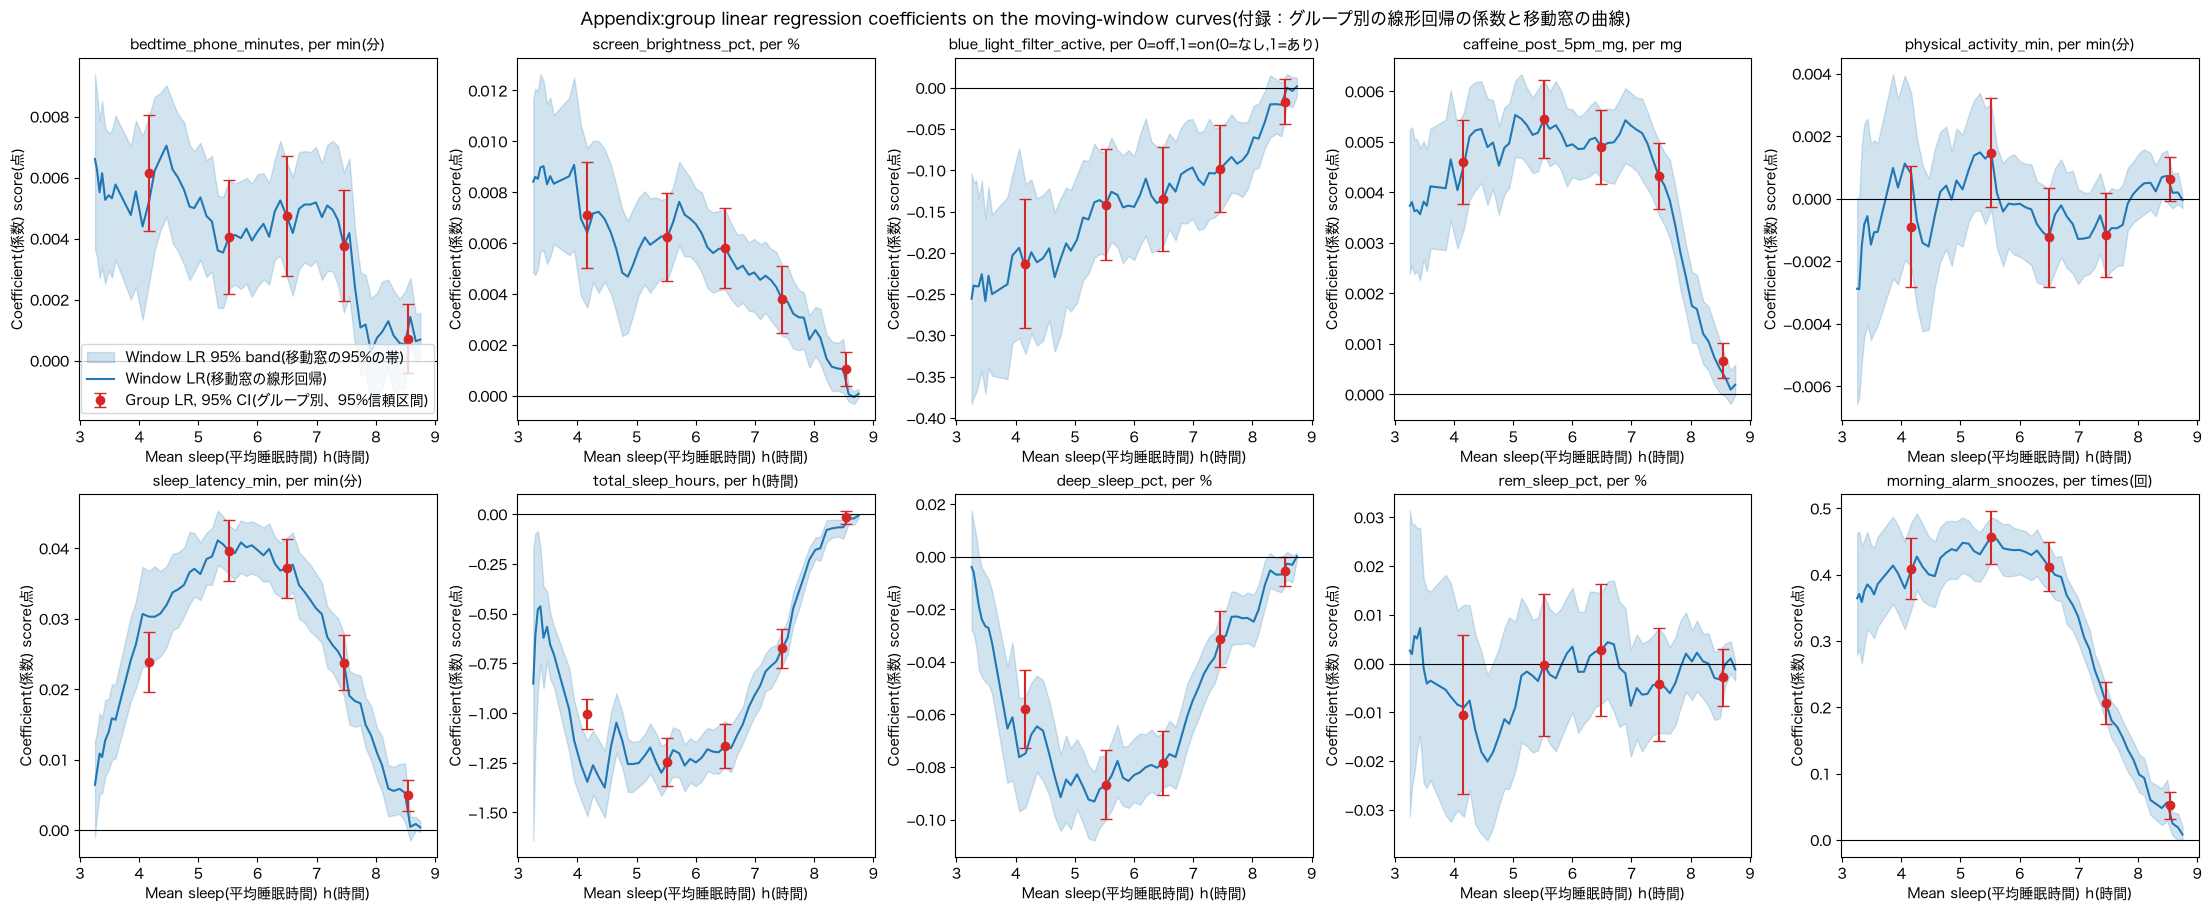

In [35]:
import statsmodels.api as sm

# 睡眠時間グループごとに statsmodels の OLS で線形回帰を作り、係数の95%信頼区間を出す（9-1 のグループ別の線形回帰と同じモデル）
group_ols = {name: sm.OLS(y_train[group_train == name], sm.add_constant(X_train[group_train == name])).fit() for name in GROUPS}
group_coef = pd.DataFrame({name: res.params[FEATURES] for name, res in group_ols.items()})
group_ci_low = pd.DataFrame({name: res.conf_int().loc[FEATURES, 0] for name, res in group_ols.items()})
group_ci_high = pd.DataFrame({name: res.conf_int().loc[FEATURES, 1] for name, res in group_ols.items()})
group_p = pd.DataFrame({name: res.pvalues[FEATURES] for name, res in group_ols.items()})
group_mean_sleep = X_train[SLEEP].groupby(group_train, observed=False).mean()
for table in [group_coef, group_p]:
    table.index.name = "Feature(特徴量)"
ci_text = group_coef.round(4).astype(str) + "[" + group_ci_low.round(4).astype(str) + "," + group_ci_high.round(4).astype(str) + "]"

# 隣どうしのグループで、95%信頼区間が重ならない特徴量（重ならなければ、はっきり違うと言える）
group_pairs = list(zip(GROUPS[:-1], GROUPS[1:]))
no_overlap = pd.DataFrame({
    f"{a}→{b}": (group_ci_high[a] < group_ci_low[b]) | (group_ci_high[b] < group_ci_low[a]) for a, b in group_pairs
})
no_overlap.index.name = "Feature(特徴量)"

print("Groups(グループ):")
for name, res in group_ols.items():
    print(f"{name}:N(人数)={int(res.nobs)},Mean sleep(平均睡眠時間)={group_mean_sleep[name]:.3f}h,R2={res.rsquared:.4f}")
print()
print("Coefficient[95% CI](係数［95%信頼区間］):")
print(ci_text.to_string())
print()
print("p-value(p値):")
print(group_p.map(lambda p: f"{p:.2e}").to_string())
print()
print("95% CI does not overlap between neighboring groups(隣どうしのグループで95%信頼区間が重ならない):")
print(no_overlap.to_string())

# 図：移動窓の線形回帰の係数と帯（Step 7）に、グループ別の係数と95%信頼区間を重ねる。グループの点は平均睡眠時間の位置に置く
fig, axes = plt.subplots(2, 5, figsize=(22, 9), layout="constrained")
for ax, col in zip(axes.flatten(), FEATURES):
    ax.fill_between(mean_sleep, band_low[col], band_high[col], color="tab:blue", alpha=0.2, label="Window LR 95% band(移動窓の95%の帯)")
    ax.plot(mean_sleep, window_coef[col], color="tab:blue", label="Window LR(移動窓の線形回帰)")
    est = group_coef.loc[col, GROUPS]
    ax.errorbar(group_mean_sleep[GROUPS], est, yerr=[est - group_ci_low.loc[col, GROUPS], group_ci_high.loc[col, GROUPS] - est],
                fmt="o", capsize=4, color="tab:red", label="Group LR, 95% CI(グループ別、95%信頼区間)")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{col}, per {UNITS[col]}", fontsize=10)
    ax.set_xlabel("Mean sleep(平均睡眠時間) h(時間)")
    ax.set_ylabel("Coefficient(係数) score(点)")
axes[0, 0].legend()
plt.suptitle("Appendix:group linear regression coefficients on the moving-window curves(付録：グループ別の線形回帰の係数と移動窓の曲線)")
fig.savefig(f"{FIG_DIR}/coef_by_group.png", dpi=150)
plt.show()